In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import probplot

#basic imports

In [2]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
import warnings

warnings.filterwarnings("ignore")


In [4]:
file_list = ['UNRATE.csv','UMCSENT.csv','T10Y2Y.csv','PPIACO.csv','PAYEMS.csv','M2SL.csv','INDPRO.csv','HOUST.csv','FEDFUNDS.csv','DCOILWTICO.csv','CPIAUCSL.csv']
common_column = 'observation_date'

base_df = pd.read_csv(f'Data/{file_list[0]}')
for i in file_list[1:]:
  base_df = pd.merge(base_df, pd.read_csv(f'Data/{i}'), on=common_column,how ='inner')
base_df.set_index(common_column,inplace=True)

#his merges all csvs into a single base dataframe while including all NaNs and setting observation date as index - needs preprocessing

In [5]:
display(base_df.tail())
#visual inspection

,UNRATE,UMCSENT,T10Y2Y,PPIACO,PAYEMS,M2SL,INDPRO,HOUST,FEDFUNDS,DCOILWTICO,CPIAUCSL
observation_date,,,,,,,,,,,
2026-04-01,4.3,49.8,0.52,282.722,158798,22728.0,102.5768,1414,3.64,101.90,332.407
2026-05-01,4.3,44.8,0.51,290.281,158861,22980.9,102.6925,1182,3.63,105.38,333.979
2026-06-01,4.2,49.5,0.42,285.795,158892,23077.7,102.9673,1439,3.63,95.96,332.568
2026-07-01,4.1,55.2,0.31,284.837,158882,23177.4,103.1675,1369,3.63,69.74,332.813
2026-09-01,4.2,48.1,0.40,294.473,159128,23413.9,103.8458,1191,3.75,91.48,336.298


In [6]:
inflation = pd.read_csv('Data/CPIAUCSL.csv')
inflation.set_index('observation_date',inplace=True)
inflation.rename(columns = {'CPIAUCSL':'INFLATION'}, inplace = True)
inflation['INFLATION'] = ((inflation['INFLATION']/inflation['INFLATION'].shift(12))-1)*100
inflation.dropna(inplace=True)
#defining inflation as the annual growth of cpiaucsl

In [7]:
display(inflation.head())

,INFLATION
observation_date,
1948-01-01,10.242086
1948-02-01,9.481961
1948-03-01,6.818182
1948-04-01,8.272727
1948-05-01,9.384966


In [8]:
inflation.to_csv('Data/INFLATION.csv')

In [9]:
monthun = pd.read_csv('Data/UNRATE.csv')
monthun.set_index('observation_date',inplace=True)
monthun.rename(columns = {'UNRATE':'UNCHANGE'}, inplace = True)
monthun['UNCHANGE'] = (monthun['UNCHANGE']-monthun['UNCHANGE'].shift(1))
monthun.dropna(inplace=True)
#defining unchange as the monthly change in unrate

In [10]:
display(monthun.head())

,UNCHANGE
observation_date,
1948-02-01,0.4
1948-03-01,0.2
1948-04-01,-0.1
1948-05-01,-0.4
1948-06-01,0.1


In [11]:
monthun.to_csv('Data/UNCHANGE.csv')

In [12]:
#similar to inflation - building new features with observation date as indices
growind = pd.read_csv('Data/INDPRO.csv')
growind.set_index('observation_date',inplace=True)
growind.rename(columns = {'INDPRO':'GROWIND'}, inplace = True)
growind['GROWIND'] = ((growind['GROWIND']/growind['GROWIND'].shift(12))-1)*100
growind.dropna(inplace=True)

In [13]:
display(growind.head())

,GROWIND
observation_date,
1920-01-01,15.470157
1920-02-01,20.809273
1920-03-01,22.023520
1920-04-01,13.449594
1920-05-01,15.699018


In [14]:
growind.to_csv('Data/GROWIND.csv')

In [15]:
growpay = pd.read_csv('Data/PAYEMS.csv')
growpay.set_index('observation_date',inplace=True)
growpay.rename(columns = {'PAYEMS':'GROWPAY'}, inplace = True)
growpay['GROWPAY'] = ((growpay['GROWPAY']/growpay['GROWPAY'].shift(12))-1)*100
growpay.dropna(inplace=True)

In [16]:
display(growpay.head())

,GROWPAY
observation_date,
1940-01-01,5.614410
1940-02-01,5.365449
1940-03-01,5.102378
1940-04-01,5.339935
1940-05-01,5.214694


In [17]:
growpay.to_csv('Data/GROWPAY.csv')

In [18]:
growprod = pd.read_csv('Data/PPIACO.csv')
growprod.set_index('observation_date',inplace=True)
growprod.rename(columns = {'PPIACO':'GROWPROD'}, inplace = True)
growprod['GROWPROD'] = ((growprod['GROWPROD']/growprod['GROWPROD'].shift(12))-1)*100
growprod.dropna(inplace=True)

In [19]:
display(growprod.head())

,GROWPROD
observation_date,
1914-01-01,-2.479339
1914-02-01,-1.666667
1914-03-01,-2.500000
1914-04-01,-2.500000
1914-05-01,-2.521008


In [20]:
growprod.to_csv('Data/GROWPROD.csv')

In [21]:
growoil = pd.read_csv('Data/DCOILWTICO.csv')
growoil.set_index('observation_date',inplace=True)
growoil.rename(columns = {'DCOILWTICO':'GROWOIL'}, inplace = True)
growoil['GROWOIL'] = ((growoil['GROWOIL']/growoil['GROWOIL'].shift(12))-1)*100
growoil.dropna(inplace=True)

In [22]:
display(growoil.head())

,GROWOIL
observation_date,
1986-01-20,-16.549296
1986-01-21,-20.730769
1986-01-22,-23.671315
1986-01-23,-22.901354
1986-01-24,-24.816390


In [23]:
growoil.to_csv('Data/GROWOIL.csv')

In [24]:
file_list = ['UNRATE.csv','PPIACO.csv','PAYEMS.csv','M2SL.csv','INDPRO.csv','HOUST.csv','FEDFUNDS.csv','CPIAUCSL.csv','INFLATION.csv','UNCHANGE.csv','GROWIND.csv','GROWPAY.csv','GROWPROD.csv']
common_column = 'observation_date'
ranged_df = pd.read_csv(f'Data/{file_list[0]}')
for i in file_list[1:]:
  ranged_df = pd.merge(ranged_df, pd.read_csv(f'Data/{i}'), on=common_column,how ='inner')
ranged_df.set_index(common_column,inplace=True)
ranged_df.index = pd.to_datetime(ranged_df.index)

#ranged_df was a data-frame initially used due to the smaller date range for t10y2y and dcoilwtico

In [25]:
display(ranged_df.head())

,UNRATE,PPIACO,PAYEMS,M2SL,INDPRO,HOUST,FEDFUNDS,CPIAUCSL,INFLATION,UNCHANGE,GROWIND,GROWPAY,GROWPROD
observation_date,,,,,,,,,,,,,
1959-01-01,6.0,31.7,52478,286.6,21.9998,1657,2.48,29.01,1.291899,-0.2,8.933629,0.771949,0.634921
1959-02-01,5.9,31.7,52688,287.7,22.4306,1667,2.43,29.00,1.045296,-0.1,13.487614,2.156042,0.634921
1959-03-01,5.6,31.7,53014,289.2,22.7538,1620,2.80,28.97,0.346380,-0.3,16.551671,3.343145,0.000000
1959-04-01,5.2,31.8,53321,290.1,23.2384,1590,2.96,28.98,0.138217,-0.4,21.037746,4.495659,0.632911
1959-05-01,5.1,31.8,53550,292.2,23.5885,1498,2.90,29.04,0.345543,-0.1,21.666718,5.177358,0.315457


In [26]:
df_monthly = ranged_df.asfreq('MS')
display(df_monthly.head())
#enforces a monthly frequency for even evaluation on shifted metrics

,UNRATE,PPIACO,PAYEMS,M2SL,INDPRO,HOUST,FEDFUNDS,CPIAUCSL,INFLATION,UNCHANGE,GROWIND,GROWPAY,GROWPROD
observation_date,,,,,,,,,,,,,
1959-01-01,6.0,31.7,52478.0,286.6,21.9998,1657.0,2.48,29.01,1.291899,-0.2,8.933629,0.771949,0.634921
1959-02-01,5.9,31.7,52688.0,287.7,22.4306,1667.0,2.43,29.00,1.045296,-0.1,13.487614,2.156042,0.634921
1959-03-01,5.6,31.7,53014.0,289.2,22.7538,1620.0,2.80,28.97,0.346380,-0.3,16.551671,3.343145,0.000000
1959-04-01,5.2,31.8,53321.0,290.1,23.2384,1590.0,2.96,28.98,0.138217,-0.4,21.037746,4.495659,0.632911
1959-05-01,5.1,31.8,53550.0,292.2,23.5885,1498.0,2.90,29.04,0.345543,-0.1,21.666718,5.177358,0.315457


In [27]:
file_list = ['UNRATE.csv','UMCSENT.csv','T10Y2Y.csv','PPIACO.csv','PAYEMS.csv','M2SL.csv','INDPRO.csv','HOUST.csv','FEDFUNDS.csv','DCOILWTICO.csv','CPIAUCSL.csv','INFLATION.csv','UNCHANGE.csv','GROWIND.csv','GROWPAY.csv','GROWPROD.csv','GROWOIL.csv']
common_column = 'observation_date'
core_df = pd.read_csv(f'Data/{file_list[0]}')
for i in file_list[1:]:
  core_df = pd.merge(core_df, pd.read_csv(f'Data/{i}'), on=common_column,how ='inner')
core_df.set_index(common_column,inplace=True)
#this is the main dataframe used - it merges all datsets using an inner join to only keep rows with non-NaN values

In [28]:
display(core_df.head())

,UNRATE,UMCSENT,T10Y2Y,PPIACO,PAYEMS,M2SL,INDPRO,HOUST,FEDFUNDS,DCOILWTICO,CPIAUCSL,INFLATION,UNCHANGE,GROWIND,GROWPAY,GROWPROD,GROWOIL
observation_date,,,,,,,,,,,,,,,,,
1986-04-01,7.1,96.2,0.48,99.6,99121,2558.1,55.0413,1933,6.99,11.13,108.7,1.588785,-0.1,0.539584,2.146582,-3.581801,-11.314741
1986-05-01,7.2,94.8,0.60,100.0,99248,2585.7,55.1226,1854,6.85,13.80,109.0,1.679104,0.1,0.541901,1.989477,-3.381643,8.490566
1986-08-01,6.9,94.9,0.78,99.3,99588,2646.5,55.1567,1807,6.17,11.56,109.6,1.575533,-0.1,0.824780,1.786590,-3.310613,-8.832808
1986-10-01,7.0,95.6,1.05,99.7,100121,2687.1,55.5332,1681,5.85,15.23,110.2,1.566820,0.0,1.486297,1.921961,-3.109815,6.429071
1986-12-01,6.6,89.1,0.93,99.7,100509,2728.0,56.2845,1833,6.91,15.29,110.8,1.187215,-0.3,1.521071,1.926802,-3.764479,-1.672026


# **1. Inspection of Feature Datasets**

In [29]:
file_list = ['UNRATE.csv','UMCSENT.csv','T10Y2Y.csv','PPIACO.csv','PAYEMS.csv','M2SL.csv','INDPRO.csv','HOUST.csv','FEDFUNDS.csv','DCOILWTICO.csv','CPIAUCSL.csv','INFLATION.csv','UNCHANGE.csv','GROWIND.csv','GROWPAY.csv','GROWPROD.csv','GROWOIL.csv']
analysis_df = pd.DataFrame(index = ['Start Date','End Date','Data Type','Missing Values','Maximum','Minimum','Mean','Median','Standard Deviation','Observation Frequency'],columns = file_list)

In [35]:
for column in file_list:
 column2 = column[:-4]
 tempdata = pd.read_csv(f'Data/{column}')
 analysis_df.loc['Start Date', column] = tempdata['observation_date'].min()
 analysis_df.loc['End Date', column] = tempdata['observation_date'].max()
 analysis_df.loc['Data Type', column] = tempdata[column2].dtype
 analysis_df.loc['Missing Values', column] = tempdata[column2].isna().sum()
 analysis_df.loc['Observation Frequency', column] = pd.to_datetime(tempdata['observation_date'][1])-pd.to_datetime(tempdata['observation_date'][0])
 analysis_df.loc['Maximum', column] = tempdata[column2].max()
 analysis_df.loc['Minimum', column] = tempdata[column2].min()
 analysis_df.loc['Mean', column] = tempdata[column2].mean()
 analysis_df.loc['Median', column] = tempdata[column2].median()
 analysis_df.loc['Standard Deviation', column] = tempdata[column2].std()

# builds an analysis dataframe that describes the initial inspection statistics for each feature

In [36]:
display(analysis_df)

,UNRATE.csv,UMCSENT.csv,T10Y2Y.csv,PPIACO.csv,PAYEMS.csv,M2SL.csv,INDPRO.csv,HOUST.csv,FEDFUNDS.csv,DCOILWTICO.csv,CPIAUCSL.csv,INFLATION.csv,UNCHANGE.csv,GROWIND.csv,GROWPAY.csv,GROWPROD.csv,GROWOIL.csv
Start Date,1948-01-01,1952-11-01,1976-06-01,1913-01-01,1939-01-01,1959-01-01,1919-01-01,1959-01-01,1954-07-01,1986-01-02,1947-01-01,1948-01-01,1948-02-01,1920-01-01,1940-01-01,1914-01-01,1986-01-20
End Date,2026-10-01,2026-10-01,2026-11-20,2026-10-01,2026-10-01,2026-09-01,2026-10-01,2026-10-01,2026-10-01,2026-11-17,2026-10-01,2026-09-01,2026-10-01,2026-10-01,2026-10-01,2026-10-01,2026-11-17
Data Type,float64,float64,float64,float64,int64,float64,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64
Missing Values,1,210,554,0,0,0,0,0,0,1117,1,0,0,0,0,0,0
Maximum,14.8,112.0,2.91,294.473,159293,23413.9,104.1004,2494,19.1,145.31,337.476,14.592275,10.4,62.042233,16.263853,47.222222,165.768799
Minimum,2.5,44.8,-2.41,10.3,29923,286.6,3.6891,478,0.05,-36.98,21.48,-2.988129,-2.2,-33.663233,-13.390574,-43.902439,-246.862589
Mean,5.651323,84.260619,0.843233,81.166826,94016.042694,5871.97417,47.142428,1430.047912,4.593053,50.154616,126.02746,3.51923,0.000636,3.44041,1.957972,3.209824,0.429445
Median,5.4,88.3,0.77,36.2,91138.0,3410.9,41.23765,1447.0,4.245,47.29,110.4,2.86795,0.0,2.975477,1.929817,2.308465,0.476107
Standard Deviation,1.703381,13.87255,0.911362,73.778427,38997.186355,6303.004469,35.34053,375.034875,3.523839,29.937007,91.247901,2.858915,0.41267,10.633237,3.04109,8.788206,9.367999
Observation Frequency,31 days 00:00:00,30 days 00:00:00,1 days 00:00:00,31 days 00:00:00,31 days 00:00:00,31 days 00:00:00,31 days 00:00:00,31 days 00:00:00,31 days 00:00:00,1 days 00:00:00,31 days 00:00:00,31 days 00:00:00,29 days 00:00:00,31 days 00:00:00,31 days 00:00:00,31 days 00:00:00,1 days 00:00:00


In [37]:
display(inflation.head())

,INFLATION
observation_date,
1948-01-01,10.242086
1948-02-01,9.481961
1948-03-01,6.818182
1948-04-01,8.272727
1948-05-01,9.384966


In [38]:
inflation.index = pd.to_datetime(inflation.index)

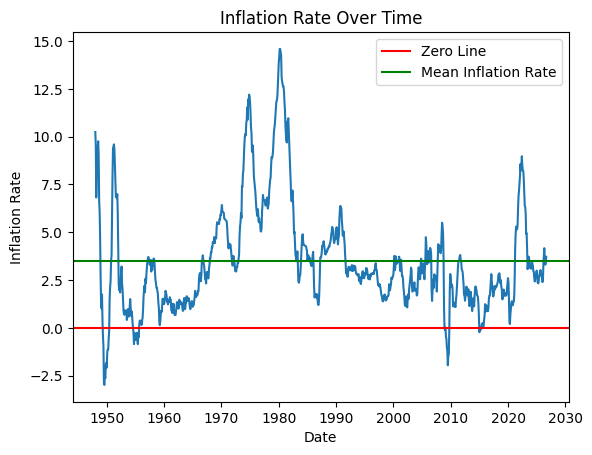

In [39]:
plt.plot(inflation.index,inflation['INFLATION'])
plt.xlabel('Date')
plt.ylabel('Inflation Rate')
plt.title('Inflation Rate Over Time')
plt.axhline(y = 0, color = 'r', linestyle = '-', label = 'Zero Line')
plt.axhline(y= inflation['INFLATION'].mean(),color = 'g', linestyle = '-', label = 'Mean Inflation Rate')
plt.legend()
plt.show()

#plot inflation with time

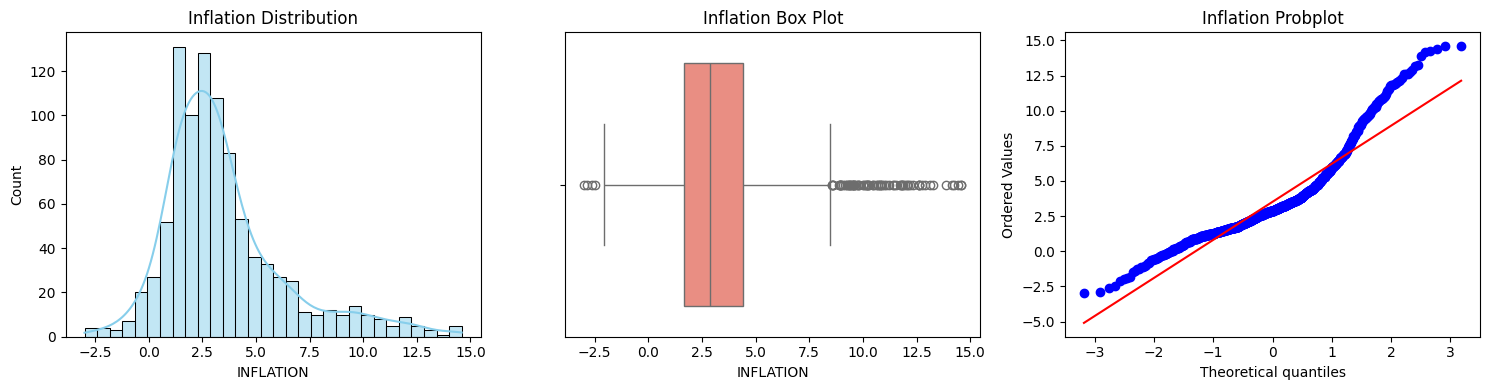

In [40]:
plt.figure(figsize=(15, 4))


plt.subplot(1, 3, 1)
sns.histplot(inflation['INFLATION'], kde=True, bins=30, color='skyblue')
plt.title("Inflation Distribution")

plt.subplot(1, 3, 2)
sns.boxplot(x=inflation['INFLATION'], color='salmon')
plt.title("Inflation Box Plot")

plt.subplot(1, 3, 3)
probplot(inflation['INFLATION'], dist="norm", plot=plt)
plt.title("Inflation Probplot")

plt.tight_layout()
plt.show()

# plot distribution, boxplot, q-q prob-plot to analyze the underlying distribution

In [41]:
mean = inflation['INFLATION'].mean()
median = inflation['INFLATION'].median()
min = inflation['INFLATION'].min()
max = inflation['INFLATION'].max()
std = inflation['INFLATION'].std()
variance = std*std
skewness = inflation['INFLATION'].skew()
kurtosis = inflation['INFLATION'].kurtosis()

q1 = inflation['INFLATION'].quantile(0.25)
q3 = inflation['INFLATION'].quantile(0.75)
iqr = q3-q1
l = q1-1.5*iqr
u = q3+1.5*iqr

iqr_outliers = []
for i in inflation.index:
  if inflation['INFLATION'][i] < l or inflation['INFLATION'][i] > u:
    iqr_outliers.append([i,inflation['INFLATION'][i]])

z_score_outliers = []
for i in inflation.index:
  if abs((inflation['INFLATION'][i]-mean)/std)>2:
    z_score_outliers.append([i,inflation['INFLATION'][i]])

#determines statistics such as mean, median, ranges, stdev, variance, skewness, kurtosis
#determines outliers using iqr and z-score statistics

In [42]:
print("Mean : ",mean)
print("Median : ",median)
print("Minimum : ",min)
print("Maximum : ",max)
print("Standard Deviation : ",std)
print("Variance : ",variance)
print("Skewness : ",skewness)
print("Kurtosis : ",kurtosis)

Mean :  3.519230121322136
Median :  2.867949628796085
Minimum :  -2.988129349160873
Maximum :  14.592274678111572
Standard Deviation :  2.8589152362378076
Variance :  8.173396327992679
Skewness :  1.3413296245798259
Kurtosis :  2.116607559020475


In [43]:
print("Q1 : ",q1)
print("Q3 : ",q3)
print("IQR : ",iqr)
print("Lower Limit for IQR Outliers : ",l)
print("Upper Limit for IQR Outliers : ",u)
print("Number of IQR Outliers : ",len(iqr_outliers))
print("Percentage of IQR Outliers : ",len(iqr_outliers)/len(inflation['INFLATION']))

Q1 :  1.670850365585208
Q3 :  4.415018219677258
IQR :  2.7441678540920496
Lower Limit for IQR Outliers :  -2.4454014155528663
Upper Limit for IQR Outliers :  8.531270000815333
Number of IQR Outliers :  78
Percentage of IQR Outliers :  0.0826271186440678


In [44]:
for i in iqr_outliers:
  print(i[0], " --- ", float(i[1]))

1948-01-01 00:00:00  ---  10.242085661080068
1948-02-01 00:00:00  ---  9.481961147086038
1948-05-01 00:00:00  ---  9.384965831435089
1948-06-01 00:00:00  ---  9.375
1948-07-01 00:00:00  ---  9.761583445793963
1948-08-01 00:00:00  ---  9.062499999999996
1949-07-01 00:00:00  ---  -2.868852459016391
1949-08-01 00:00:00  ---  -2.988129349160873
1949-09-01 00:00:00  ---  -2.504105090311981
1949-10-01 00:00:00  ---  -2.6326614561908546
1951-02-01 00:00:00  ---  9.402795425667087
1951-03-01 00:00:00  ---  9.475465313028764
1951-04-01 00:00:00  ---  9.598308668076116
1951-05-01 00:00:00  ---  9.339503575936048
1951-06-01 00:00:00  ---  8.584589614740379
1973-12-01 00:00:00  ---  8.94117647058823
1974-01-01 00:00:00  ---  9.601873536299754
1974-02-01 00:00:00  ---  9.999999999999986
1974-03-01 00:00:00  ---  10.138248847926267
1974-04-01 00:00:00  ---  10.068649885583515
1974-05-01 00:00:00  ---  10.70615034168565
1974-06-01 00:00:00  ---  10.859728506787313
1974-07-01 00:00:00  ---  11.5384615

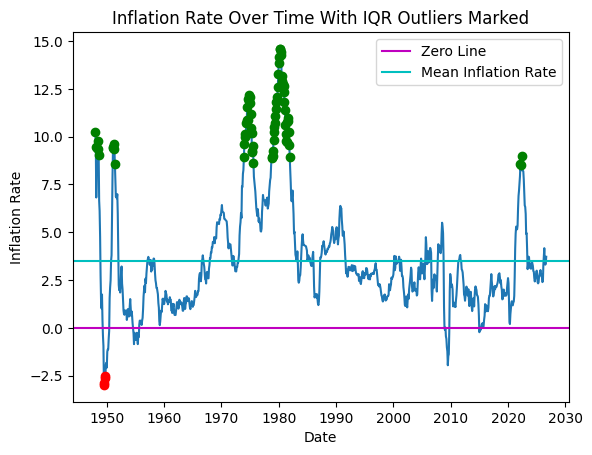

In [45]:
plt.plot(inflation.index,inflation['INFLATION'])
plt.xlabel('Date')
plt.ylabel('Inflation Rate')
plt.title('Inflation Rate Over Time With IQR Outliers Marked')
plt.axhline(y = 0, color = 'm', linestyle = '-', label = 'Zero Line')
plt.axhline(y= inflation['INFLATION'].mean(),color = 'c', linestyle = '-', label = 'Mean Inflation Rate')

for i in iqr_outliers:
  if float(i[1])>0:
    plt.plot(i[0],float(i[1]),color = 'g', marker = 'o', linestyle = 'None')
  else:
    plt.plot(i[0],float(i[1]),color = 'r', marker = 'o', linestyle = 'None')

plt.legend()
plt.show()

#plot inflation with time with iqr outliers to identify periods of high inflation and deflation

In [46]:
print("Lower Limit for Z-Score Outliers : ",mean - 2*std)
print("Upper Limit for Z-Score Outliers : ",mean+2*std)
print("Number of  Z-Score Outliers : ",len(z_score_outliers))
print("Percentage of Z-Score Outliers : ",len(z_score_outliers)/len(inflation['INFLATION']))

Lower Limit for Z-Score Outliers :  -2.198600351153479
Upper Limit for Z-Score Outliers :  9.237060593797752
Number of  Z-Score Outliers :  66
Percentage of Z-Score Outliers :  0.06991525423728813


In [47]:
for i in z_score_outliers:
  print(i[0], " --- ", float(i[1]))

1948-01-01 00:00:00  ---  10.242085661080068
1948-02-01 00:00:00  ---  9.481961147086038
1948-05-01 00:00:00  ---  9.384965831435089
1948-06-01 00:00:00  ---  9.375
1948-07-01 00:00:00  ---  9.761583445793963
1949-07-01 00:00:00  ---  -2.868852459016391
1949-08-01 00:00:00  ---  -2.988129349160873
1949-09-01 00:00:00  ---  -2.504105090311981
1949-10-01 00:00:00  ---  -2.6326614561908546
1951-02-01 00:00:00  ---  9.402795425667087
1951-03-01 00:00:00  ---  9.475465313028764
1951-04-01 00:00:00  ---  9.598308668076116
1951-05-01 00:00:00  ---  9.339503575936048
1974-01-01 00:00:00  ---  9.601873536299754
1974-02-01 00:00:00  ---  9.999999999999986
1974-03-01 00:00:00  ---  10.138248847926267
1974-04-01 00:00:00  ---  10.068649885583515
1974-05-01 00:00:00  ---  10.70615034168565
1974-06-01 00:00:00  ---  10.859728506787313
1974-07-01 00:00:00  ---  11.538461538461519
1974-08-01 00:00:00  ---  10.888888888888882
1974-09-01 00:00:00  ---  11.946902654867241
1974-10-01 00:00:00  ---  11.842

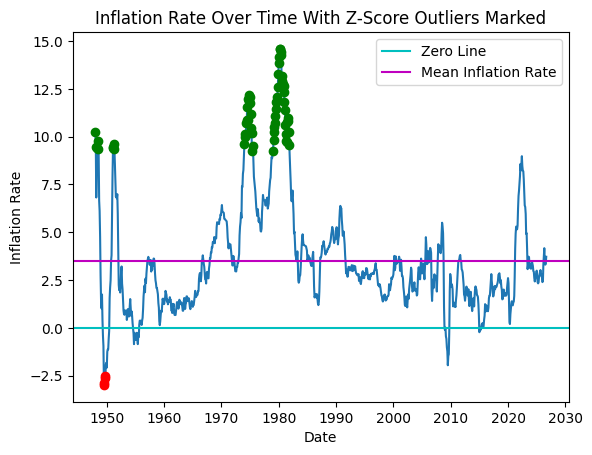

In [48]:
plt.plot(inflation.index,inflation['INFLATION'])
plt.xlabel('Date')
plt.ylabel('Inflation Rate')
plt.title('Inflation Rate Over Time With Z-Score Outliers Marked')
plt.axhline(y = 0, color = 'c', linestyle = '-', label = 'Zero Line')
plt.axhline(y= inflation['INFLATION'].mean(),color = 'm', linestyle = '-', label = 'Mean Inflation Rate')

for i in z_score_outliers:
  if float(i[1])>0:
    plt.plot(i[0],float(i[1]),color = 'g', marker = 'o', linestyle = 'None')
  else:
    plt.plot(i[0],float(i[1]),color = 'r', marker = 'o', linestyle = 'None')

plt.legend()
plt.show()

#plot inflation with time using z-score outliers to identify periods of high inflation and deflation with another metric to cross verify

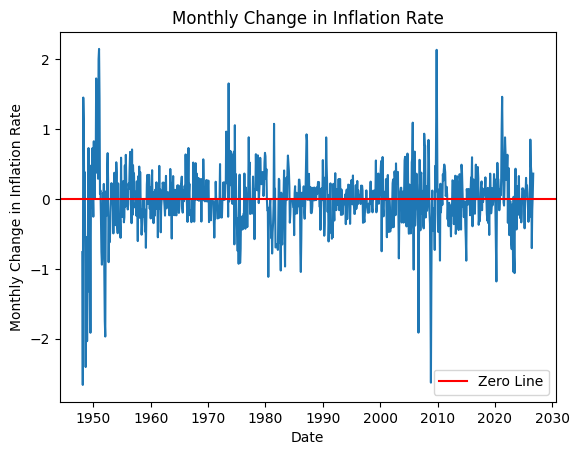

In [49]:
plt.plot(inflation.index,inflation['INFLATION']-inflation['INFLATION'].shift(1))
plt.xlabel('Date')
plt.ylabel('Monthly Change in Inflation Rate')
plt.title('Monthly Change in Inflation Rate')
plt.axhline(y = 0, color = 'r', linestyle = '-', label = 'Zero Line')
plt.legend()
plt.show()

#monthly change in inflation rate is considered as a metric to measure both volatity of inflation as well as periods of rapid change

In [50]:
inflation_change = pd.DataFrame(inflation['INFLATION']-inflation['INFLATION'].shift(1))
inflation_change.head()

,INFLATION
observation_date,
1948-01-01,NaN
1948-02-01,-0.760125
1948-03-01,-2.663779
1948-04-01,1.454545
1948-05-01,1.112239


In [51]:
mean = inflation_change['INFLATION'].mean()
median = inflation_change['INFLATION'].median()
min = inflation_change['INFLATION'].min()
max = inflation_change['INFLATION'].max()
std = inflation_change['INFLATION'].std()
variance = std*std
skewness = inflation_change['INFLATION'].skew()
kurtosis = inflation_change['INFLATION'].kurtosis()

q1 = inflation_change['INFLATION'].quantile(0.25)
q3 = inflation_change['INFLATION'].quantile(0.75)
iqr = q3-q1
l = q1-1.5*iqr
u = q3+1.5*iqr

iqr_outliers = []
for i in inflation_change.index:
  if inflation_change['INFLATION'][i] < l or inflation_change['INFLATION'][i] > u:
    iqr_outliers.append([i,inflation_change['INFLATION'][i]])

z_score_outliers = []
for i in inflation_change.index:
  if abs((inflation_change['INFLATION'][i]-mean)/std)>2:
    z_score_outliers.append([i,inflation_change['INFLATION'][i]])

#similar statistics and outlier analyses are conducted to understand outcomes

In [52]:
print("Mean : ",mean)
print("Median : ",median)
print("Minimum : ",min)
print("Maximum : ",max)
print("Standard Deviation : ",std)
print("Variance : ",variance)
print("Skewness : ",skewness)
print("Kurtosis : ",kurtosis)

Mean :  -0.00691923098283253
Median :  -0.007747483681863621
Minimum :  -2.6637793289042255
Maximum :  2.151436095303816
Standard Deviation :  0.4469429130776996
Variance :  0.19975796755038017
Skewness :  -0.5628358276524394
Kurtosis :  6.528813777879921


In [53]:
print("Q1 : ",q1)
print("Q3 : ",q3)
print("IQR : ",iqr)
print("Lower Limit for IQR Outliers : ",l)
print("Upper Limit for IQR Outliers : ",u)
print("Number of IQR Outliers : ",len(iqr_outliers))
print("Percentage of IQR Outliers : ",len(iqr_outliers)/len(inflation['INFLATION']))

Q1 :  -0.22015695611692365
Q3 :  0.22404438951098005
IQR :  0.4442013456279037
Lower Limit for IQR Outliers :  -0.8864589745587792
Upper Limit for IQR Outliers :  0.8903464079528356
Number of IQR Outliers :  45
Percentage of IQR Outliers :  0.04766949152542373


In [54]:
for i in iqr_outliers:
  print(i[0], " --- ", float(i[1]))

1948-03-01 00:00:00  ---  -2.6637793289042255
1948-04-01 00:00:00  ---  1.4545454545454648
1948-05-01 00:00:00  ---  1.112238558707812
1948-09-01 00:00:00  ---  -2.4075087565674345
1948-11-01 00:00:00  ---  -1.340703828813905
1948-12-01 00:00:00  ---  -2.0362903748666783
1949-01-01 00:00:00  ---  -1.3402933315630694
1949-04-01 00:00:00  ---  -1.3248655697875922
1949-07-01 00:00:00  ---  -1.9164715066354532
1950-07-01 00:00:00  ---  1.7284055148667266
1950-10-01 00:00:00  ---  1.02233784715271
1950-12-01 00:00:00  ---  2.005157651499312
1951-01-01 00:00:00  ---  2.151436095303816
1951-02-01 00:00:00  ---  1.4487333244335812
1951-07-01 00:00:00  ---  -0.9402190289489409
1951-12-01 00:00:00  ---  -1.0270981012452163
1952-01-01 00:00:00  ---  -1.7488537717486707
1952-02-01 00:00:00  ---  -1.9704670197664642
1952-09-01 00:00:00  ---  -0.9045574459121131
1973-03-01 00:00:00  ---  0.9661835748792313
1973-08-01 00:00:00  ---  1.656941224834707
1974-09-01 00:00:00  ---  1.0580137659783588
1975-

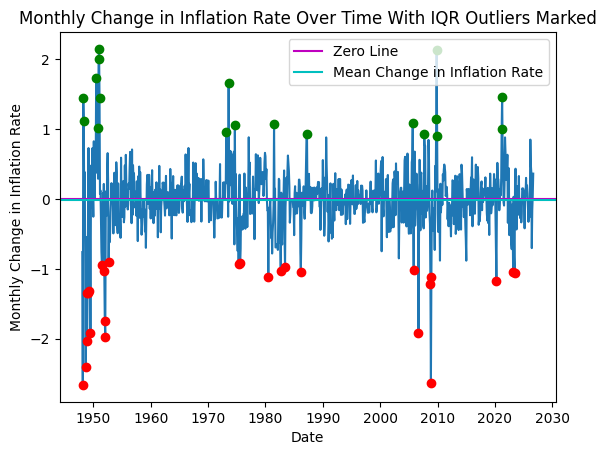

In [55]:
plt.plot(inflation_change.index,inflation_change['INFLATION'])
plt.xlabel('Date')
plt.ylabel('Monthly Change in Inflation Rate')
plt.title('Monthly Change in Inflation Rate Over Time With IQR Outliers Marked')
plt.axhline(y = 0, color = 'm', linestyle = '-', label = 'Zero Line')
plt.axhline(y= inflation_change['INFLATION'].mean(),color = 'c', linestyle = '-', label = 'Mean Change in Inflation Rate')

for i in iqr_outliers:
  if float(i[1])>0:
    plt.plot(i[0],float(i[1]),color = 'g', marker = 'o', linestyle = 'None')
  else:
    plt.plot(i[0],float(i[1]),color = 'r', marker = 'o', linestyle = 'None')

plt.legend()
plt.show()

#monthly change in inflation is plotted with iqr outliers marked to identify periods of rapid change of inflation rate

In [56]:
print("Lower Limit for Z-Score Outliers : ",mean - 2*std)
print("Upper Limit for Z-Score Outliers : ",mean+2*std)
print("Number of  Z-Score Outliers : ",len(z_score_outliers))
print("Percentage of Z-Score Outliers : ",len(z_score_outliers)/len(inflation_change['INFLATION']))

Lower Limit for Z-Score Outliers :  -0.9008050571382318
Upper Limit for Z-Score Outliers :  0.8869665951725667
Number of  Z-Score Outliers :  45
Percentage of Z-Score Outliers :  0.04766949152542373


In [57]:
for i in z_score_outliers:
  print(i[0], " --- ", float(i[1]))

1948-03-01 00:00:00  ---  -2.6637793289042255
1948-04-01 00:00:00  ---  1.4545454545454648
1948-05-01 00:00:00  ---  1.112238558707812
1948-09-01 00:00:00  ---  -2.4075087565674345
1948-11-01 00:00:00  ---  -1.340703828813905
1948-12-01 00:00:00  ---  -2.0362903748666783
1949-01-01 00:00:00  ---  -1.3402933315630694
1949-04-01 00:00:00  ---  -1.3248655697875922
1949-07-01 00:00:00  ---  -1.9164715066354532
1950-07-01 00:00:00  ---  1.7284055148667266
1950-10-01 00:00:00  ---  1.02233784715271
1950-12-01 00:00:00  ---  2.005157651499312
1951-01-01 00:00:00  ---  2.151436095303816
1951-02-01 00:00:00  ---  1.4487333244335812
1951-07-01 00:00:00  ---  -0.9402190289489409
1951-12-01 00:00:00  ---  -1.0270981012452163
1952-01-01 00:00:00  ---  -1.7488537717486707
1952-02-01 00:00:00  ---  -1.9704670197664642
1952-09-01 00:00:00  ---  -0.9045574459121131
1973-03-01 00:00:00  ---  0.9661835748792313
1973-08-01 00:00:00  ---  1.656941224834707
1974-09-01 00:00:00  ---  1.0580137659783588
1975-

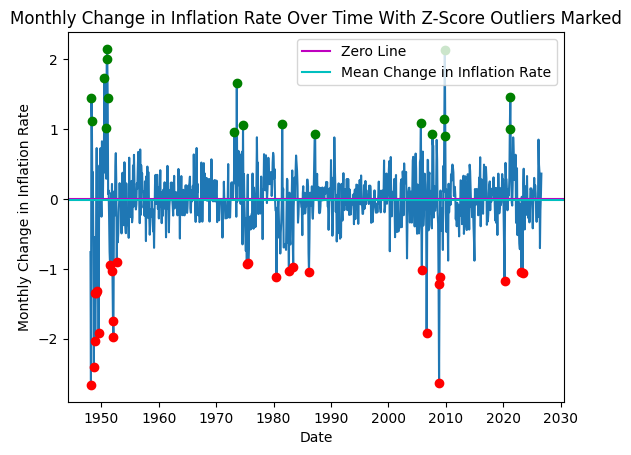

In [58]:
plt.plot(inflation_change.index,inflation_change['INFLATION'])
plt.xlabel('Date')
plt.ylabel('Monthly Change in Inflation Rate')
plt.title('Monthly Change in Inflation Rate Over Time With Z-Score Outliers Marked')
plt.axhline(y = 0, color = 'm', linestyle = '-', label = 'Zero Line')
plt.axhline(y= inflation_change['INFLATION'].mean(),color = 'c', linestyle = '-', label = 'Mean Change in Inflation Rate')

for i in z_score_outliers:
  if float(i[1])>0:
    plt.plot(i[0],float(i[1]),color = 'g', marker = 'o', linestyle = 'None')
  else:
    plt.plot(i[0],float(i[1]),color = 'r', marker = 'o', linestyle = 'None')

plt.legend()
plt.show()


#monthly change is plotted with the z-score outliers to idfentify periods of rapid change

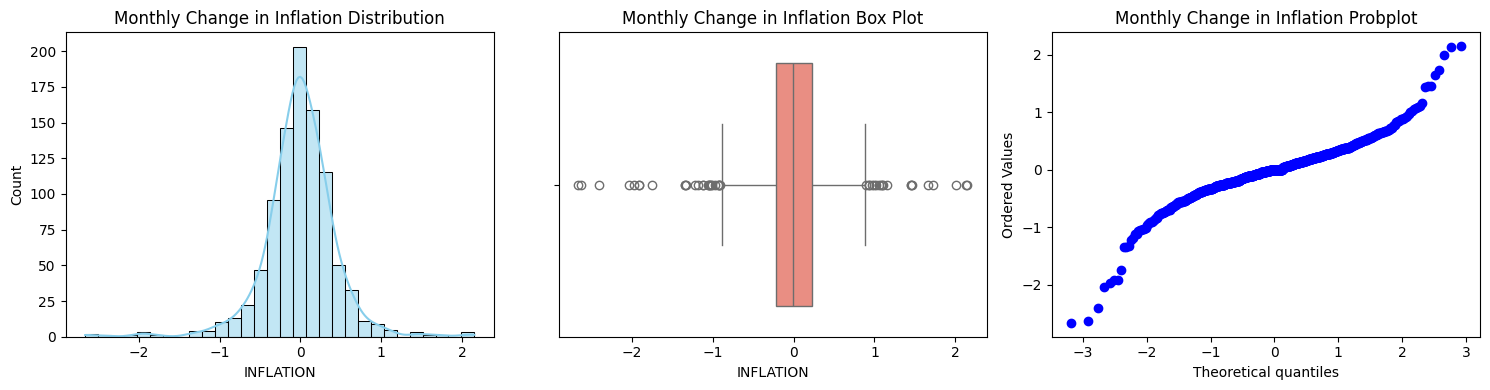

In [59]:
plt.figure(figsize=(15, 4))


plt.subplot(1, 3, 1)
sns.histplot(inflation_change['INFLATION'], kde=True, bins=30, color='skyblue')
plt.title("Monthly Change in Inflation Distribution")

plt.subplot(1, 3, 2)
sns.boxplot(x=inflation_change['INFLATION'], color='salmon')
plt.title("Monthly Change in Inflation Box Plot")

plt.subplot(1, 3, 3)
probplot(inflation_change['INFLATION'], dist="norm", plot=plt)
plt.title("Monthly Change in Inflation Probplot")

plt.tight_layout()
plt.show()

#distribution, boxplots and q-q prob-plots are plotted to analyze normalcy, distribution, outlier distribution, e.t.c

# **3. Analysis of Feature Distributions**

Examine the distributions, ranges, skewness, volatility,
and possible outliers of the macroeconomic variables.

In [67]:
def analysis_data(feature):
  data = pd.read_csv(f'Data/{feature}')
  data.set_index('observation_date',inplace=True)
  data.index = pd.to_datetime(data.index)

  #plot to be plotted
  fig, ax = plt.subplots()
  ax.plot(data.index,data[feature[:-4]])


  #stats
  mean = data[feature[:-4]].mean()
  median = data[feature[:-4]].median()
  lower = data[feature[:-4]].min()
  upper = data[feature[:-4]].max()
  lowerdate = data[feature[:-4]].idxmin()
  upperdate = data[feature[:-4]].idxmax()
  std = data[feature[:-4]].std()
  variance = std*std
  skewness = data[feature[:-4]].skew()
  kurtosis = data[feature[:-4]].kurtosis()

  stats = [mean, median,lower,upper, lowerdate, upperdate, std,variance,skewness, kurtosis]

  q1 = data[feature[:-4]].quantile(0.25)
  q3 = data[feature[:-4]].quantile(0.75)
  iqr = q3-q1
  l = q1-1.5*iqr
  u = q3+1.5*iqr

  #iqr outliers
  outliers = []
  for i in data.index:
    if data[feature[:-4]][i] < l or data[feature[:-4]][i] > u:
      outliers.append([i,data[feature[:-4]][i]])

  #z-score outliers'
  outz = []
  for i in data.index:
    if abs(data[feature[:-4]][i]-mean)/std > 3:
      outz.append([i,data[feature[:-4]][i]])

  quantiles = [q1,q3,iqr]


  return [ax,stats,quantiles,outliers,outz]

def analysis(feature):

  results = analysis_data(feature)

  ax = results[0]
  stats = results[1]
  outliers = results[3]
  outz = results[4]


  print(f"Statistics of {feature[:-4]} : \n")

  print('Mean: ',stats[0])
  print('Median: ',stats[1])
  print('Minimum: ',stats[2])
  print('Maximum: ',stats[3])
  print('Minimum Date: ',stats[4])
  print('Maximum Date: ',stats[5])
  print('Standard Deviation: ',stats[6])
  print('Variance: ',stats[7])
  print('Skewness: ',stats[8])
  print('Kurtosis: ',stats[9])

  print('\nQuantiles : \n')
  print('Q1: ',results[2][0])
  print('Q3: ',results[2][1])
  print('IQR: ',results[2][2])

  data = pd.read_csv(f'Data/{feature}')
  data.set_index('observation_date',inplace=True)
  data.index = pd.to_datetime(data.index)

  print('\n\nOutliers by IQR : \n')
  print('Number of IQR Outliers : ',len(outliers))
  print('Percentage of IQR Outliers : ',len(outliers)/len(data[feature[:-4]]))
  print('\n')
  for i in outliers:
    print(i[0], " --- ", float(i[1]))
  print('\n')

  print('Outliers by Z-Score : \n')
  print('Number of Z-Score Outliers : ',len(outz))
  print('Percentage of Z-Score Outliers : ',len(outz)/len(data[feature[:-4]]))
  print('\n')
  for i in outz:
    print(i[0], " --- ", float(i[1]))
  print('\n')

  plt.xlabel('Date')
  plt.ylabel(feature[:-4])
  plt.axhline(y= stats[0],color = 'g', linestyle = '-', label = 'Mean Line')
  plt.legend()
  plt.show()

  print('\n\n')

  plt.figure(figsize=(15, 4))


  plt.subplot(1, 3, 1)
  sns.histplot(data[feature[:-4]], kde=True, bins=30, color='skyblue')
  plt.title(f"{feature[:-4]} Distribution")

  plt.subplot(1, 3, 2)
  sns.boxplot(x=data[feature[:-4]], color='salmon')
  plt.title(f"{feature[:-4]} Box Plot")

  plt.subplot(1, 3, 3)
  probplot(data[feature[:-4]], dist="norm", plot=plt)
  plt.title(f"{feature[:-4]} Probplot")

  plt.tight_layout()
  plt.show()


  return None

# we define an analysis fucntion to thoroughly analyse the feature distributions for every feature
# it computes statistics, distributions, boxplots, q-q prob-plots
# also uses iqr and z-score metrics for outlier analysis
# for each feature, function is formatted to neatly yield an analysis-ready table of data

Statistics of UNRATE : 

Mean:  5.651322751322751
Median:  5.4
Minimum:  2.5
Maximum:  14.8
Minimum Date:  1953-05-01 00:00:00
Maximum Date:  2020-04-01 00:00:00
Standard Deviation:  1.7033805018458716
Variance:  2.9015051340686937
Skewness:  0.8953250212149173
Kurtosis:  1.1135393658753303

Quantiles : 

Q1:  4.3
Q3:  6.7
IQR:  2.4000000000000004


Outliers by IQR : 

Number of IQR Outliers :  8
Percentage of IQR Outliers :  0.008456659619450317


1982-10-01 00:00:00  ---  10.4
1982-11-01 00:00:00  ---  10.8
1982-12-01 00:00:00  ---  10.8
1983-01-01 00:00:00  ---  10.4
1983-02-01 00:00:00  ---  10.4
2020-04-01 00:00:00  ---  14.8
2020-05-01 00:00:00  ---  13.2
2020-06-01 00:00:00  ---  11.0


Outliers by Z-Score : 

Number of Z-Score Outliers :  5
Percentage of Z-Score Outliers :  0.005285412262156448


1982-11-01 00:00:00  ---  10.8
1982-12-01 00:00:00  ---  10.8
2020-04-01 00:00:00  ---  14.8
2020-05-01 00:00:00  ---  13.2
2020-06-01 00:00:00  ---  11.0




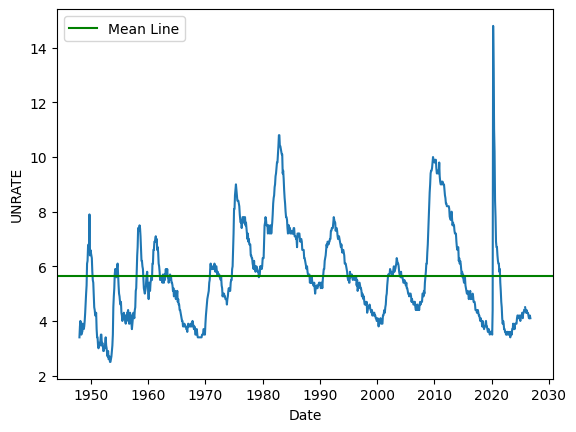

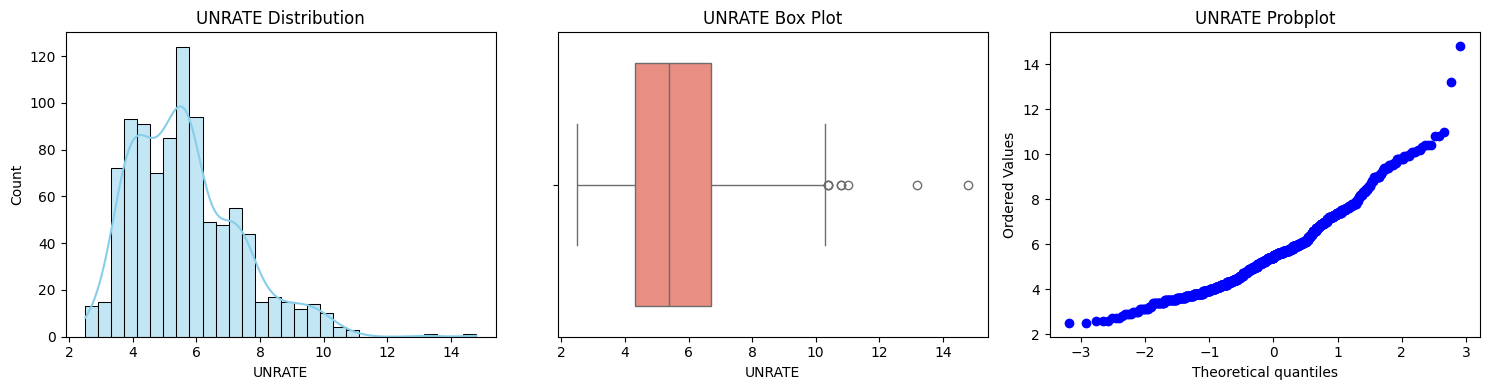

Statistics of UMCSENT : 

Mean:  84.26061946902655
Median:  88.3
Minimum:  44.8
Maximum:  112.0
Minimum Date:  2026-05-01 00:00:00
Maximum Date:  2000-01-01 00:00:00
Standard Deviation:  13.872550207024485
Variance:  192.4476492464151
Skewness:  -0.5091099711768834
Kurtosis:  -0.5092300753400263

Quantiles : 

Q1:  73.825
Q3:  94.6
IQR:  20.77499999999999


Outliers by IQR : 

Number of IQR Outliers :  0
Percentage of IQR Outliers :  0.0




Outliers by Z-Score : 

Number of Z-Score Outliers :  0
Percentage of Z-Score Outliers :  0.0






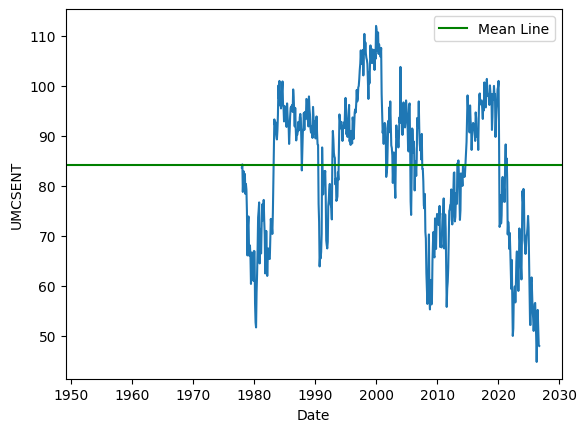

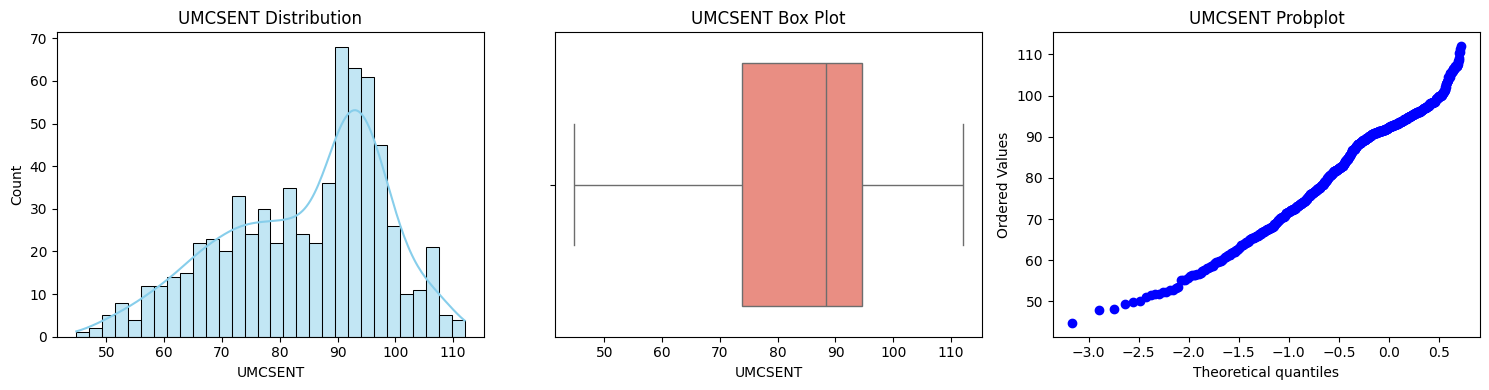

Statistics of T10Y2Y : 

Mean:  0.8432326595323028
Median:  0.77
Minimum:  -2.41
Maximum:  2.91
Minimum Date:  1980-03-20 00:00:00
Maximum Date:  2011-02-04 00:00:00
Standard Deviation:  0.9113622298580047
Variance:  0.8305811140117547
Skewness:  0.09987178322258962
Kurtosis:  -0.39908679264020375

Quantiles : 

Q1:  0.19
Q3:  1.47
IQR:  1.28


Outliers by IQR : 

Number of IQR Outliers :  25
Percentage of IQR Outliers :  0.0018983977522970613


1980-02-29 00:00:00  ---  -2.01
1980-03-03 00:00:00  ---  -2.04
1980-03-04 00:00:00  ---  -1.95
1980-03-05 00:00:00  ---  -1.96
1980-03-06 00:00:00  ---  -2.14
1980-03-07 00:00:00  ---  -2.34
1980-03-10 00:00:00  ---  -2.08
1980-03-11 00:00:00  ---  -2.02
1980-03-12 00:00:00  ---  -2.12
1980-03-13 00:00:00  ---  -2.19
1980-03-14 00:00:00  ---  -2.28
1980-03-17 00:00:00  ---  -2.24
1980-03-18 00:00:00  ---  -2.02
1980-03-19 00:00:00  ---  -1.98
1980-03-20 00:00:00  ---  -2.41
1980-03-21 00:00:00  ---  -2.27
1980-03-24 00:00:00  ---  -2.19
1980-0

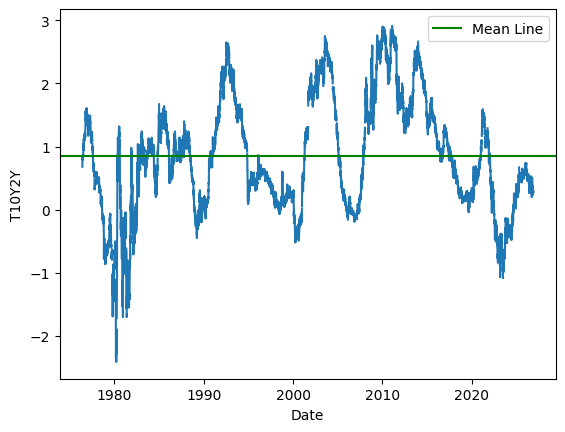

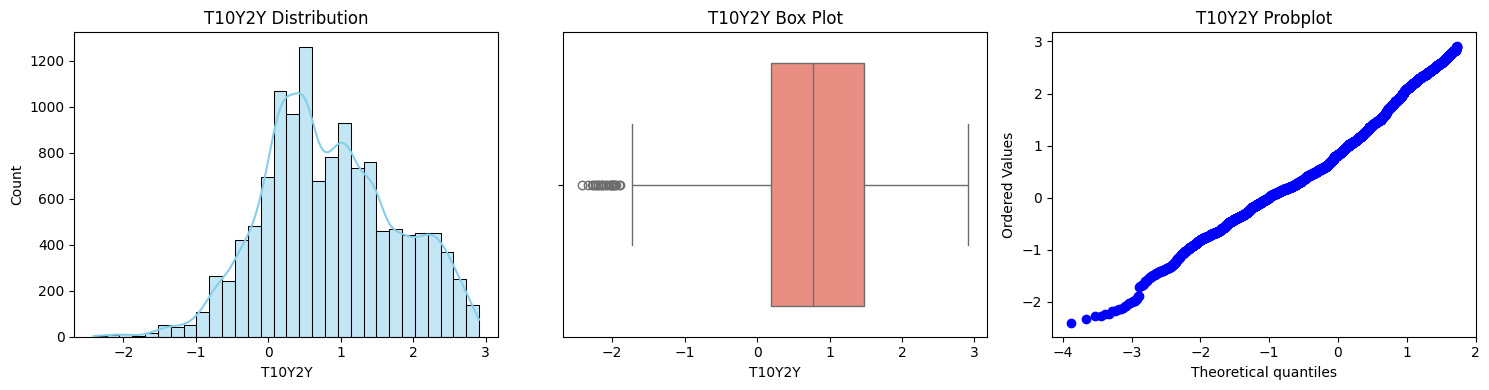

Statistics of PPIACO : 

Mean:  81.16682576866764
Median:  36.2
Minimum:  10.3
Maximum:  294.473
Minimum Date:  1933-02-01 00:00:00
Maximum Date:  2026-09-01 00:00:00
Standard Deviation:  73.77842652723145
Variance:  5443.256220834089
Skewness:  0.9319340175943267
Kurtosis:  -0.2892573795868869

Quantiles : 

Q1:  18.2
Q3:  127.275
IQR:  109.075


Outliers by IQR : 

Number of IQR Outliers :  2
Percentage of IQR Outliers :  0.0014641288433382138


2026-09-01 00:00:00  ---  294.473
2026-10-01 00:00:00  ---  293.921


Outliers by Z-Score : 

Number of Z-Score Outliers :  0
Percentage of Z-Score Outliers :  0.0






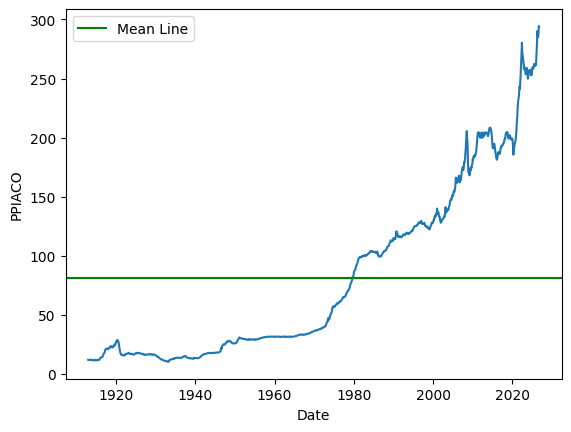

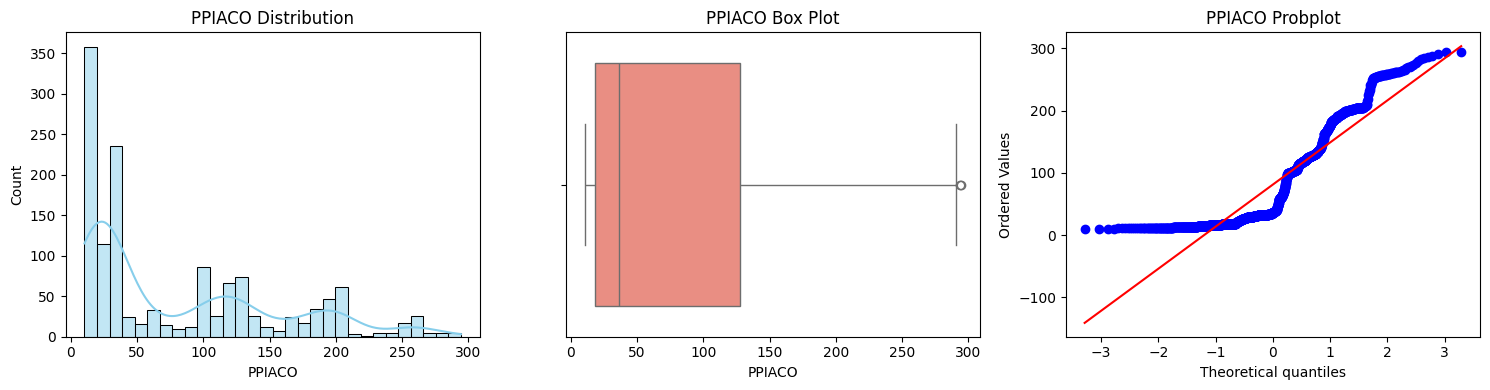

Statistics of PAYEMS : 

Mean:  94016.04269449716
Median:  91138.0
Minimum:  29923
Maximum:  159293
Minimum Date:  1939-01-01 00:00:00
Maximum Date:  2026-10-01 00:00:00
Standard Deviation:  38997.18635457787
Variance:  1520780543.5736744
Skewness:  0.04337382305330723
Kurtosis:  -1.417211794274521

Quantiles : 

Q1:  54272.5
Q3:  131602.25
IQR:  77329.75


Outliers by IQR : 

Number of IQR Outliers :  0
Percentage of IQR Outliers :  0.0




Outliers by Z-Score : 

Number of Z-Score Outliers :  0
Percentage of Z-Score Outliers :  0.0






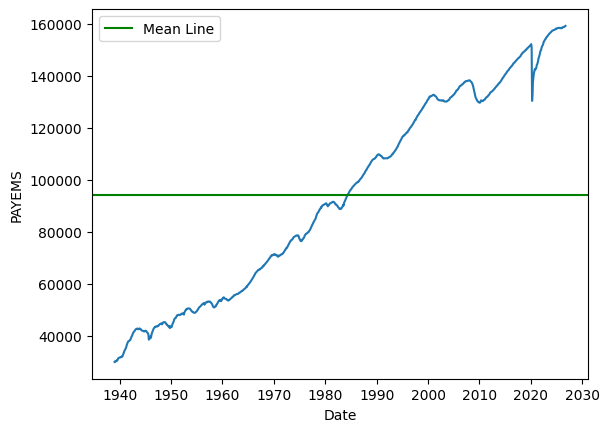

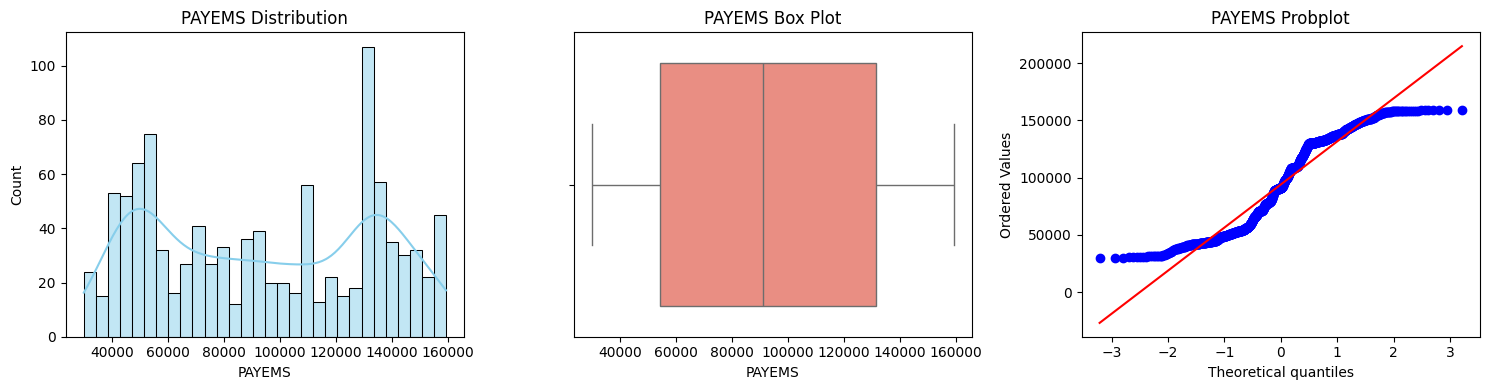

Statistics of M2SL : 

Mean:  5871.974169741698
Median:  3410.9
Minimum:  286.6
Maximum:  23413.9
Minimum Date:  1959-01-01 00:00:00
Maximum Date:  2026-09-01 00:00:00
Standard Deviation:  6303.004468983936
Variance:  39727865.33603147
Skewness:  1.3476182998143031
Kurtosis:  0.7801901942855323

Quantiles : 

Q1:  1016.3
Q3:  8473.1
IQR:  7456.8


Outliers by IQR : 

Number of IQR Outliers :  67
Percentage of IQR Outliers :  0.08241082410824108


2021-03-01 00:00:00  ---  19874.5
2021-04-01 00:00:00  ---  20174.2
2021-05-01 00:00:00  ---  20457.7
2021-06-01 00:00:00  ---  20472.0
2021-07-01 00:00:00  ---  20636.8
2021-08-01 00:00:00  ---  20893.4
2021-09-01 00:00:00  ---  21062.0
2021-10-01 00:00:00  ---  21149.8
2021-11-01 00:00:00  ---  21328.2
2021-12-01 00:00:00  ---  21488.2
2022-01-01 00:00:00  ---  21623.5
2022-02-01 00:00:00  ---  21706.0
2022-03-01 00:00:00  ---  21770.7
2022-04-01 00:00:00  ---  21750.8
2022-05-01 00:00:00  ---  21700.2
2022-06-01 00:00:00  ---  21630.9
2022-

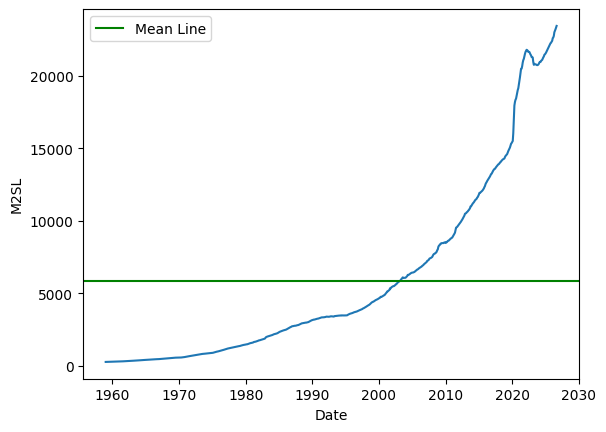

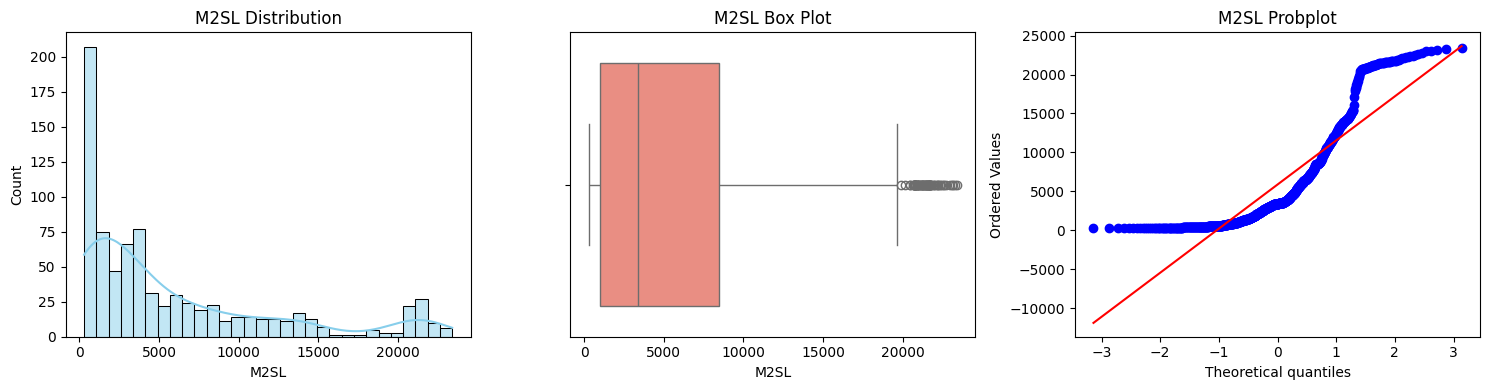

Statistics of INDPRO : 

Mean:  47.14242789799072
Median:  41.23765
Minimum:  3.6891
Maximum:  104.1004
Minimum Date:  1932-07-01 00:00:00
Maximum Date:  2018-09-01 00:00:00
Standard Deviation:  35.34052995264698
Variance:  1248.9530573339384
Skewness:  0.3369803230384635
Kurtosis:  -1.3954973638644421

Quantiles : 

Q1:  14.0292
Q3:  87.60515000000001
IQR:  73.57595


Outliers by IQR : 

Number of IQR Outliers :  0
Percentage of IQR Outliers :  0.0




Outliers by Z-Score : 

Number of Z-Score Outliers :  0
Percentage of Z-Score Outliers :  0.0






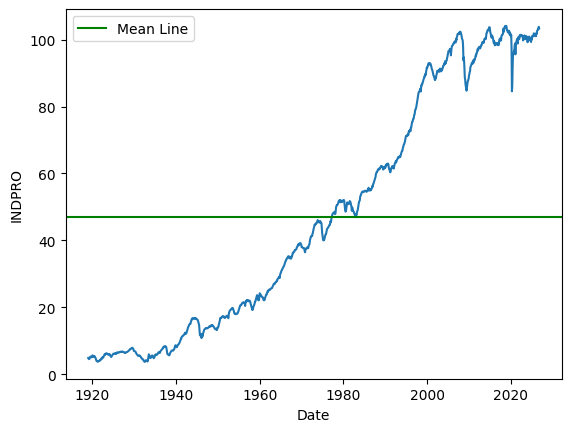

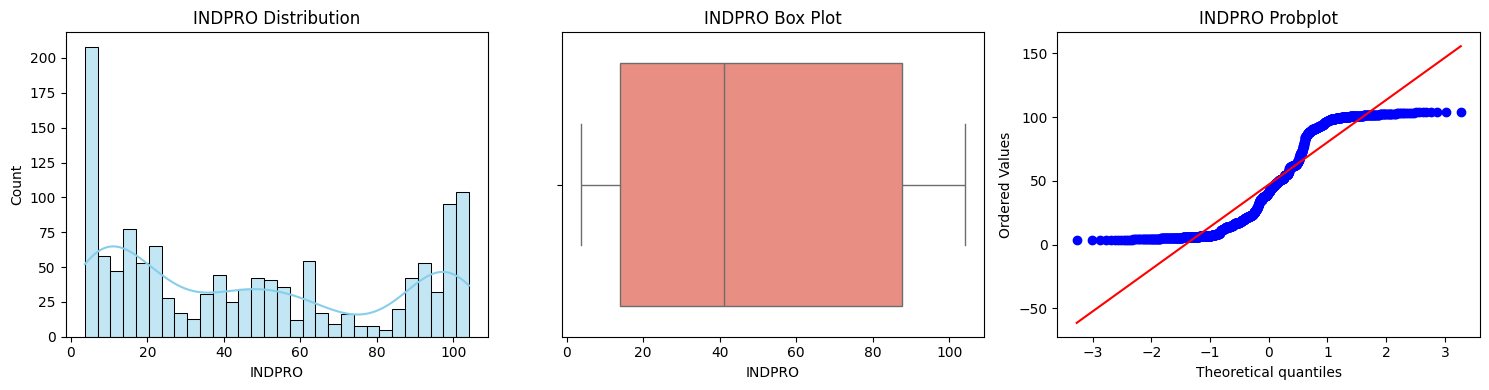

Statistics of HOUST : 

Mean:  1430.0479115479116
Median:  1447.0
Minimum:  478
Maximum:  2494
Minimum Date:  2009-04-01 00:00:00
Maximum Date:  1972-01-01 00:00:00
Standard Deviation:  375.034875182641
Variance:  140651.15760325908
Skewness:  -0.05744400367592567
Kurtosis:  0.26936682748969076

Quantiles : 

Q1:  1214.0
Q3:  1641.0
IQR:  427.0


Outliers by IQR : 

Number of IQR Outliers :  26
Percentage of IQR Outliers :  0.03194103194103194


1971-12-01 00:00:00  ---  2295.0
1972-01-01 00:00:00  ---  2494.0
1972-02-01 00:00:00  ---  2390.0
1972-03-01 00:00:00  ---  2334.0
1972-08-01 00:00:00  ---  2382.0
1972-09-01 00:00:00  ---  2481.0
1972-10-01 00:00:00  ---  2485.0
1972-11-01 00:00:00  ---  2421.0
1972-12-01 00:00:00  ---  2366.0
1973-01-01 00:00:00  ---  2481.0
1973-02-01 00:00:00  ---  2289.0
1973-03-01 00:00:00  ---  2365.0
2008-12-01 00:00:00  ---  560.0
2009-01-01 00:00:00  ---  490.0
2009-03-01 00:00:00  ---  505.0
2009-04-01 00:00:00  ---  478.0
2009-05-01 00:00:00  ---  

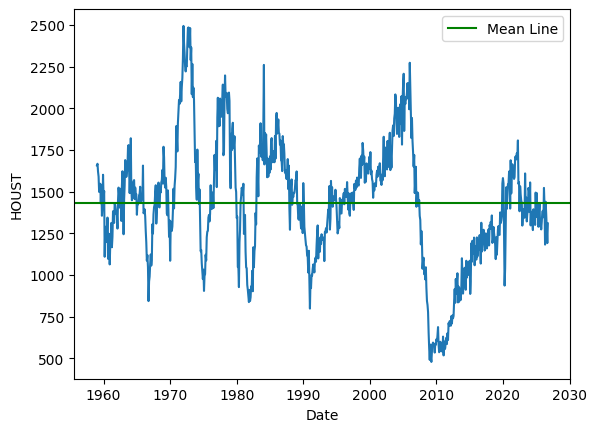

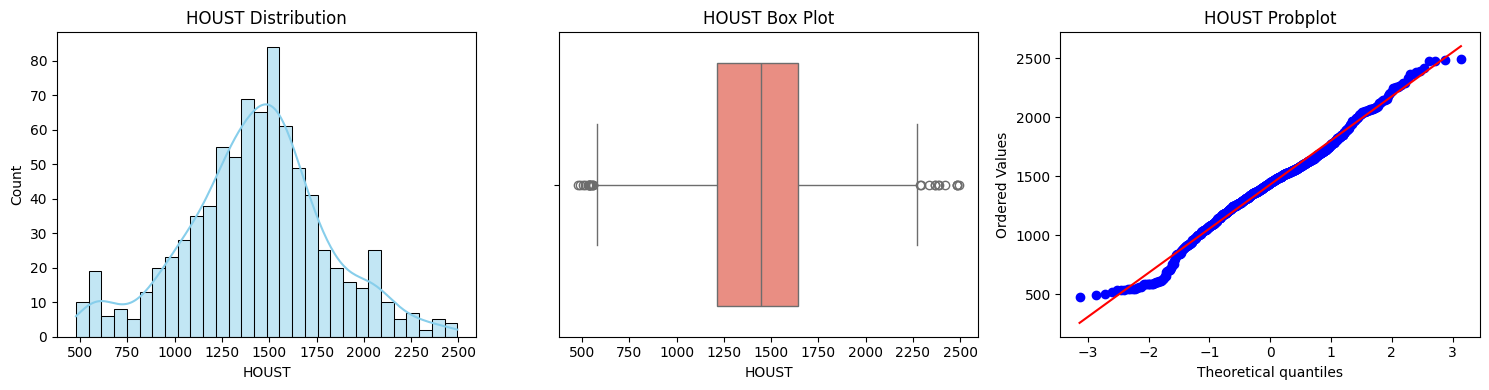

Statistics of FEDFUNDS : 

Mean:  4.593052995391704
Median:  4.245
Minimum:  0.05
Maximum:  19.1
Minimum Date:  2020-04-01 00:00:00
Maximum Date:  1981-06-01 00:00:00
Standard Deviation:  3.5238387061151584
Variance:  12.417439226715354
Skewness:  1.0914927181713971
Kurtosis:  1.7810986072444353

Quantiles : 

Q1:  1.9449999999999998
Q3:  6.1049999999999995
IQR:  4.16


Outliers by IQR : 

Number of IQR Outliers :  30
Percentage of IQR Outliers :  0.03456221198156682


1974-07-01 00:00:00  ---  12.92
1979-10-01 00:00:00  ---  13.77
1979-11-01 00:00:00  ---  13.18
1979-12-01 00:00:00  ---  13.78
1980-01-01 00:00:00  ---  13.82
1980-02-01 00:00:00  ---  14.13
1980-03-01 00:00:00  ---  17.19
1980-04-01 00:00:00  ---  17.61
1980-10-01 00:00:00  ---  12.81
1980-11-01 00:00:00  ---  15.85
1980-12-01 00:00:00  ---  18.9
1981-01-01 00:00:00  ---  19.08
1981-02-01 00:00:00  ---  15.93
1981-03-01 00:00:00  ---  14.7
1981-04-01 00:00:00  ---  15.72
1981-05-01 00:00:00  ---  18.52
1981-06-01 00:00

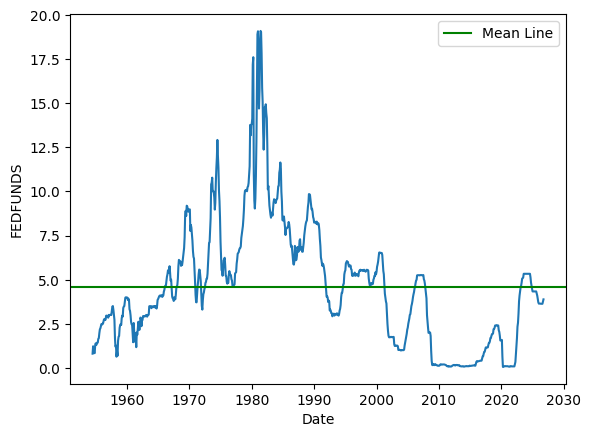

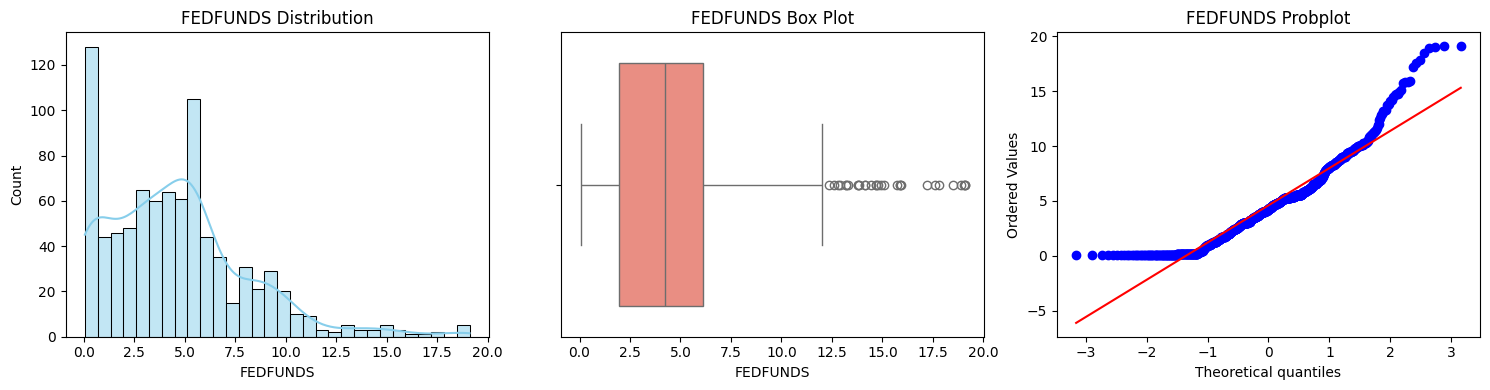

Statistics of DCOILWTICO : 

Mean:  50.1546161097727
Median:  47.29
Minimum:  -36.98
Maximum:  145.31
Minimum Date:  2020-04-20 00:00:00
Maximum Date:  2008-07-03 00:00:00
Standard Deviation:  29.937007058599804
Variance:  896.2243916266544
Skewness:  0.46206770290078686
Kurtosis:  -0.943058132258642

Quantiles : 

Q1:  20.515
Q3:  73.505
IQR:  52.989999999999995


Outliers by IQR : 

Number of IQR Outliers :  0
Percentage of IQR Outliers :  0.0




Outliers by Z-Score : 

Number of Z-Score Outliers :  7
Percentage of Z-Score Outliers :  0.0006564141035258815


2008-07-01 00:00:00  ---  141.06
2008-07-02 00:00:00  ---  143.74
2008-07-03 00:00:00  ---  145.31
2008-07-07 00:00:00  ---  141.38
2008-07-10 00:00:00  ---  141.47
2008-07-11 00:00:00  ---  144.96
2008-07-14 00:00:00  ---  145.16




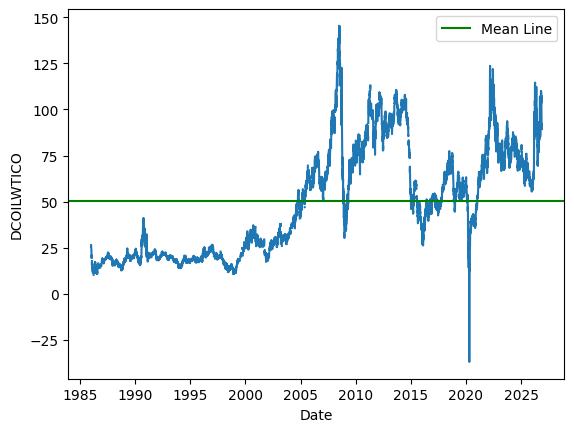

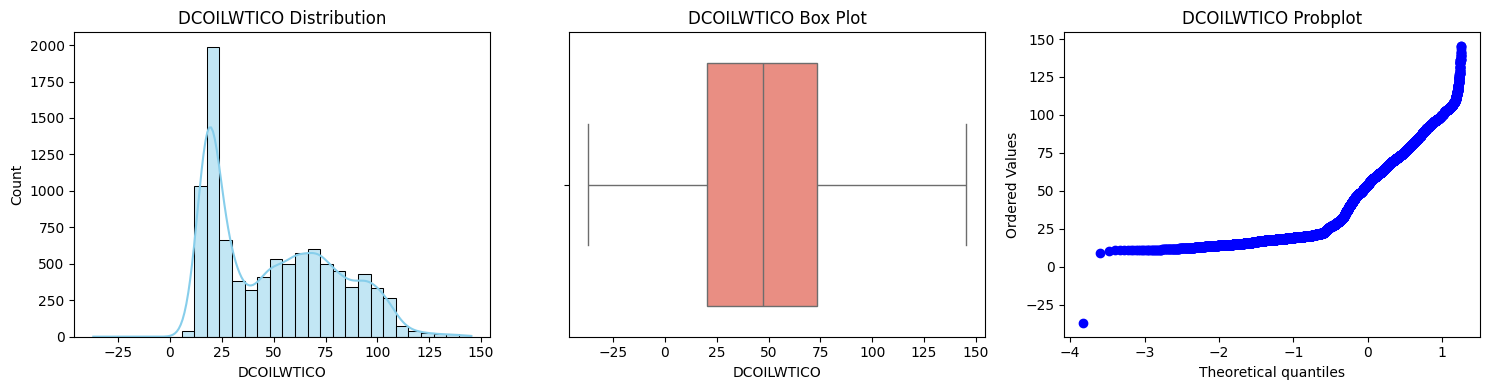

Statistics of CPIAUCSL : 

Mean:  126.02745977011496
Median:  110.4
Minimum:  21.48
Maximum:  337.476
Minimum Date:  1947-01-01 00:00:00
Maximum Date:  2026-10-01 00:00:00
Standard Deviation:  91.2479005803638
Variance:  8326.179360323957
Skewness:  0.47619833344738133
Kurtosis:  -1.0108015711667082

Quantiles : 

Q1:  32.9
Q3:  202.9
IQR:  170.0


Outliers by IQR : 

Number of IQR Outliers :  0
Percentage of IQR Outliers :  0.0




Outliers by Z-Score : 

Number of Z-Score Outliers :  0
Percentage of Z-Score Outliers :  0.0






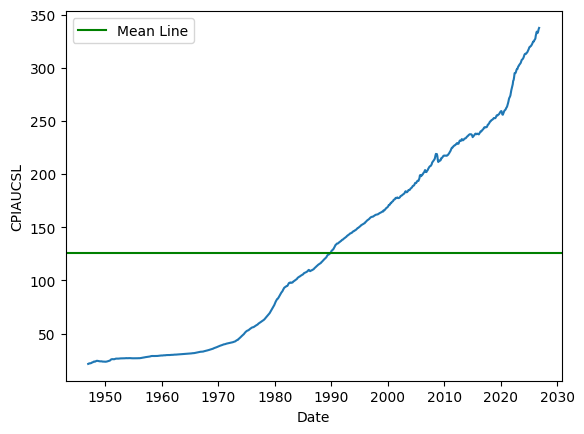

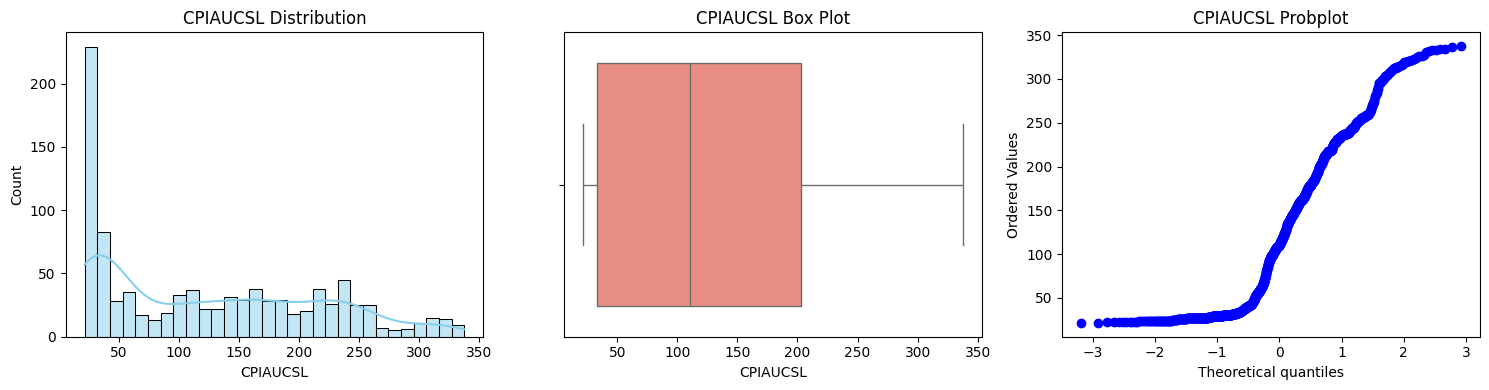

Statistics of INFLATION : 

Mean:  3.519230121322136
Median:  2.867949628796085
Minimum:  -2.988129349160873
Maximum:  14.592274678111572
Minimum Date:  1949-08-01 00:00:00
Maximum Date:  1980-03-01 00:00:00
Standard Deviation:  2.8589152362378076
Variance:  8.173396327992679
Skewness:  1.3413296245798259
Kurtosis:  2.116607559020475

Quantiles : 

Q1:  1.670850365585208
Q3:  4.415018219677258
IQR:  2.7441678540920496


Outliers by IQR : 

Number of IQR Outliers :  78
Percentage of IQR Outliers :  0.0826271186440678


1948-01-01 00:00:00  ---  10.242085661080068
1948-02-01 00:00:00  ---  9.481961147086038
1948-05-01 00:00:00  ---  9.384965831435087
1948-06-01 00:00:00  ---  9.375
1948-07-01 00:00:00  ---  9.761583445793963
1948-08-01 00:00:00  ---  9.062499999999996
1949-07-01 00:00:00  ---  -2.868852459016391
1949-08-01 00:00:00  ---  -2.988129349160873
1949-09-01 00:00:00  ---  -2.504105090311981
1949-10-01 00:00:00  ---  -2.6326614561908546
1951-02-01 00:00:00  ---  9.40279542566708

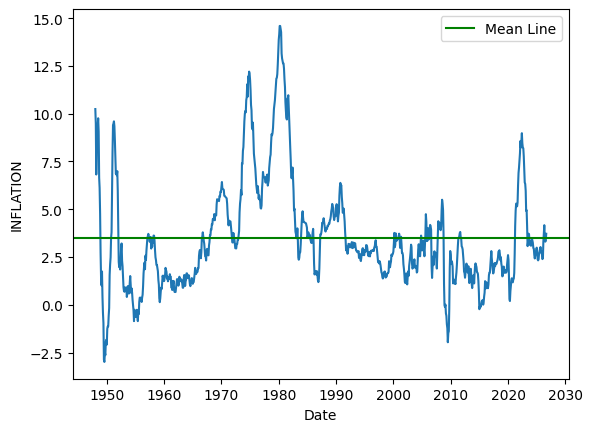

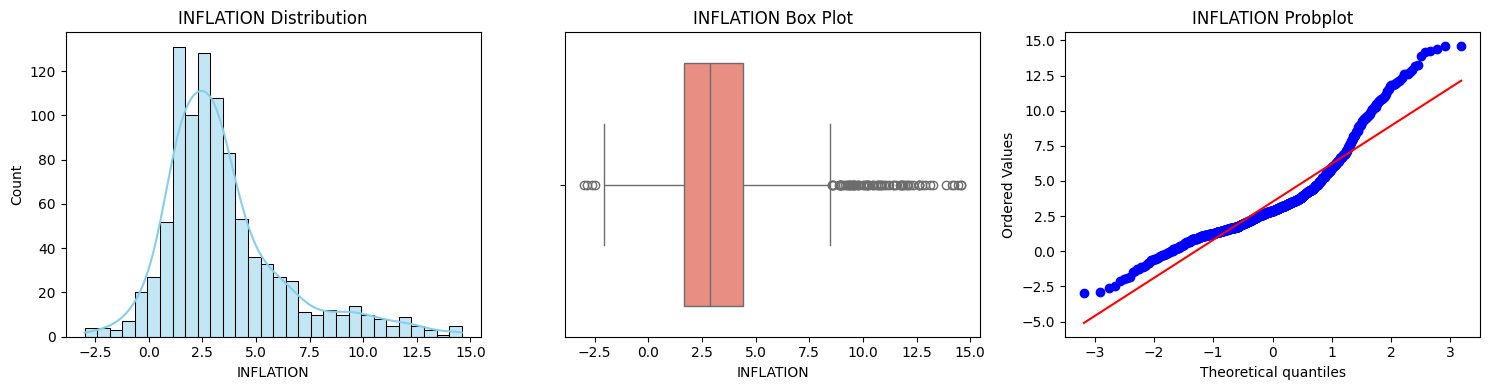

Statistics of UNCHANGE : 

Mean:  0.0006362672322375427
Median:  0.0
Minimum:  -2.1999999999999993
Maximum:  10.4
Minimum Date:  2020-06-01 00:00:00
Maximum Date:  2020-04-01 00:00:00
Standard Deviation:  0.41267037045240024
Variance:  0.17029683464932124
Skewness:  16.736867476399887
Kurtosis:  429.9426507010405

Quantiles : 

Q1:  -0.1000000000000005
Q3:  0.0999999999999996
IQR:  0.20000000000000012


Outliers by IQR : 

Number of IQR Outliers :  54
Percentage of IQR Outliers :  0.05726405090137858


1948-02-01 00:00:00  ---  0.3999999999999999
1949-02-01 00:00:00  ---  0.4000000000000003
1949-05-01 00:00:00  ---  0.7999999999999998
1949-07-01 00:00:00  ---  0.5
1949-10-01 00:00:00  ---  1.3000000000000007
1949-11-01 00:00:00  ---  -1.5
1950-04-01 00:00:00  ---  -0.5
1950-08-01 00:00:00  ---  -0.5
1951-01-01 00:00:00  ---  -0.5999999999999996
1953-11-01 00:00:00  ---  0.3999999999999999
1953-12-01 00:00:00  ---  1.0
1954-01-01 00:00:00  ---  0.4000000000000003
1954-03-01 00:00:00  --

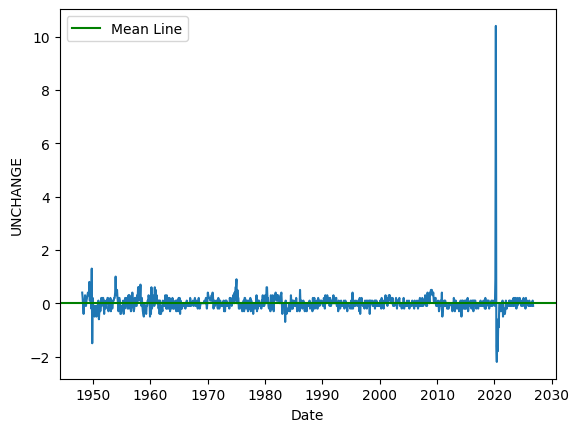

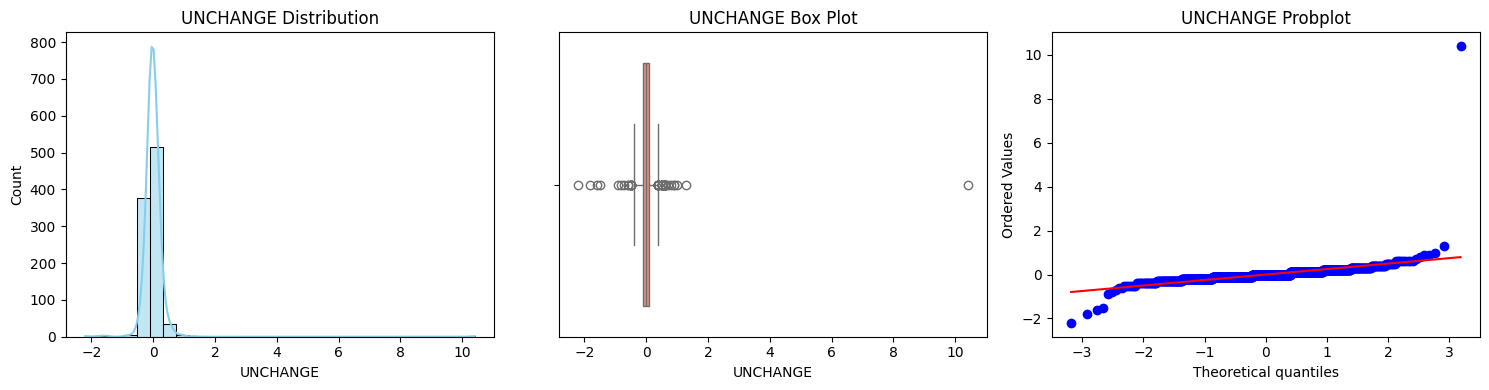

Statistics of GROWIND : 

Mean:  3.440410430503381
Median:  2.9754766781758923
Minimum:  -33.66323285186389
Maximum:  62.04223252283756
Minimum Date:  1946-02-01 00:00:00
Maximum Date:  1933-07-01 00:00:00
Standard Deviation:  10.633236691252286
Variance:  113.06572253219386
Skewness:  0.03255065118820645
Kurtosis:  2.9413042345518075

Quantiles : 

Q1:  -0.5644625710626655
Q3:  7.474675481008192
IQR:  8.039138052070857


Outliers by IQR : 

Number of IQR Outliers :  171
Percentage of IQR Outliers :  0.13338533541341654


1920-02-01 00:00:00  ---  20.809273371256843
1920-03-01 00:00:00  ---  22.02352004951591
1920-12-01 00:00:00  ---  -17.8021465235651
1921-01-01 00:00:00  ---  -29.18673039677322
1921-02-01 00:00:00  ---  -30.622434655910737
1921-03-01 00:00:00  ---  -31.21863734352639
1921-04-01 00:00:00  ---  -27.318669959225872
1921-05-01 00:00:00  ---  -27.135819057216437
1921-06-01 00:00:00  ---  -28.357105904958978
1921-07-01 00:00:00  ---  -27.04157035128273
1921-08-01 00:00:00 

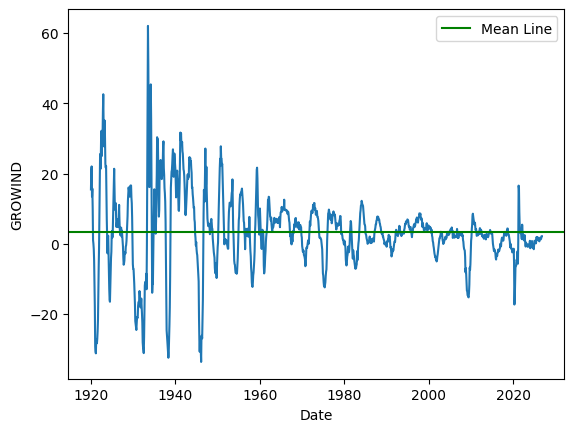

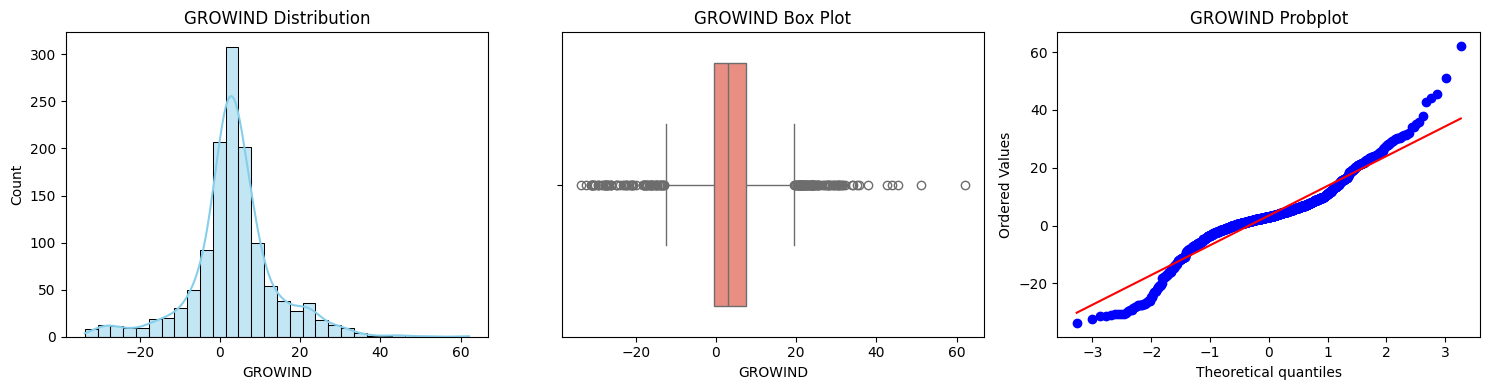

Statistics of GROWPAY : 

Mean:  1.9579722118899638
Median:  1.9298167967252255
Minimum:  -13.390574469921845
Maximum:  16.2638532339866
Minimum Date:  2020-04-01 00:00:00
Maximum Date:  1941-07-01 00:00:00
Standard Deviation:  3.0410898538041495
Variance:  9.248227498910543
Skewness:  0.3289978736481094
Kurtosis:  3.846308119909929

Quantiles : 

Q1:  0.5101402473708327
Q3:  3.2335380769248525
IQR:  2.7233978295540195


Outliers by IQR : 

Number of IQR Outliers :  82
Percentage of IQR Outliers :  0.07869481765834933


1940-12-01 00:00:00  ---  8.344429649356421
1941-01-01 00:00:00  ---  9.10673037369869
1941-02-01 00:00:00  ---  9.862840927006156
1941-03-01 00:00:00  ---  10.26551453260016
1941-04-01 00:00:00  ---  11.882905902022012
1941-05-01 00:00:00  ---  13.497913987264344
1941-06-01 00:00:00  ---  14.613628545517088
1941-07-01 00:00:00  ---  16.2638532339866
1941-08-01 00:00:00  ---  16.048466864490596
1941-09-01 00:00:00  ---  15.315452605912828
1941-10-01 00:00:00  ---  14.07

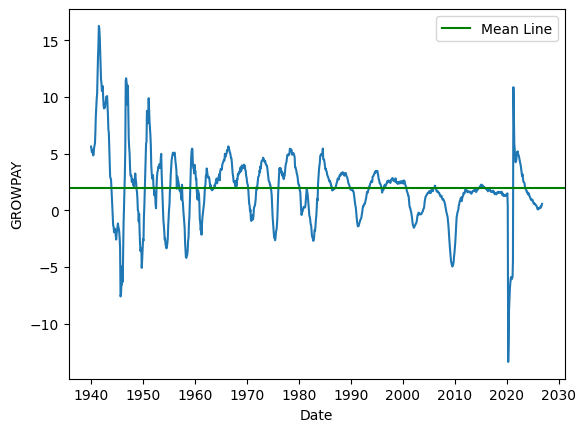

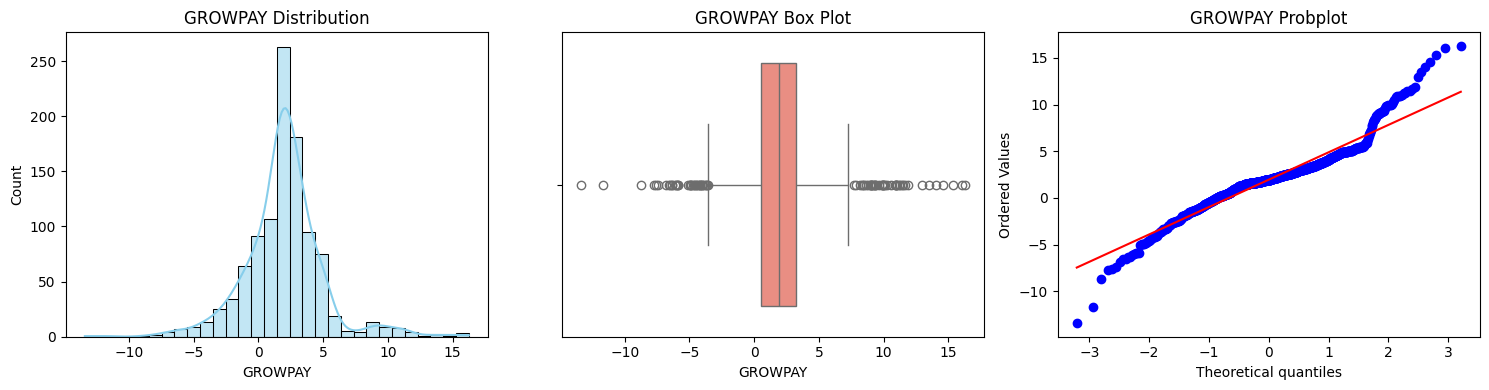

Statistics of GROWPROD : 

Mean:  3.2098244647868057
Median:  2.3084646277417464
Minimum:  -43.90243902439024
Maximum:  47.22222222222221
Minimum Date:  1921-06-01 00:00:00
Maximum Date:  1917-07-01 00:00:00
Standard Deviation:  8.788206453464875
Variance:  77.23257266872167
Skewness:  0.1919979204997568
Kurtosis:  6.493773138537472

Quantiles : 

Q1:  -0.4693359123146418
Q3:  6.140865762859626
IQR:  6.610201675174268


Outliers by IQR : 

Number of IQR Outliers :  149
Percentage of IQR Outliers :  0.11004431314623338


1916-03-01 00:00:00  ---  17.796610169491522
1916-04-01 00:00:00  ---  19.49152542372881
1916-05-01 00:00:00  ---  19.327731092436977
1916-06-01 00:00:00  ---  21.18644067796609
1916-07-01 00:00:00  ---  21.00840336134453
1916-08-01 00:00:00  ---  24.576271186440657
1916-09-01 00:00:00  ---  27.118644067796605
1916-10-01 00:00:00  ---  29.75206611570247
1916-11-01 00:00:00  ---  36.58536585365852
1916-12-01 00:00:00  ---  33.59375
1917-01-01 00:00:00  ---  32.3308270676

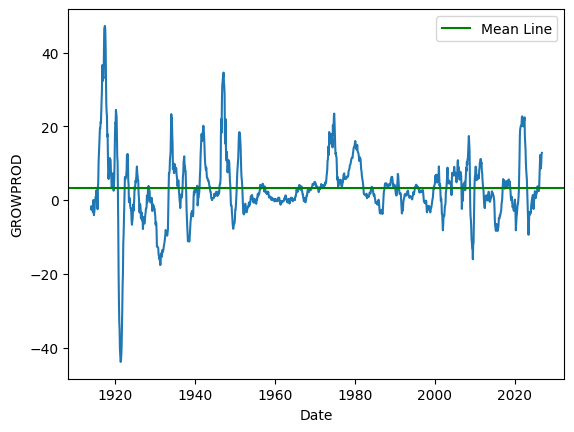

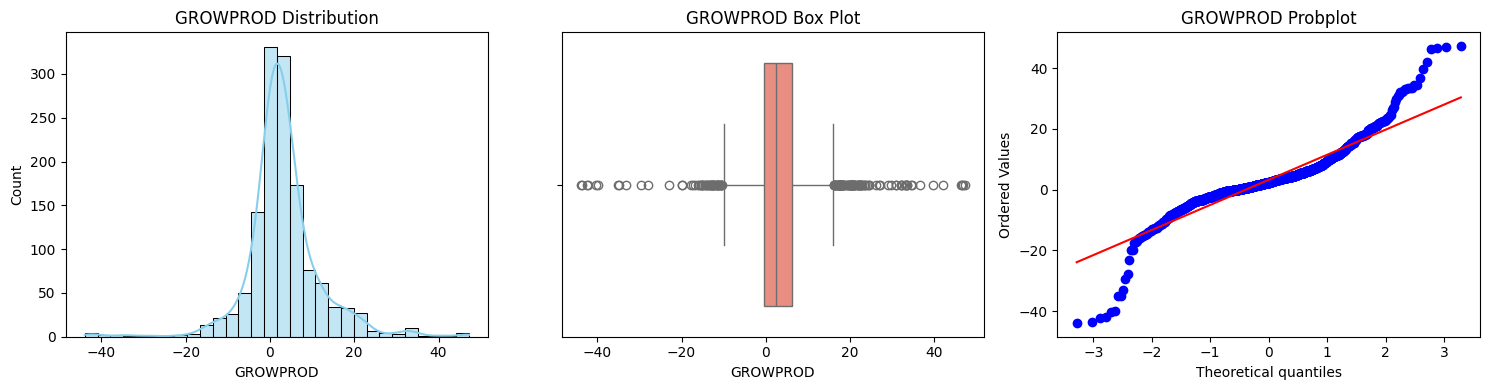

Statistics of GROWOIL : 

Mean:  0.4294447672302243
Median:  0.47610683463294995
Minimum:  -246.86258935663227
Maximum:  165.76879910213242
Minimum Date:  2020-04-20 00:00:00
Maximum Date:  2020-05-07 00:00:00
Standard Deviation:  9.36799877126168
Variance:  87.75940097836035
Skewness:  -1.406185086224327
Kurtosis:  88.45688401687067

Quantiles : 

Q1:  -4.019526370851182
Q3:  4.798434556603571
IQR:  8.817960927454752


Outliers by IQR : 

Number of IQR Outliers :  328
Percentage of IQR Outliers :  0.03784033225657591


1986-01-21 00:00:00  ---  -20.73076923076923
1986-01-22 00:00:00  ---  -23.67131549189597
1986-01-23 00:00:00  ---  -22.90135396518376
1986-01-24 00:00:00  ---  -24.816389640510252
1986-01-27 00:00:00  ---  -19.82328082981175
1986-01-28 00:00:00  ---  -24.171539961013643
1986-01-29 00:00:00  ---  -21.810207336523124
1986-01-30 00:00:00  ---  -21.58590308370044
1986-02-03 00:00:00  ---  -27.35613010842368
1986-02-04 00:00:00  ---  -34.06686415573424
1986-02-05 00:00:00  

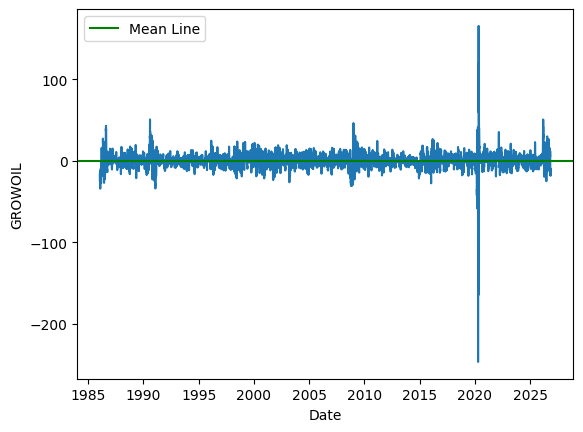

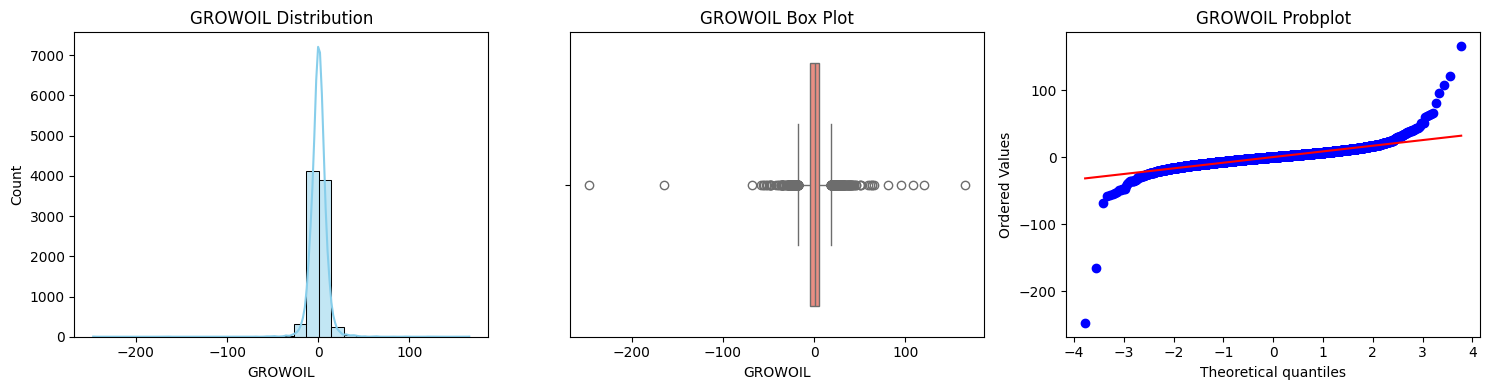

In [68]:
for i in file_list:
  analysis(i)

# **4. Analysis of Contemporaneous Relationships**

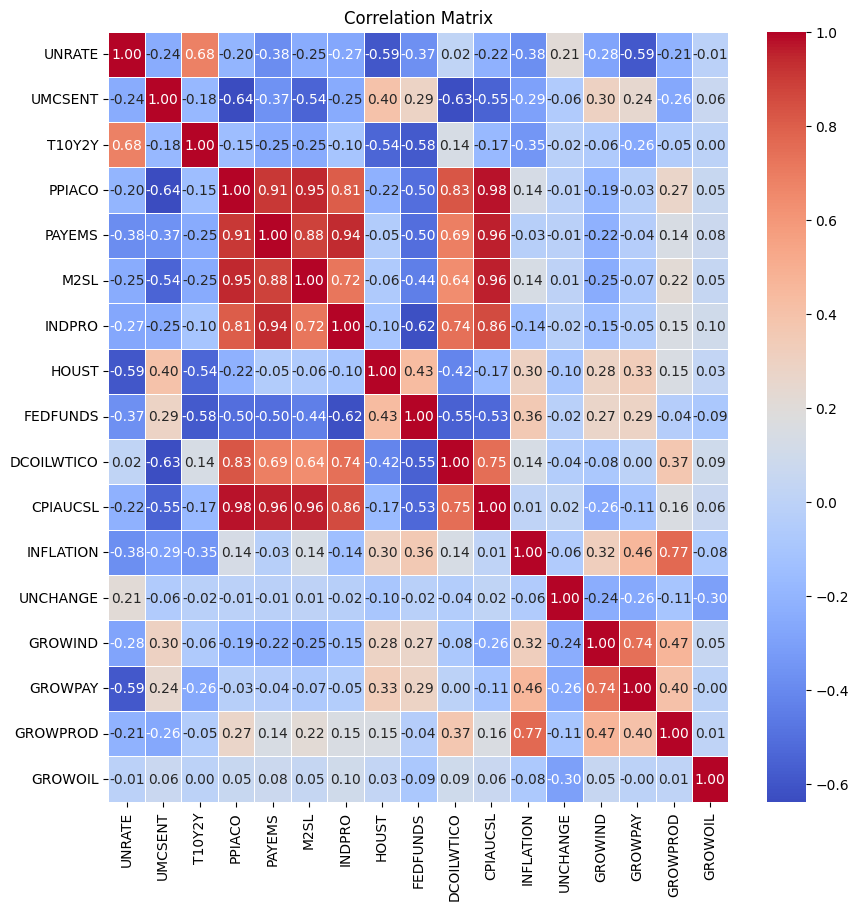

In [69]:
#constructs a pearson correlation matrix between every feature using a heat map to understand correlations and iddentify candidate predictors

numeric = core_df.select_dtypes(include=[np.number]).columns
correlation = core_df[numeric].corr(method='pearson')

plt.figure(figsize=(10, 10))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

# **5. Lead-Lag Analysis**

In [70]:
def lead_lag(feature):

  print(f"\n\nLead-Lag Analysis of {feature[:-4]} and Inflation\n\n")

  r1 = df_monthly[feature[:-4]].corr(df_monthly['INFLATION'].shift(-1))
  r3 = df_monthly[feature[:-4]].corr(df_monthly['INFLATION'].shift(-3))
  r6 = df_monthly[feature[:-4]].corr(df_monthly['INFLATION'].shift(-6))
  r12 = df_monthly[feature[:-4]].corr(df_monthly['INFLATION'].shift(-12))

  print(f'Pearson Correlation between {feature[:-4]} and Inflation at t+1 : {r1}\n')
  print(f'Pearson Correlation between {feature[:-4]} and Inflation at t+3 : {r3}\n')
  print(f'Pearson Correlation between {feature[:-4]} and Inflation at t+6 : {r6}\n')
  print(f'Pearson Correlation between {feature[:-4]} and Inflation at t+12 : {r12}\n\n')

  correlation_list = [df_monthly[feature[:-4]].corr(df_monthly['INFLATION'].shift(i)) for i in range (-1,-121,-1)]
  time_delay = [-i for i in range (-1,-121,-1)]

  corr_index = np.argmax(np.abs(correlation_list))
  max_x = time_delay[corr_index]
  max_y = correlation_list[corr_index]

  plt.figure(figsize=(12, 4))
  plt.plot(time_delay,correlation_list)

  plt.xlabel('Time Delay')
  plt.ylabel(f'Correlation between {feature[:-4]} and Inflation')
  plt.title(f'Correlation Graph of {feature[:-4]}')
  plt.plot(max_x,max_y, marker='o', markersize=10, color='red')
  plt.show()

  print(f'\n Maximum Pearson Correlation of {max_y} obtained with a time delay of {max_x} months')


  print('\n\n')

  plt.figure(figsize=(12, 8))

  plt.subplot(2, 2, 1)
  plt.scatter(df_monthly[feature[:-4]], df_monthly['INFLATION'].shift(-1))
  plt.title(f"{feature[:-4]} against Inflation at t+1")

  plt.subplot(2, 2, 2)
  plt.scatter(df_monthly[feature[:-4]], df_monthly['INFLATION'].shift(-3))
  plt.title(f"{feature[:-4]} against Inflation at t+3")

  plt.subplot(2, 2, 3)
  plt.scatter(df_monthly[feature[:-4]], df_monthly['INFLATION'].shift(-6))
  plt.title(f"{feature[:-4]} against Inflation at t+6")

  plt.subplot(2, 2, 4)
  plt.scatter(df_monthly[feature[:-4]], df_monthly['INFLATION'].shift(-12))
  plt.title(f"{feature[:-4]} against Inflation at t+12")

  plt.tight_layout()
  plt.show()

#lead-lag anaysis constructs a correlation graph, identifies correlations at time delays of 1,3,6, and 12 monthds and plots features against inflation at varying time delays



Lead-Lag Analysis of UNRATE and Inflation


Pearson Correlation between UNRATE and Inflation at t+1 : 0.059652539639785986

Pearson Correlation between UNRATE and Inflation at t+3 : 0.0400045208258561

Pearson Correlation between UNRATE and Inflation at t+6 : 0.023529019501497557

Pearson Correlation between UNRATE and Inflation at t+12 : 0.03995639786140417




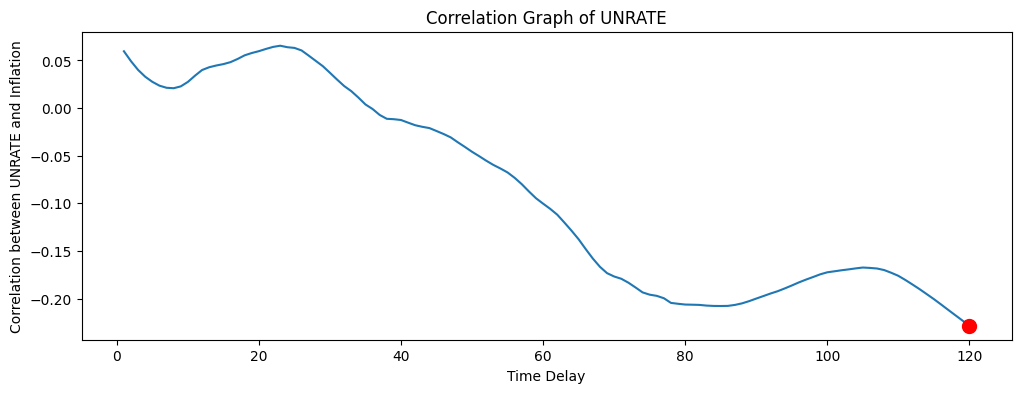


 Maximum Pearson Correlation of -0.2285250903965362 obtained with a time delay of 120 months





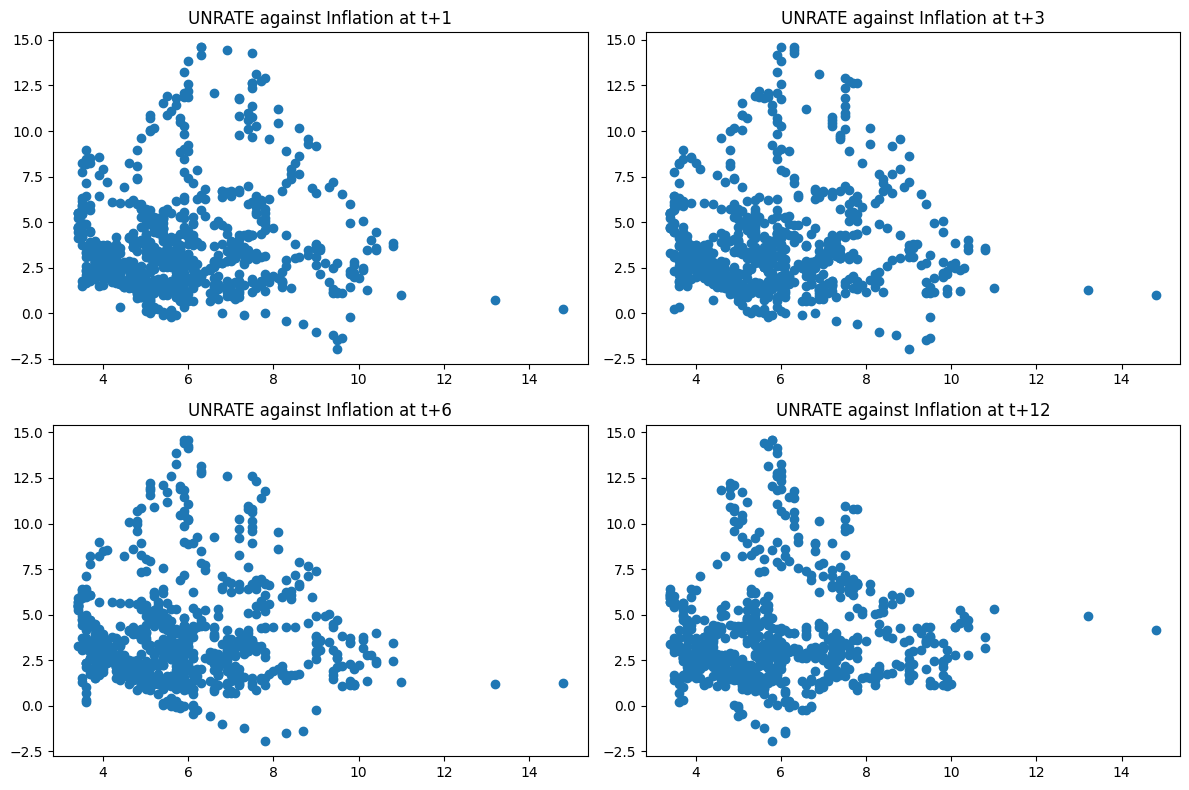



Lead-Lag Analysis of PPIACO and Inflation


Pearson Correlation between PPIACO and Inflation at t+1 : -0.19622287584883527

Pearson Correlation between PPIACO and Inflation at t+3 : -0.2092193816775292

Pearson Correlation between PPIACO and Inflation at t+6 : -0.23604797682489725

Pearson Correlation between PPIACO and Inflation at t+12 : -0.2809814858067388




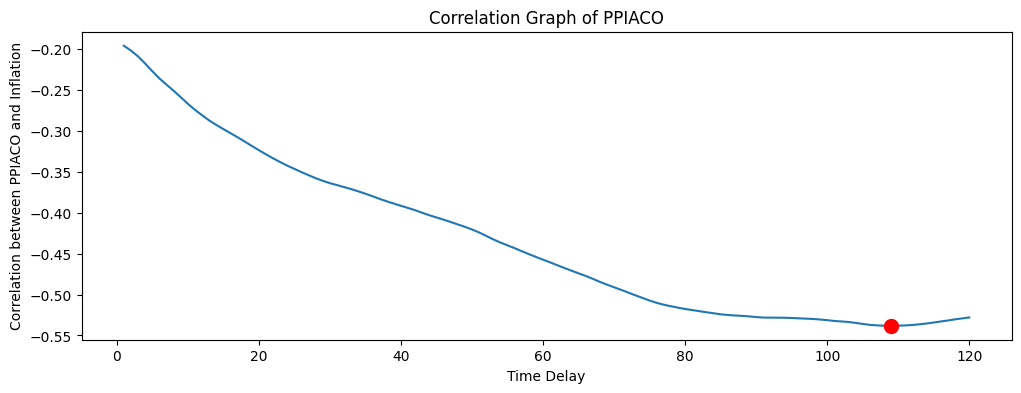


 Maximum Pearson Correlation of -0.5380755332884077 obtained with a time delay of 109 months





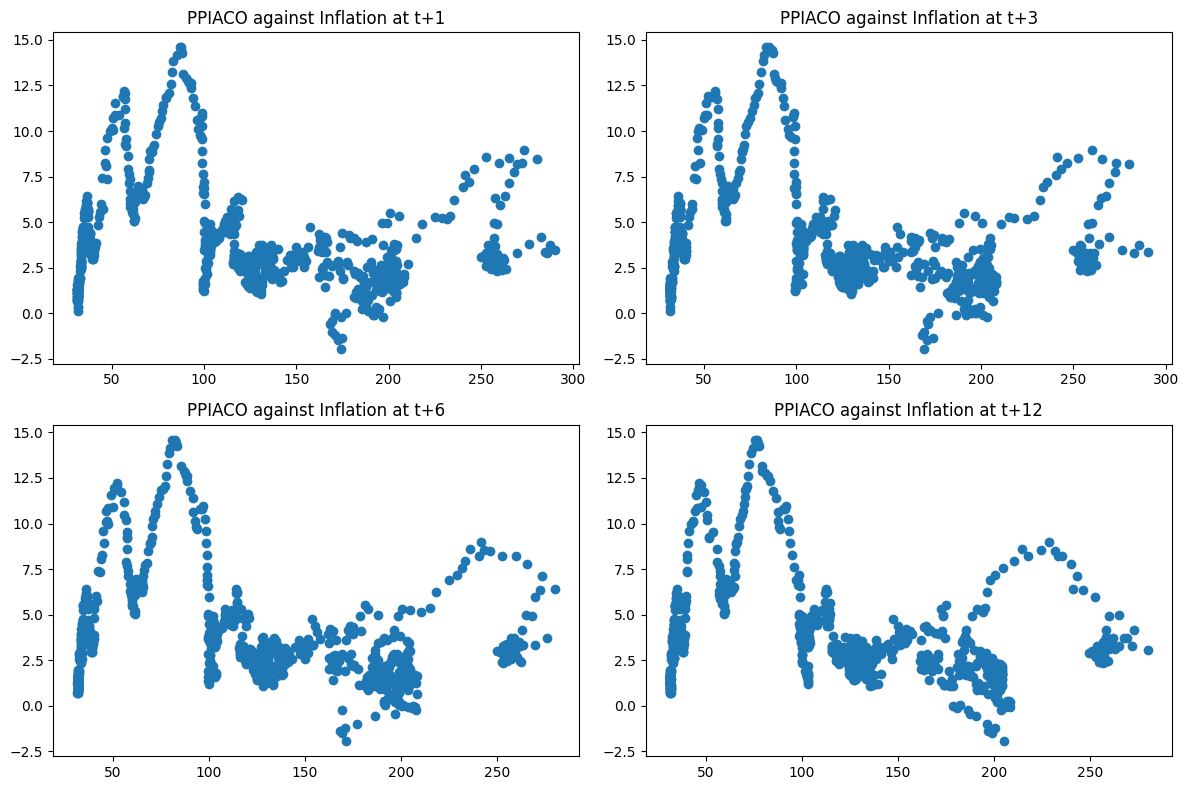



Lead-Lag Analysis of PAYEMS and Inflation


Pearson Correlation between PAYEMS and Inflation at t+1 : -0.21561632807591924

Pearson Correlation between PAYEMS and Inflation at t+3 : -0.22216685532995362

Pearson Correlation between PAYEMS and Inflation at t+6 : -0.23668509073657779

Pearson Correlation between PAYEMS and Inflation at t+12 : -0.25976525782689724




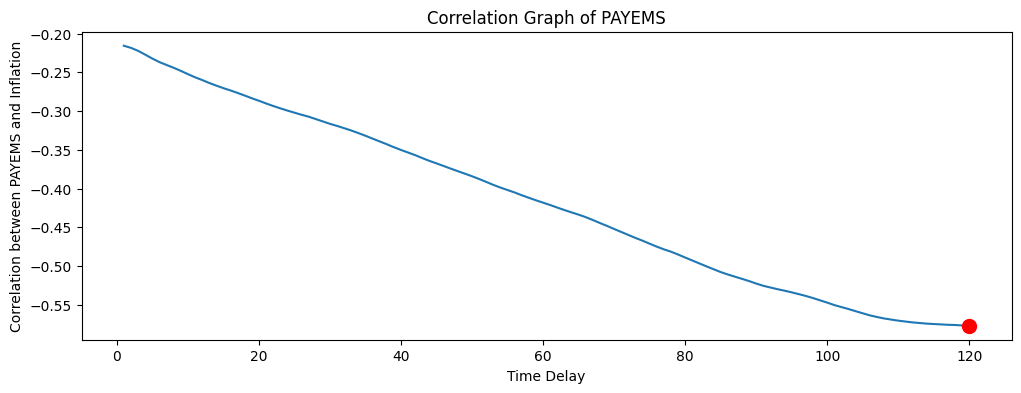


 Maximum Pearson Correlation of -0.5769601593096239 obtained with a time delay of 120 months





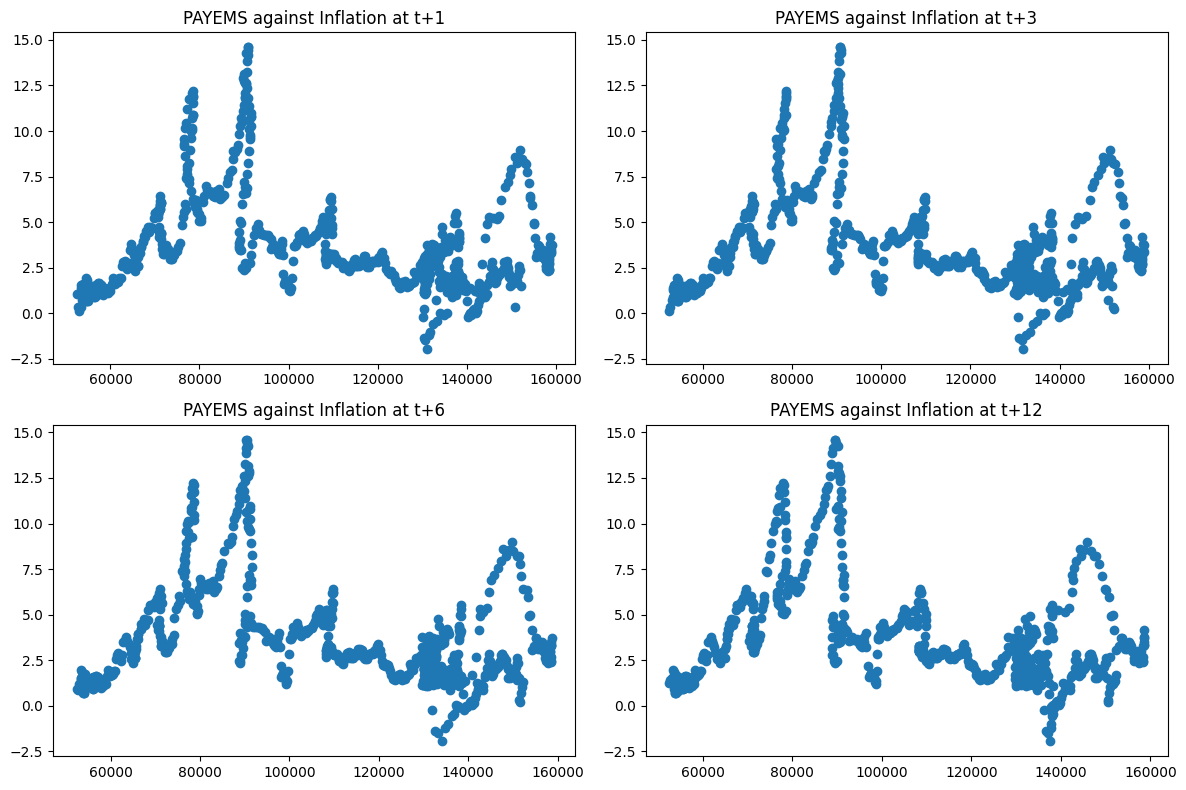



Lead-Lag Analysis of M2SL and Inflation


Pearson Correlation between M2SL and Inflation at t+1 : -0.1991730538508642

Pearson Correlation between M2SL and Inflation at t+3 : -0.19937075865929557

Pearson Correlation between M2SL and Inflation at t+6 : -0.2063536976497944

Pearson Correlation between M2SL and Inflation at t+12 : -0.2106600390155733




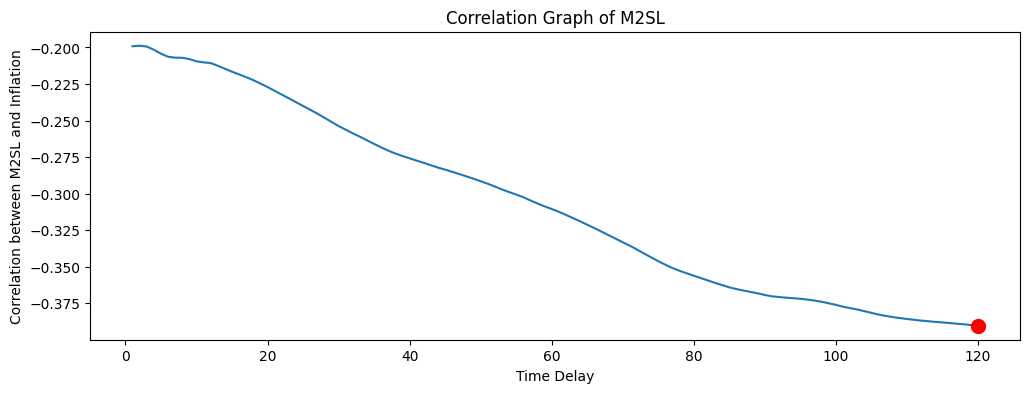


 Maximum Pearson Correlation of -0.3902755016197673 obtained with a time delay of 120 months





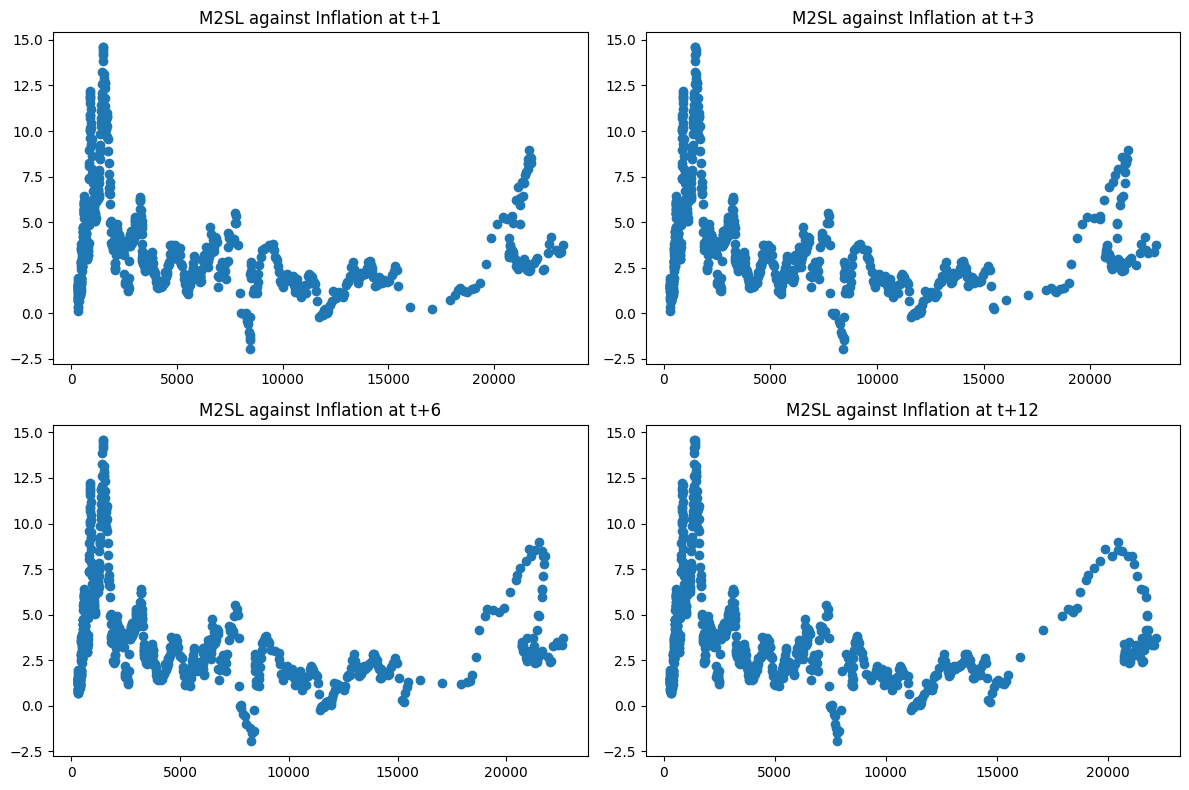



Lead-Lag Analysis of INDPRO and Inflation


Pearson Correlation between INDPRO and Inflation at t+1 : -0.24817064967480554

Pearson Correlation between INDPRO and Inflation at t+3 : -0.2511837740419441

Pearson Correlation between INDPRO and Inflation at t+6 : -0.26127383561468476

Pearson Correlation between INDPRO and Inflation at t+12 : -0.2797913094859121




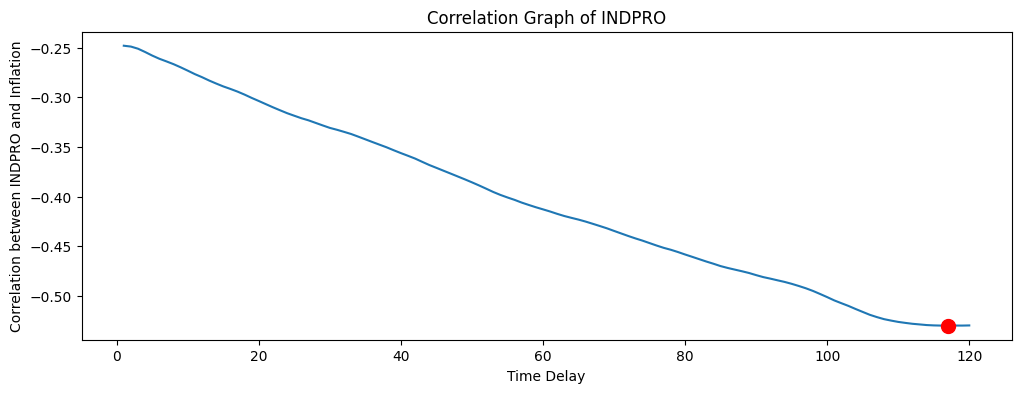


 Maximum Pearson Correlation of -0.5299026849390224 obtained with a time delay of 117 months





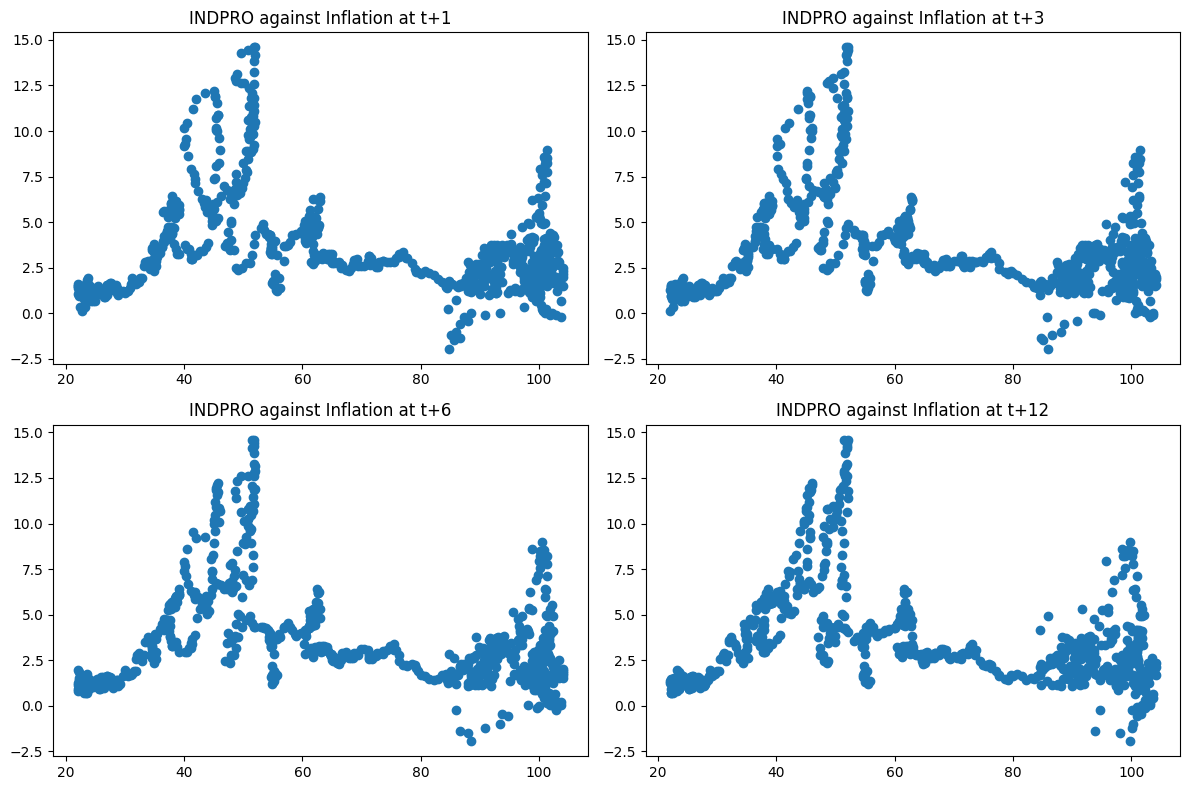



Lead-Lag Analysis of HOUST and Inflation


Pearson Correlation between HOUST and Inflation at t+1 : 0.13323794669403133

Pearson Correlation between HOUST and Inflation at t+3 : 0.17425300370653726

Pearson Correlation between HOUST and Inflation at t+6 : 0.23941565384422717

Pearson Correlation between HOUST and Inflation at t+12 : 0.3511701829956352




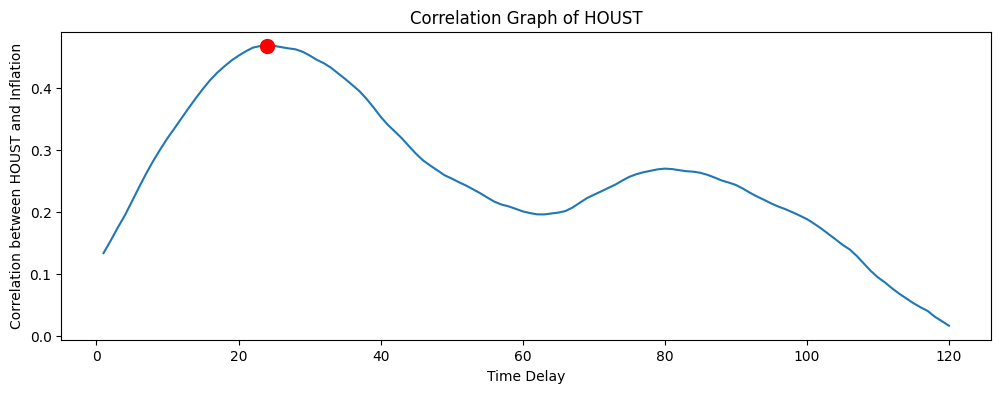


 Maximum Pearson Correlation of 0.4676229874257825 obtained with a time delay of 24 months





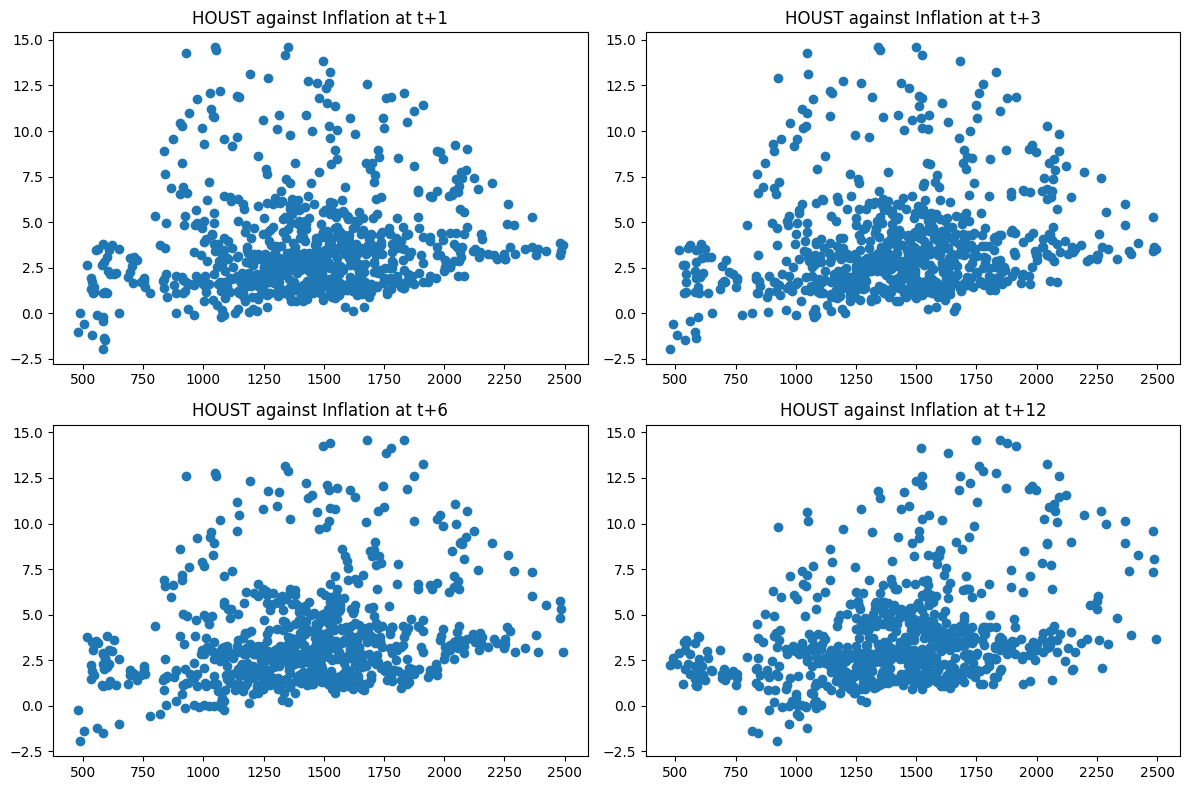



Lead-Lag Analysis of FEDFUNDS and Inflation


Pearson Correlation between FEDFUNDS and Inflation at t+1 : 0.6997102204069688

Pearson Correlation between FEDFUNDS and Inflation at t+3 : 0.6846481378311318

Pearson Correlation between FEDFUNDS and Inflation at t+6 : 0.6501519798145478

Pearson Correlation between FEDFUNDS and Inflation at t+12 : 0.5513065169294573




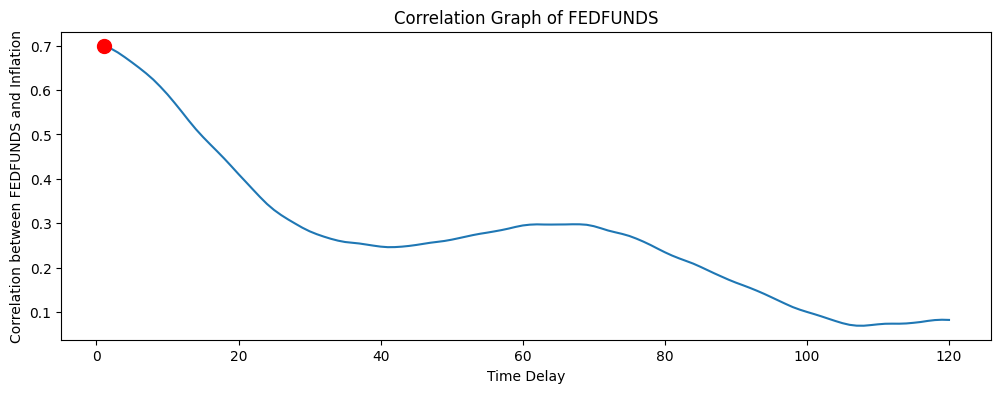


 Maximum Pearson Correlation of 0.6997102204069688 obtained with a time delay of 1 months





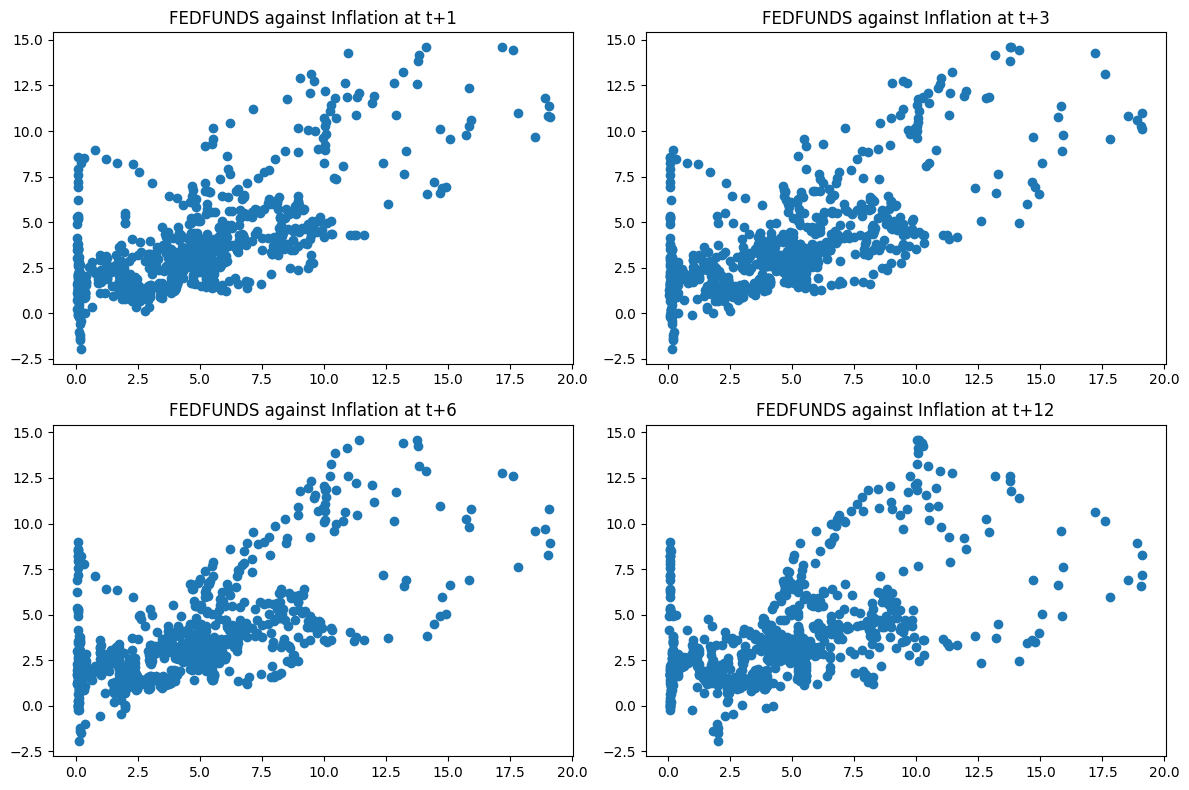



Lead-Lag Analysis of CPIAUCSL and Inflation


Pearson Correlation between CPIAUCSL and Inflation at t+1 : -0.27167289377268417

Pearson Correlation between CPIAUCSL and Inflation at t+3 : -0.2802887749575186

Pearson Correlation between CPIAUCSL and Inflation at t+6 : -0.29787277432450726

Pearson Correlation between CPIAUCSL and Inflation at t+12 : -0.32132598311430893




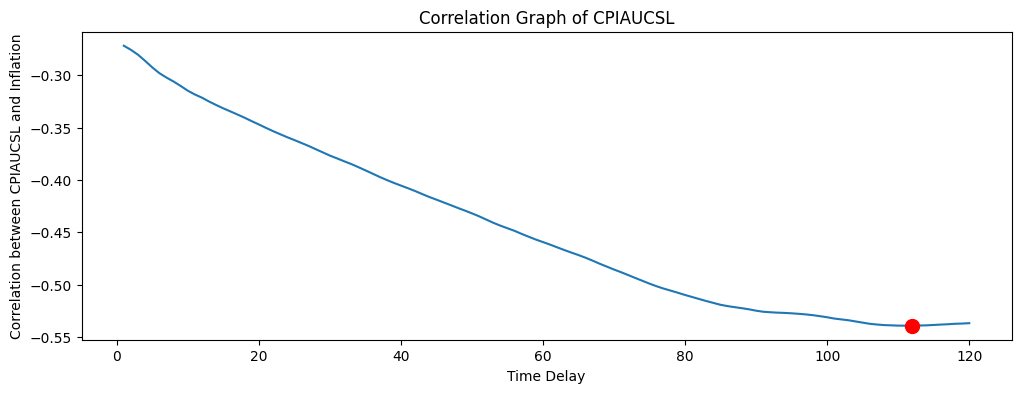


 Maximum Pearson Correlation of -0.5393568858536189 obtained with a time delay of 112 months





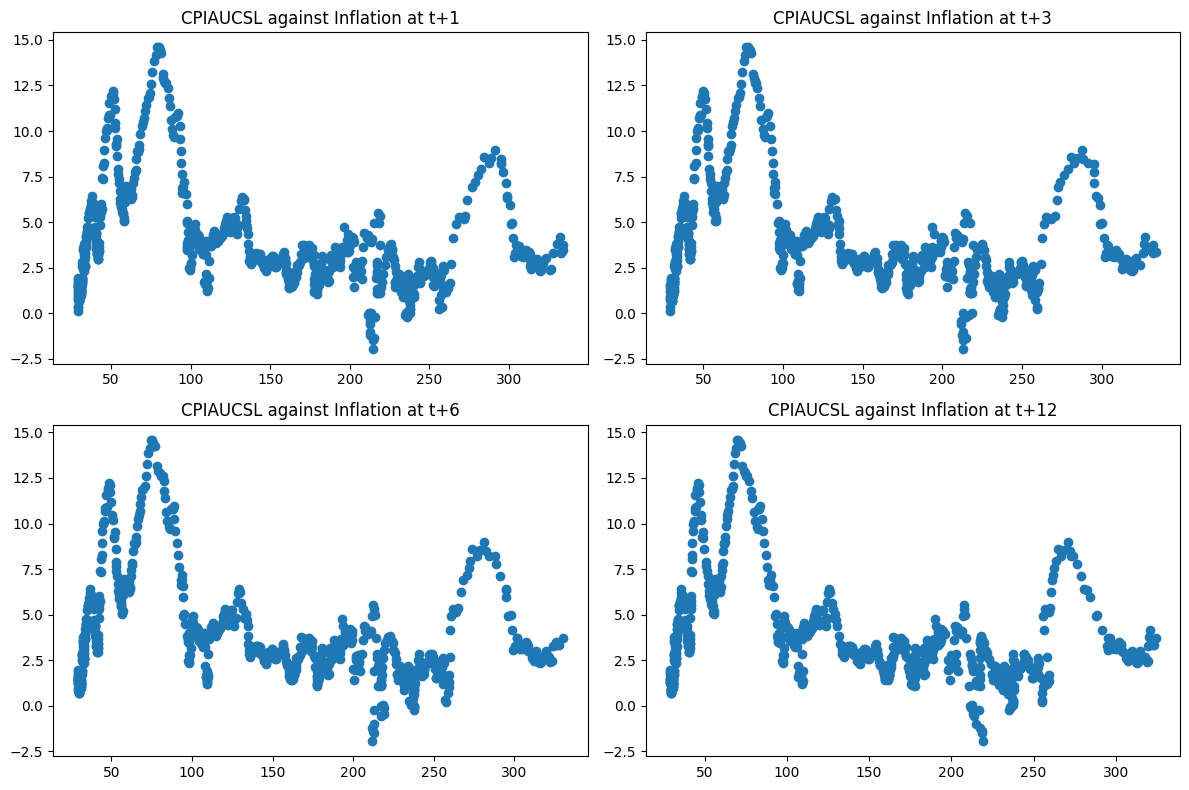



Lead-Lag Analysis of INFLATION and Inflation


Pearson Correlation between INFLATION and Inflation at t+1 : 0.9905525697978128

Pearson Correlation between INFLATION and Inflation at t+3 : 0.9547783388092222

Pearson Correlation between INFLATION and Inflation at t+6 : 0.8947116281720137

Pearson Correlation between INFLATION and Inflation at t+12 : 0.7336566407991374




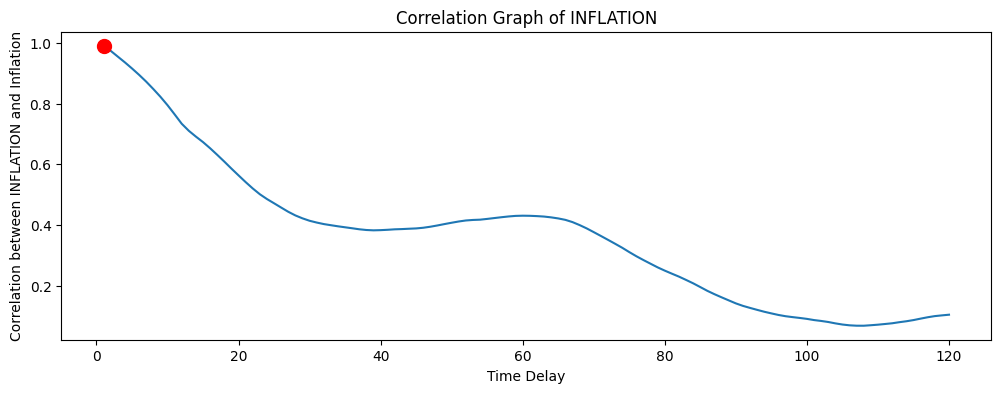


 Maximum Pearson Correlation of 0.9905525697978128 obtained with a time delay of 1 months





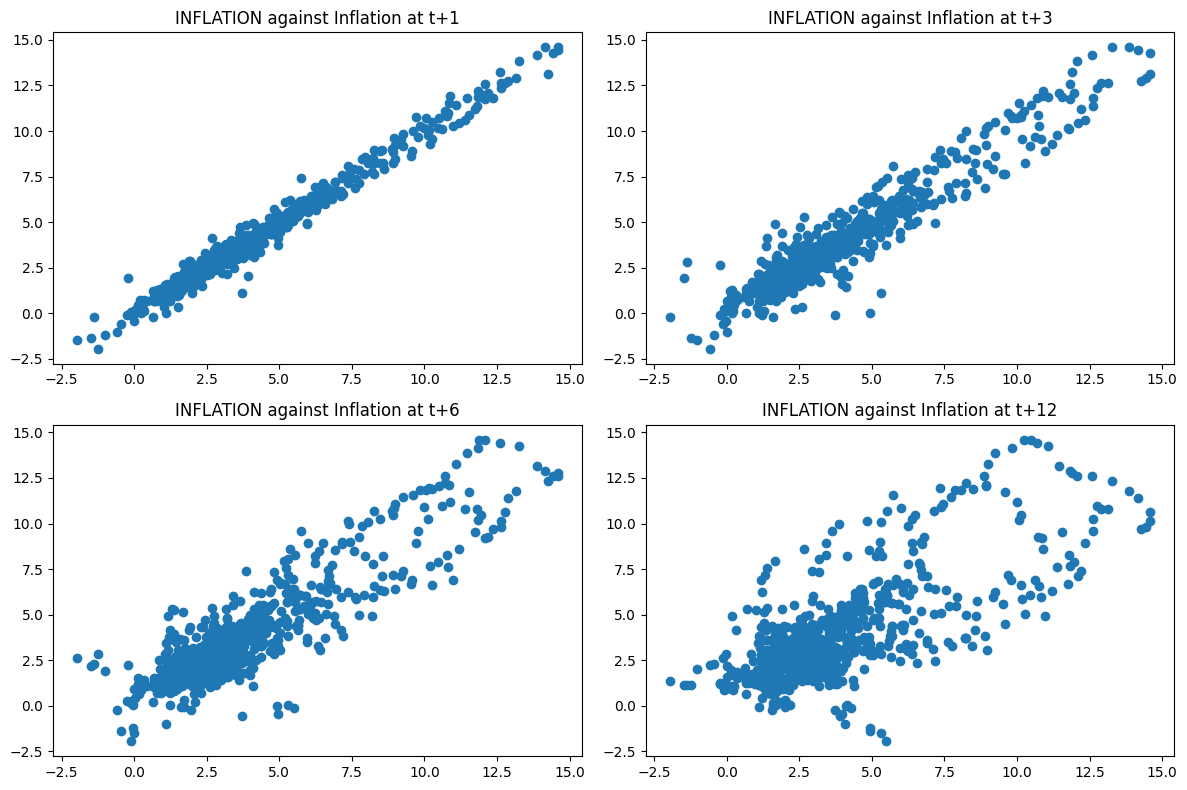



Lead-Lag Analysis of UNCHANGE and Inflation


Pearson Correlation between UNCHANGE and Inflation at t+1 : 0.040997259629119466

Pearson Correlation between UNCHANGE and Inflation at t+3 : 0.03102060793600949

Pearson Correlation between UNCHANGE and Inflation at t+6 : 0.009422893129050171

Pearson Correlation between UNCHANGE and Inflation at t+12 : -0.010417910798919735




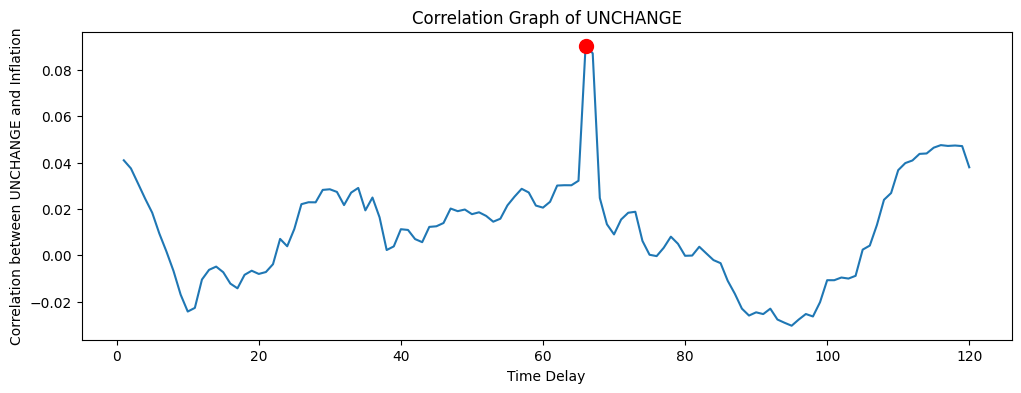


 Maximum Pearson Correlation of 0.090399418861481 obtained with a time delay of 66 months





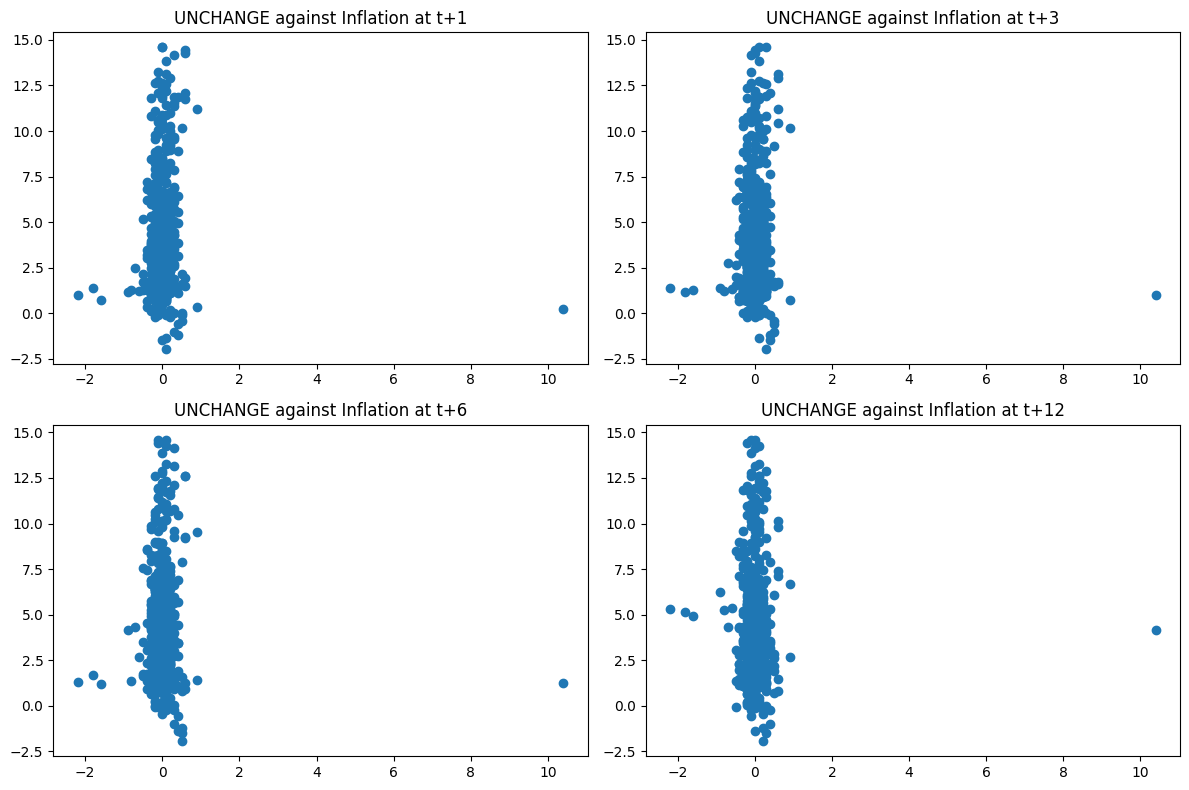



Lead-Lag Analysis of GROWIND and Inflation


Pearson Correlation between GROWIND and Inflation at t+1 : -0.07700723443851298

Pearson Correlation between GROWIND and Inflation at t+3 : -0.03099392990690123

Pearson Correlation between GROWIND and Inflation at t+6 : 0.022546911041853655

Pearson Correlation between GROWIND and Inflation at t+12 : 0.08674481166042607




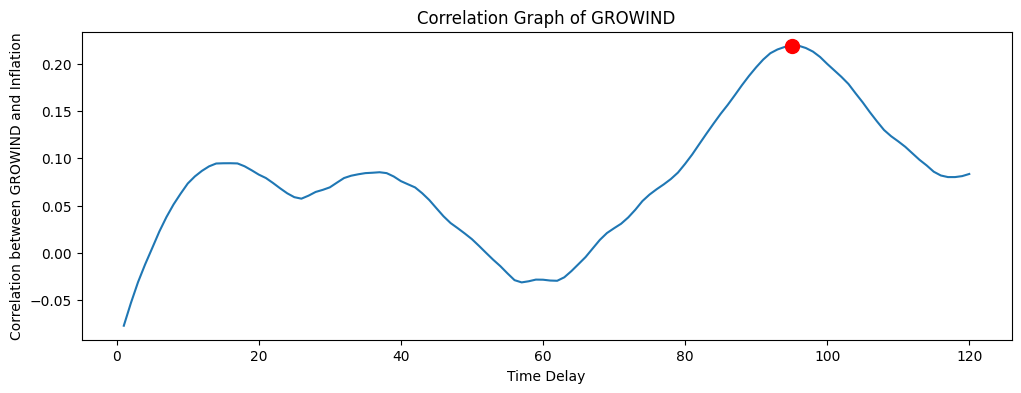


 Maximum Pearson Correlation of 0.21903124466782117 obtained with a time delay of 95 months





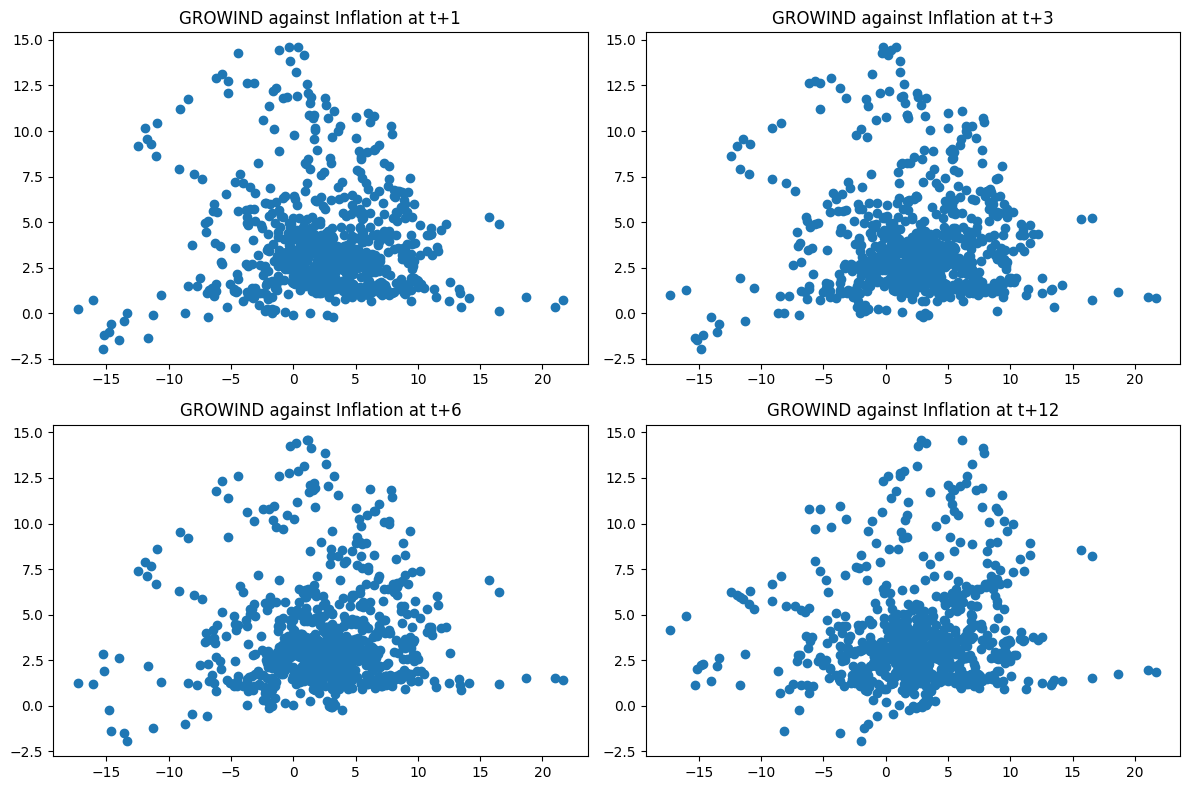



Lead-Lag Analysis of GROWPAY and Inflation


Pearson Correlation between GROWPAY and Inflation at t+1 : 0.17312903806560434

Pearson Correlation between GROWPAY and Inflation at t+3 : 0.19833347471323068

Pearson Correlation between GROWPAY and Inflation at t+6 : 0.23176670227963136

Pearson Correlation between GROWPAY and Inflation at t+12 : 0.22677811814919666




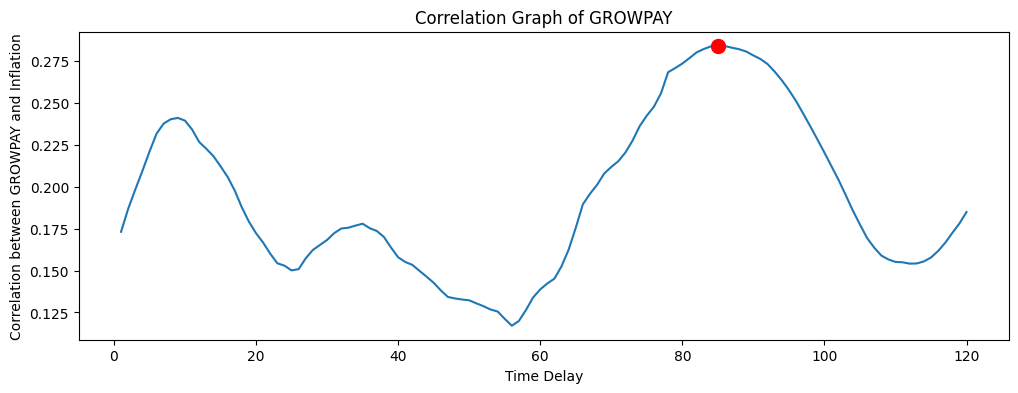


 Maximum Pearson Correlation of 0.28424911556737653 obtained with a time delay of 85 months





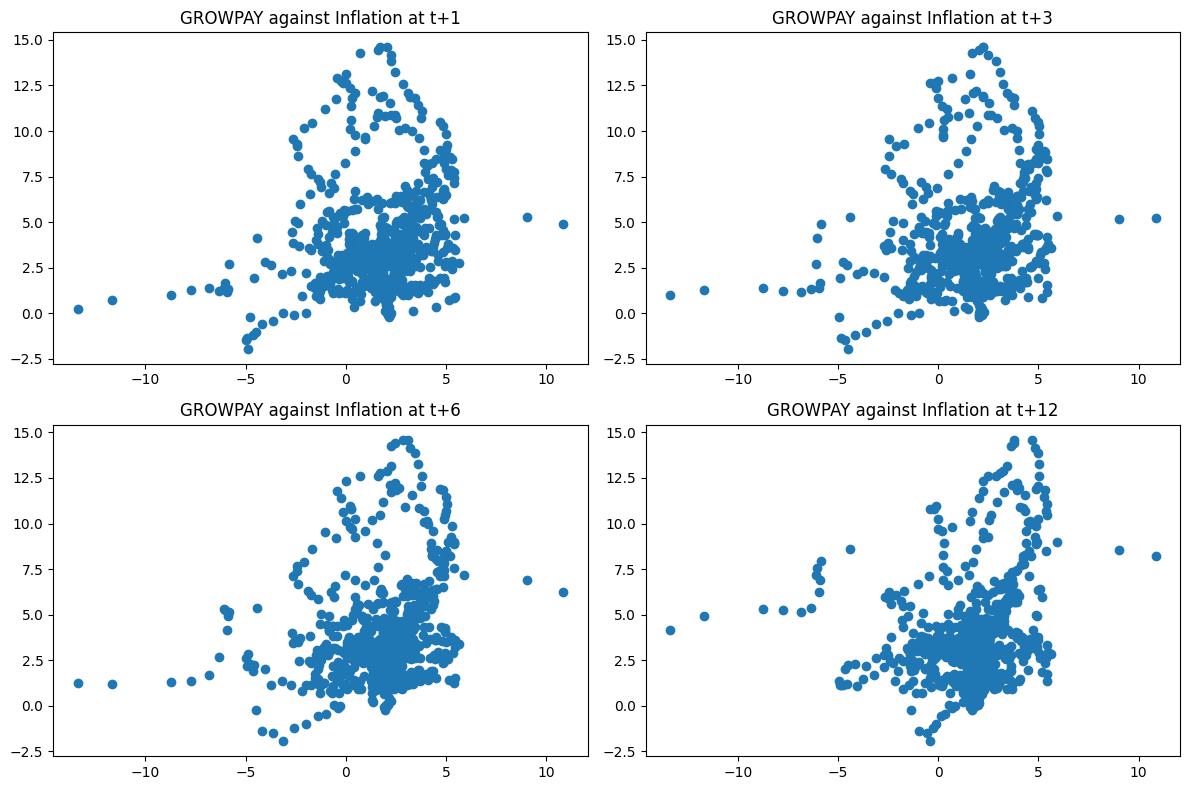



Lead-Lag Analysis of GROWPROD and Inflation


Pearson Correlation between GROWPROD and Inflation at t+1 : 0.7518263989257996

Pearson Correlation between GROWPROD and Inflation at t+3 : 0.7420315846263448

Pearson Correlation between GROWPROD and Inflation at t+6 : 0.7053467782163984

Pearson Correlation between GROWPROD and Inflation at t+12 : 0.5668733172815376




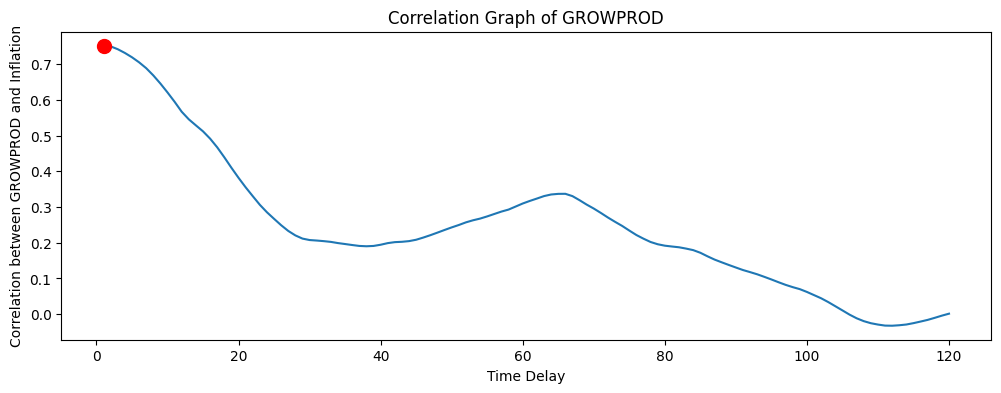


 Maximum Pearson Correlation of 0.7518263989257996 obtained with a time delay of 1 months





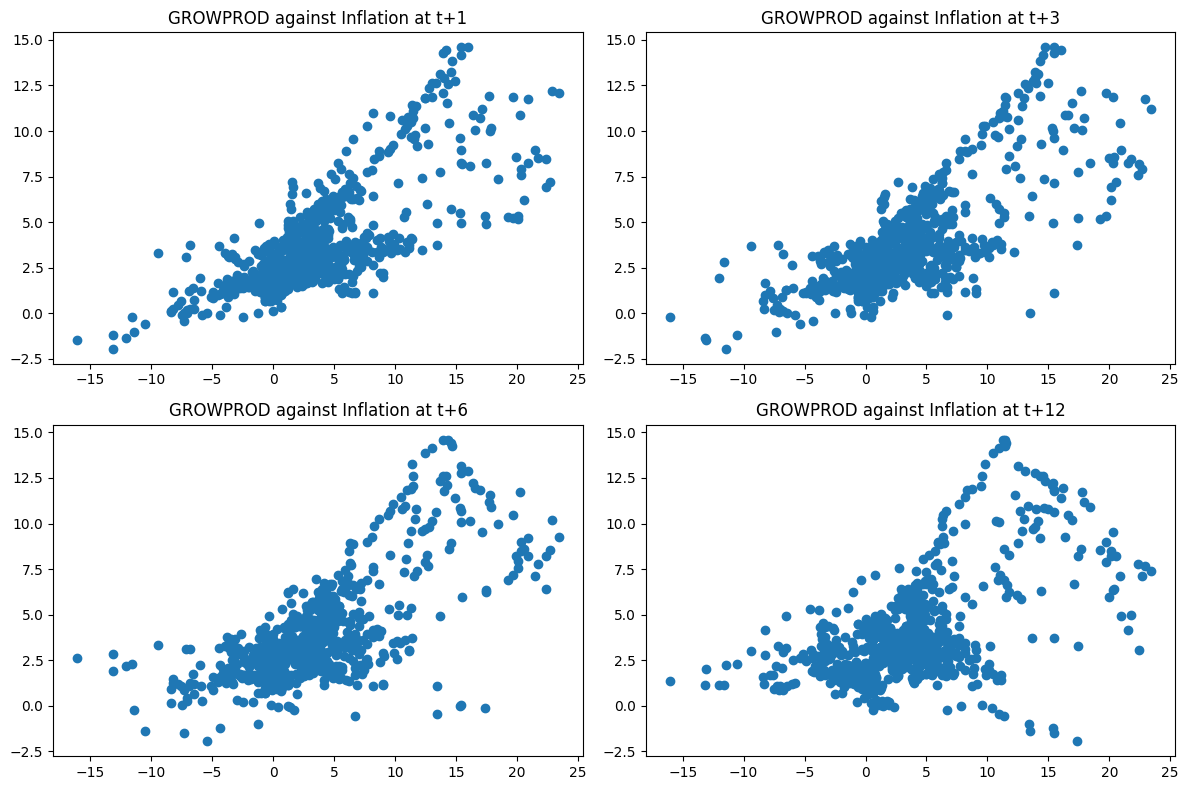

In [71]:
lead_lag_list = file_list = ['UNRATE.csv','PPIACO.csv','PAYEMS.csv','M2SL.csv','INDPRO.csv','HOUST.csv','FEDFUNDS.csv','CPIAUCSL.csv','INFLATION.csv','UNCHANGE.csv','GROWIND.csv','GROWPAY.csv','GROWPROD.csv']
for i in lead_lag_list:
  lead_lag(i)



Lead-Lag Analysis of DCOILWTICO and Inflation


Pearson Correlation between DCOILWTICO and Inflation at t+1 : 0.09762798471934453

Pearson Correlation between DCOILWTICO and Inflation at t+3 : -0.00745677570075047

Pearson Correlation between DCOILWTICO and Inflation at t+6 : -0.19256468432161897

Pearson Correlation between DCOILWTICO and Inflation at t+12 : -0.29097773505121666




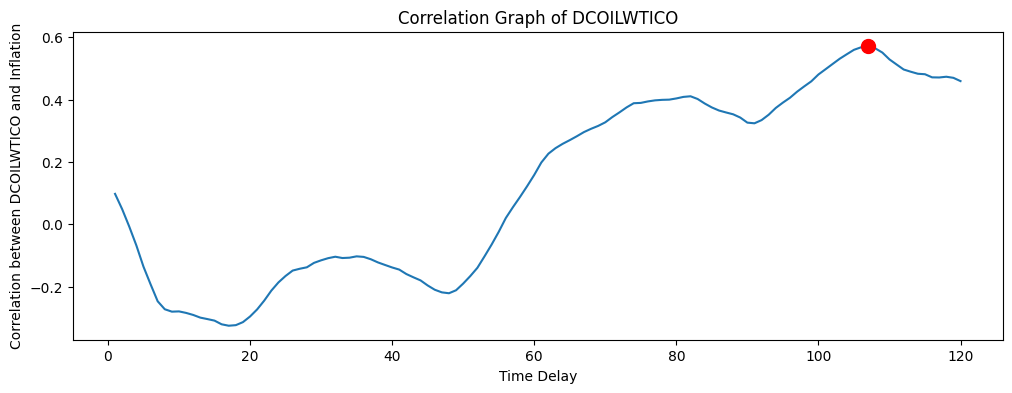


 Maximum Pearson Correlation of 0.5731020632740792 obtained with a time delay of 107 months





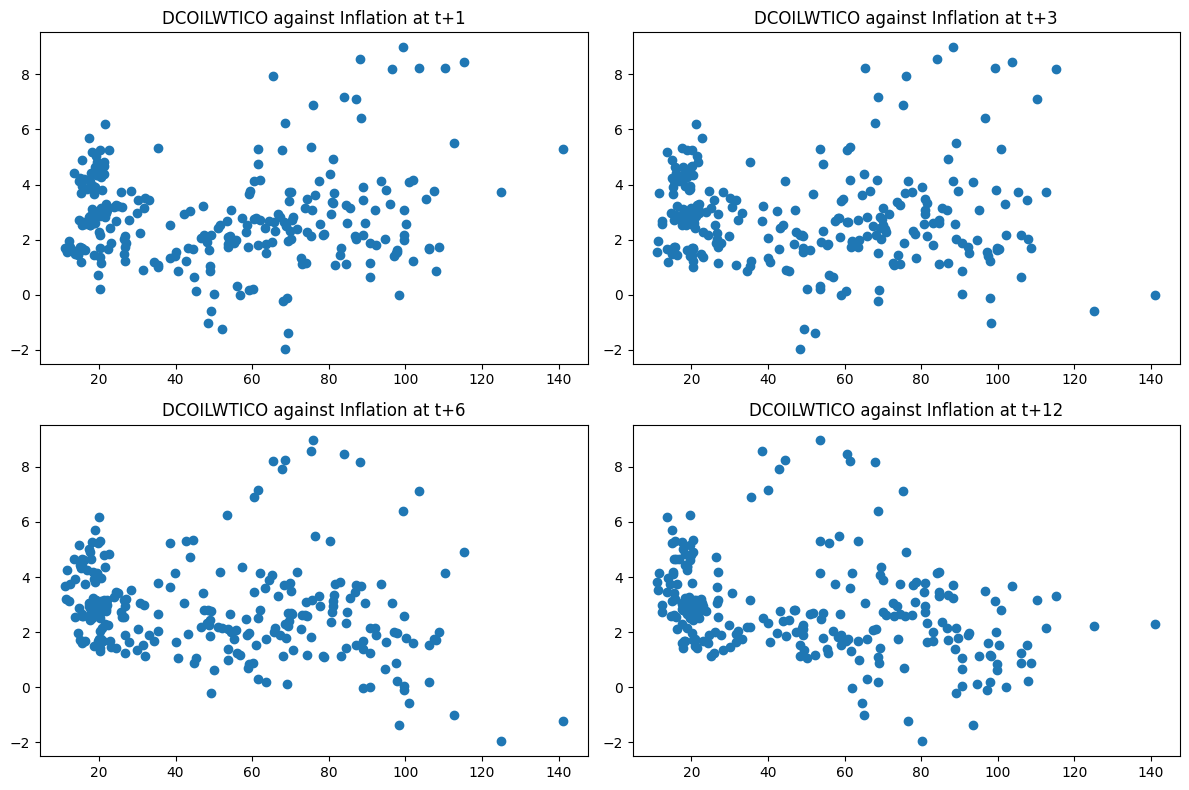



Lead-Lag Analysis of GROWOIL and Inflation


Pearson Correlation between GROWOIL and Inflation at t+1 : -0.06662844318734036

Pearson Correlation between GROWOIL and Inflation at t+3 : -0.03418442708186481

Pearson Correlation between GROWOIL and Inflation at t+6 : 0.06484328568349824

Pearson Correlation between GROWOIL and Inflation at t+12 : 0.01805753584355784




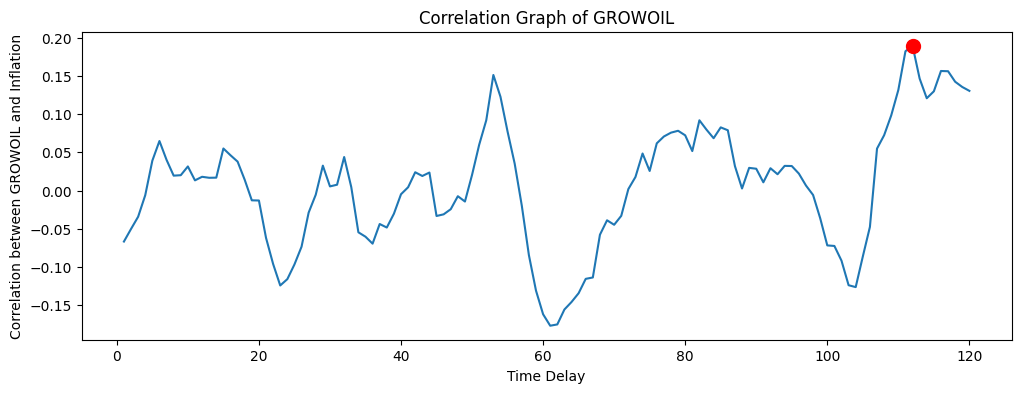


 Maximum Pearson Correlation of 0.18946333502597873 obtained with a time delay of 112 months





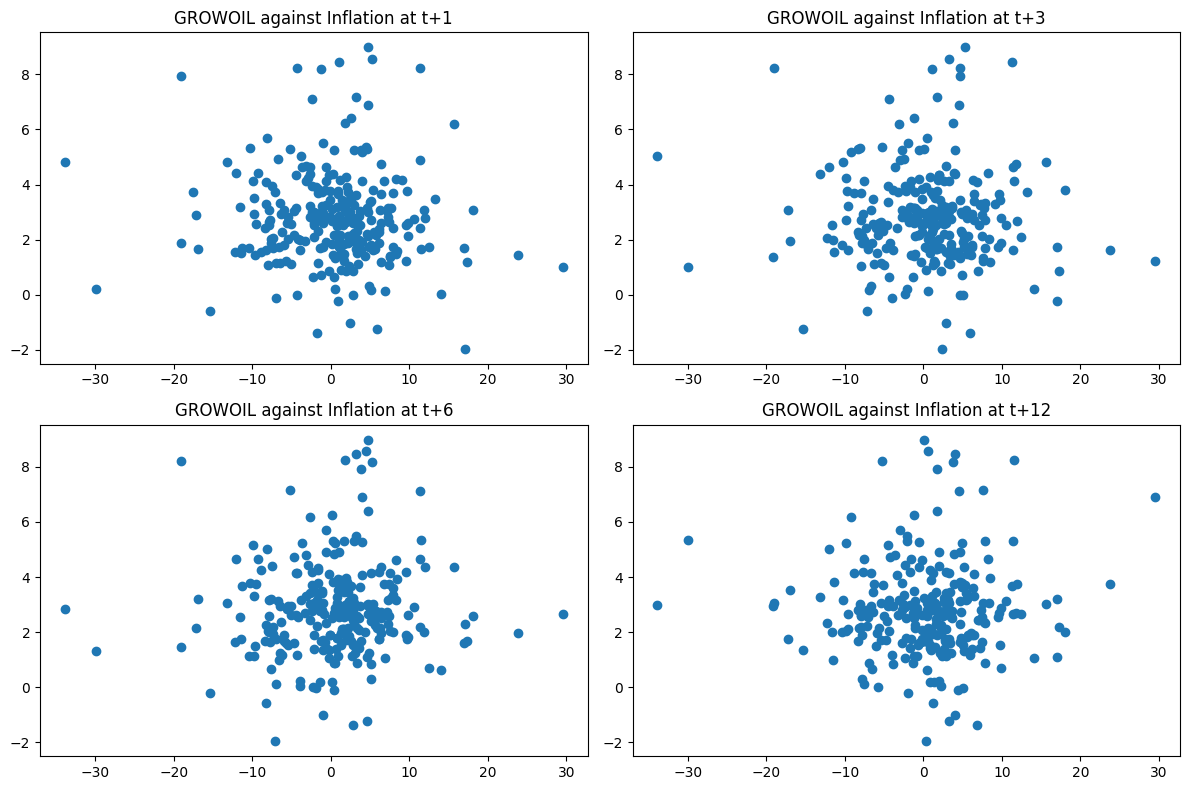



Lead-Lag Analysis of UMCSENT and Inflation


Pearson Correlation between UMCSENT and Inflation at t+1 : -0.2544349664822177

Pearson Correlation between UMCSENT and Inflation at t+3 : -0.17916914553356747

Pearson Correlation between UMCSENT and Inflation at t+6 : -0.06080308287983532

Pearson Correlation between UMCSENT and Inflation at t+12 : -0.012116038713579512




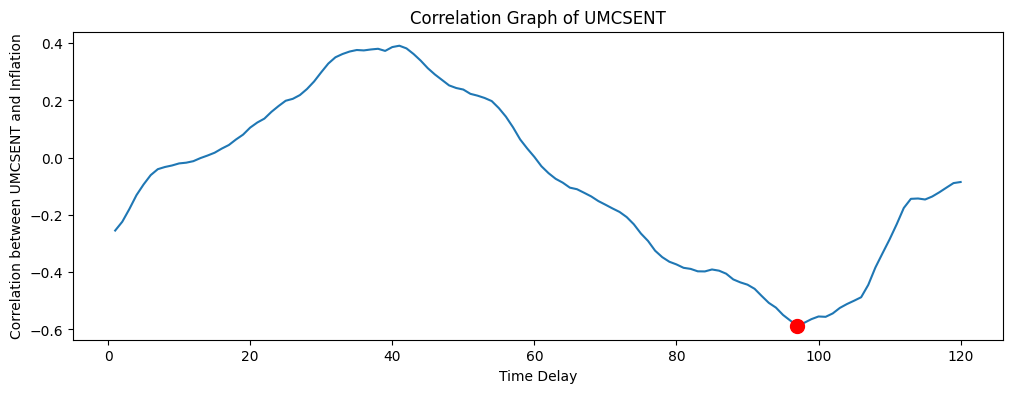


 Maximum Pearson Correlation of -0.5868831919259596 obtained with a time delay of 97 months





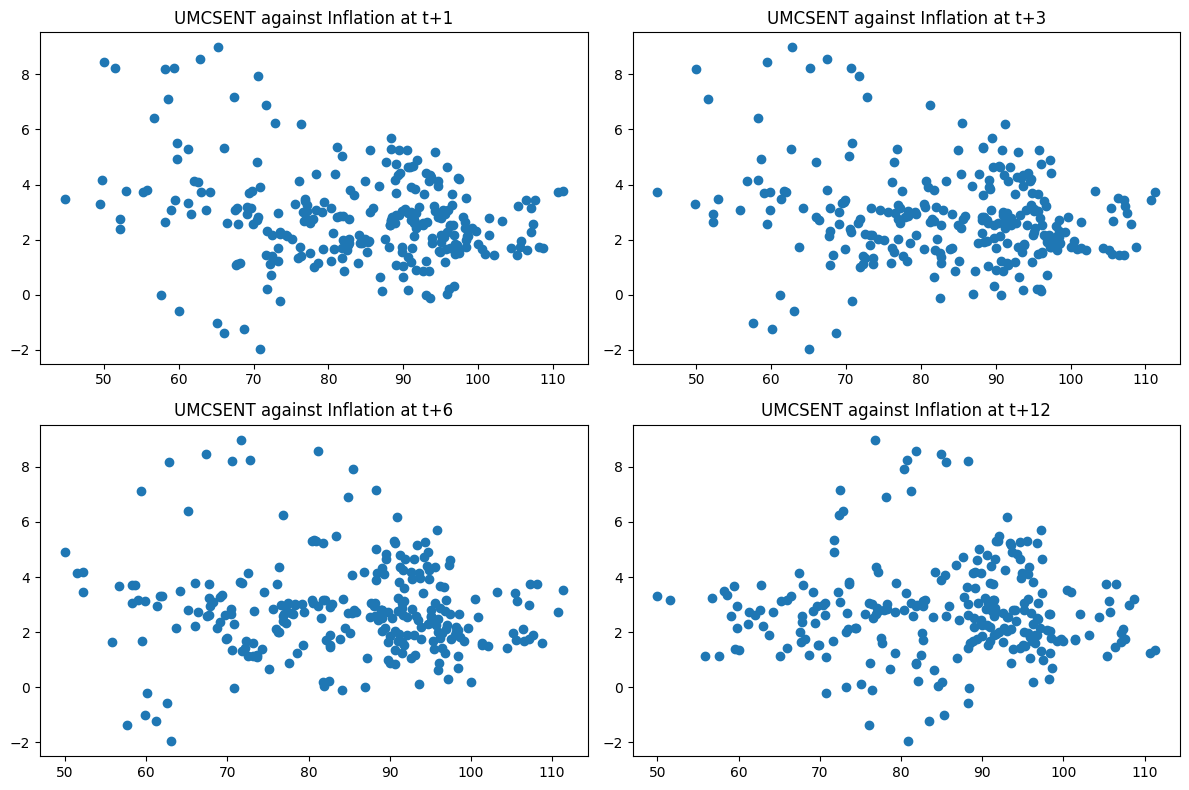



Lead-Lag Analysis of T10Y2Y and Inflation


Pearson Correlation between T10Y2Y and Inflation at t+1 : -0.3303795345219704

Pearson Correlation between T10Y2Y and Inflation at t+3 : -0.27506032546061987

Pearson Correlation between T10Y2Y and Inflation at t+6 : -0.2455184356408546

Pearson Correlation between T10Y2Y and Inflation at t+12 : -0.16340412671821614




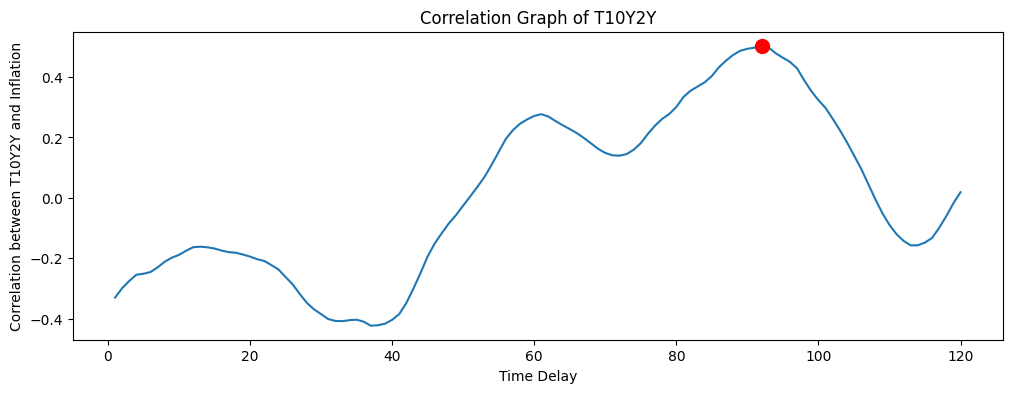


 Maximum Pearson Correlation of 0.5034584267277858 obtained with a time delay of 92 months





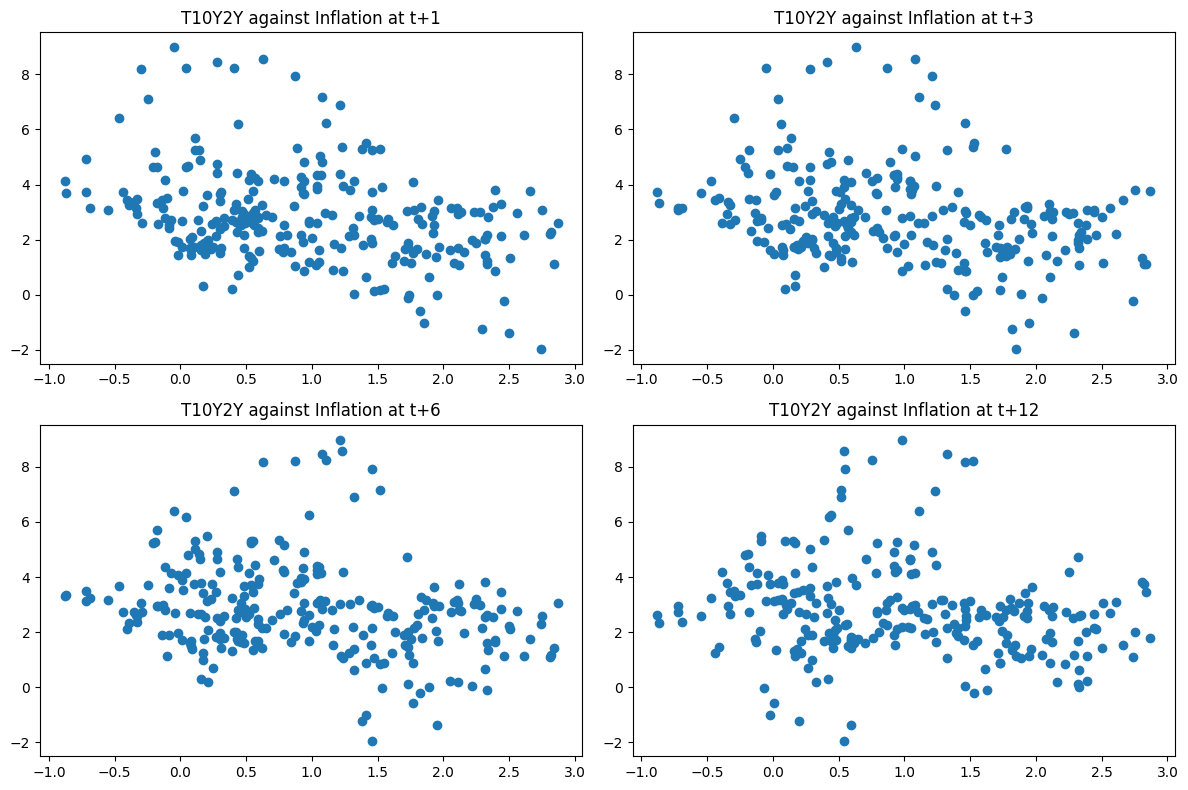

In [72]:
df_monthly = core_df
lead_lag_list = ['DCOILWTICO.csv','GROWOIL.csv','UMCSENT.csv','T10Y2Y.csv']
for i in lead_lag_list:
  lead_lag(i)

The EDA above stores values in variables named `min` and `max`, which shadow Python's built-in functions. They are deleted here so the built-ins work in the sections below.

In [73]:
del min, max

# **6. Data Preparation for Modelling**

Global variables: forecast horizons, split ratios, target and predictor series, and feature groupings.

In [74]:
#Declaring global variables

horizons = (1, 3, 6, 12)
train_ratio = 0.70
val_ratio = 0.15
TARGET_ID = "CPIAUCSL"
PREDICTOR_IDS = ["T10Y2Y","UNRATE","INDPRO","FEDFUNDS","PAYEMS","PPIACO","HOUST","DCOILWTICO","M2SL","UMCSENT"]
FRED_IDS = [TARGET_ID] + PREDICTOR_IDS

#Chosen variables to converted to YoY % growth
YoY_growth = ["INDPRO", "PAYEMS", "PPIACO", "DCOILWTICO", "M2SL", "HOUST"]

#These variables retained in raw levels - DCOILWTICO and HOUST are significant both in raw form and in rate of change form.
raw_features = ["T10Y2Y", "UNRATE", "FEDFUNDS", "HOUST", "DCOILWTICO", "UMCSENT"]

Loads all FRED series, aligns them to a monthly frequency, and trims to the common period.

In [79]:
def merge_fred(fred_ids):
    #Load all 11 FRED CSVs, align timestamps, and choose common period.
    merged_df = None

    for series_id in fred_ids:
        raw_data = pd.read_csv(f"Data/{series_id}.csv")
        date_col = raw_data.columns[0]
        val_col = raw_data.columns[1]

        df_temp = pd.DataFrame({
            "observation_date": pd.to_datetime(raw_data[date_col]).dt.to_period("M").dt.to_timestamp(),
            series_id: pd.to_numeric(raw_data[val_col], errors="coerce"),
        })

        #Aggregates to monthly mean where applicable
        df_temp = (df_temp.groupby("observation_date", as_index=False)[series_id].mean().sort_values("observation_date"))

        if merged_df is None:
            merged_df = df_temp
        else:
            merged_df = pd.merge(merged_df, df_temp, on="observation_date", how="outer")

    #Sorting by date order
    merged_df = (merged_df.sort_values("observation_date").set_index("observation_date").asfreq("MS"))
    
    merged_df.replace([np.inf, -np.inf], np.nan, inplace=True)
    #trimming the df to obtain common dates
    first = merged_df.apply(pd.Series.first_valid_index).max()
    last = merged_df.apply(pd.Series.last_valid_index).min()
    merged_df = merged_df.loc[first:last].reset_index()
    
    print("Common Period Coverage:")
    print(f"Start Date   : {merged_df['observation_date'].min().strftime('%d-%m-%Y')}")
    print(f"End Date     : {merged_df['observation_date'].max().strftime('%d-%m-%Y')}")
    print(f"Observations : {len(merged_df)}\n")

    return merged_df

Builds inflation, unemployment change and YoY growth features, plus the h-month-ahead targets.

In [80]:
def features_and_targets(df, h=(1, 3, 6, 12)):
    #Construct YoY inflation, predictors, and h-month ahead targets
    out = df.copy()

    #Calculating inflation
    out["inflation"] = 100.0*(out["CPIAUCSL"] / out["CPIAUCSL"].shift(12) - 1.0)

    #Calculating change in unemployment
    out["UNRATE_diff"] = out["UNRATE"] - out["UNRATE"].shift(1)

    #Calculating YoY growth rates for chosen features
    growth_cols = []
    for col in YoY_growth:
        g_col = f"{col}_yoy"
        out[g_col] = 100.0 * (out[col] / out[col].shift(12) - 1.0)
        growth_cols.append(g_col)

    feature_cols = ["inflation"] + raw_features + ["UNRATE_diff"] + growth_cols

    #Setting future inflation at t+n for n in {1, 3, 6, 12}
    target_cols = []
    for n in h:
        t_col = f"target_{n}m"
        out[t_col] = out["inflation"].shift(-n)
        target_cols.append(t_col)

    #Dropping initial 12 and final 12 months for YoY and target calculations
    required_cols = ["inflation"] + feature_cols + target_cols
    out = out.dropna(subset=required_cols).reset_index(drop=True)

    print("Date Range After Lag/Horizon Alignment:")
    print(f"Start Date   : {out['observation_date'].min().strftime('%m-%Y-%d')}")
    print(f"End Date     : {out['observation_date'].max().strftime('%m-%Y-%d')}")
    print(f"Observations : {len(out)} | Features: {len(feature_cols)}\n")

    return out, feature_cols, target_cols

Creates chronological train / validation / test splits with gaps, and fits the imputer and scaler on the training data only.

In [81]:
def chronological_splits(
    df,
    feature_cols,
    target_cols,
    t_ratio=0.70,
    v_ratio=0.15,
    split_gap=12,
):
    
    n = len(df)
    train_end = int(n * t_ratio)
    val_end = int(n * (t_ratio + v_ratio))

    #gap is used between splits so that train, val and test data are completely within their own boundaries (no peeking).
    te_gap = train_end - split_gap
    ve_gap = val_end - split_gap

    X_all = df[feature_cols].to_numpy(dtype=float)

    X_train_ini = X_all[:te_gap]
    X_val_ini = X_all[train_end:ve_gap]
    X_test_ini = X_all[val_end:]

    #Fit preprocessor on modified splits
    preprocessor = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    X_train = preprocessor.fit_transform(X_train_ini)
    X_val = preprocessor.transform(X_val_ini)
    X_test = preprocessor.transform(X_test_ini)

    y_train = {}
    y_val = {}
    y_test = {}

    for t in target_cols:
        values = df[t].to_numpy(dtype=float)
        y_train[t] = values[:te_gap]
        y_val[t]   = values[train_end:ve_gap]
        y_test[t]  = values[val_end:]

    dates = df["observation_date"].to_numpy()
    dates_train = dates[:te_gap]
    dates_val = dates[train_end:ve_gap]
    dates_test = dates[val_end:]

    splits = {
        "X_train": X_train,
        "X_val": X_val,
        "X_test": X_test,
        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test,
        "dates_train": dates_train,
        "dates_val": dates_val,
        "dates_test": dates_test,
        "feature_names": feature_cols,
        "target_names": target_cols,
        "preprocessor": preprocessor,
    }

    print("Chronological Splits:")
    print(f"Train : {X_train.shape} ({pd.Timestamp(dates_train[0]).strftime('%m-%Y')} to {pd.Timestamp(dates_train[-1]).strftime('%m-%Y')})")
    print(f"Val   : {X_val.shape} ({pd.Timestamp(dates_val[0]).strftime('%m-%Y')} to {pd.Timestamp(dates_val[-1]).strftime('%m-%Y')})")
    print(f"Test  : {X_test.shape} ({pd.Timestamp(dates_test[0]).strftime('%m-%Y')} to {pd.Timestamp(dates_test[-1]).strftime('%m-%Y')})")

    return splits

Runs the preprocessing pipeline.

In [82]:
# --- Execute Part 1 Pipeline ---
df_common = merge_fred(FRED_IDS)
df_model, FEATURE_COLS, TARGET_COLS = features_and_targets(df_common, h=horizons)
splits = chronological_splits(
    df_model,
    FEATURE_COLS,
    TARGET_COLS,
    t_ratio=train_ratio,
    v_ratio=val_ratio,
    split_gap = max(horizons)
)

Common Period Coverage:
Start Date   : 01-01-1986
End Date     : 01-09-2026
Observations : 489

Date Range After Lag/Horizon Alignment:
Start Date   : 01-1987-01
End Date     : 08-2025-01
Observations : 461 | Features: 14

Chronological Splits:
Train : (310, 14) (01-1987 to 10-2012)
Val   : (57, 14) (11-2013 to 07-2018)
Test  : (70, 14) (08-2019 to 08-2025)


Verifies the chronological split visually.

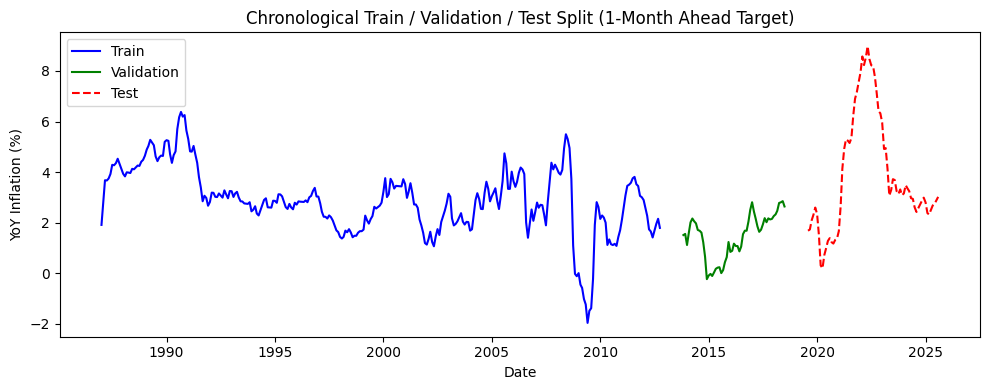

In [83]:
#Chronological Split Verification Plot 
plt.figure(figsize=(10, 4))
plt.plot(splits["dates_train"], splits["y_train"]["target_1m"], "b-", linewidth=1.5)
plt.plot(splits["dates_val"], splits["y_val"]["target_1m"], "g-", linewidth=1.5)
plt.plot(splits["dates_test"], splits["y_test"]["target_1m"], "r--", linewidth=1.5)
plt.xlabel("Date")
plt.ylabel("YoY Inflation (%)")
plt.title("Chronological Train / Validation / Test Split (1-Month Ahead Target)")
plt.legend(["Train", "Validation", "Test"], loc="best")
plt.tight_layout()
plt.show()

Inspecting the modelling dataframe and the scaled training features.

In [84]:
display(df_model)

,observation_date,CPIAUCSL,T10Y2Y,UNRATE,INDPRO,FEDFUNDS,PAYEMS,PPIACO,HOUST,DCOILWTICO,...,INDPRO_yoy,PAYEMS_yoy,PPIACO_yoy,DCOILWTICO_yoy,M2SL_yoy,HOUST_yoy,target_1m,target_3m,target_6m,target_12m
0,1987-01-01,111.400,0.858500,6.6,56.0882,6.43,100678.0,100.500,1774.0,18.654500,...,0.610066,1.970992,-2.616279,-19.296162,9.661816,-10.040568,1.914312,3.679853,3.926941,4.129264
1,1987-02-01,111.800,0.852632,6.6,56.8275,6.10,100919.0,101.000,1784.0,17.720556,...,2.656765,2.096169,-0.688299,15.209853,9.333333,-3.463203,2.841430,3.669725,4.288321,3.935599
2,1987-03-01,112.200,0.824091,6.6,56.9098,6.13,101164.0,101.200,1726.0,18.410526,...,3.542961,2.254028,0.897308,46.476960,8.700801,-7.995736,3.679853,3.747715,4.272727,3.832442
3,1987-04-01,112.700,0.998571,6.3,57.2701,6.37,101499.0,101.900,1614.0,18.669500,...,4.049323,2.399088,2.309237,45.444242,8.197490,-16.502845,3.669725,3.926941,4.355717,3.992902
4,1987-05-01,113.000,0.851500,6.3,57.6322,6.85,101728.0,102.600,1628.0,19.431053,...,4.552761,2.498791,2.600000,26.024919,7.270758,-12.189860,3.747715,4.288321,4.528986,3.982301
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
456,2025-02-01,319.679,0.241053,4.2,101.0993,4.33,158310.0,259.498,1491.0,71.533158,...,0.811986,0.681769,1.793462,-7.399244,3.278618,-4.115756,2.381981,2.377265,2.938592,2.434004
457,2025-03-01,319.785,0.310476,4.2,101.0404,4.33,158377.0,258.525,1346.0,68.239048,...,0.580245,0.578538,1.344597,-16.042413,3.421534,3.777949,2.325388,2.680454,3.022572,3.285958
458,2025-05-01,320.620,0.503810,4.3,100.9655,4.33,158498.0,258.678,1289.0,62.167619,...,0.101623,0.564692,1.317990,-22.314312,3.874677,-3.009782,2.680454,2.938592,2.696444,4.166615
459,2025-06-01,321.435,0.494500,4.1,101.4785,4.33,158478.0,260.491,1379.0,68.169000,...,0.579321,0.496528,1.788491,-14.540242,4.139225,4.628225,2.742618,3.022572,2.653304,3.463531


In [85]:
display(splits["X_train"])

array([[-1.18190361, -0.26209425,  0.38387815, ..., -0.94330455,
         1.8001284 , -0.47786508],
       [-0.75802392, -0.26854865,  0.38387815, ...,  0.08327145,
         1.66333642, -0.10427473],
       [-0.04276764, -0.29993919,  0.38387815, ...,  1.01348784,
         1.39992773, -0.36171983],
       ...,
       [-0.93421287,  0.34399652,  1.36144297, ..., -0.10050087,
         0.46459664,  1.73330467],
       [-0.73070944,  0.40815042,  1.16593001, ..., -0.05617665,
         0.71941679,  1.81389185],
       [-0.57181382,  0.40941842,  1.16593001, ..., -0.26001581,
         0.85310717,  2.93240309]], shape=(310, 14))

# **7. Regression Modelling**

In [86]:
X_train = splits["X_train"]
X_val = splits["X_val"]
X_test = splits["X_test"]
feature_names = splits["feature_names"]
target_names = splits["target_names"]

In [87]:
DEGREES = [1, 2]
ALPHAS = np.logspace(-4, 0, 9)
L1_RATIOS = [0.25, 0.5, 0.75]

MODELS = []

for degree in DEGREES:
    MODELS.append({
        "degree": degree,
        "model_type": "OLS"
    })

for degree in DEGREES:
    for alpha in ALPHAS:
        MODELS.append({
            "degree": degree,
            "model_type": "Ridge",
            "alpha": alpha
        })

for degree in DEGREES:
    for alpha in ALPHAS:
        MODELS.append({
            "degree": degree,
            "model_type": "Lasso",
            "alpha": alpha
        })

for degree in DEGREES:
    for alpha in ALPHAS:
        for l1_ratio in L1_RATIOS:
            MODELS.append({
                "degree": degree,
                "model_type": "ElasticNet",
                "alpha": alpha,
                "l1_ratio": l1_ratio
            })

In [88]:
def regression_pipeline(degree, model_type="OLS", alpha=None, l1_ratio=None):
    steps = [
        ("polynomial", PolynomialFeatures(degree=degree, include_bias=False))
    ]

    if model_type == "OLS":
        regression = LinearRegression()

    elif model_type == "Ridge":
        steps.append(("scaler", StandardScaler()))
        regression = Ridge(alpha=alpha)

    elif model_type == "Lasso":
        steps.append(("scaler", StandardScaler()))
        regression = Lasso(alpha=alpha)

    elif model_type == "ElasticNet":
        steps.append(("scaler", StandardScaler()))
        regression = ElasticNet(
            alpha=alpha,
            l1_ratio=l1_ratio
        )

    steps.append(("regression", regression))

    return Pipeline(steps)

In [89]:
validation_results = []
selected_models = {}

for target_name in target_names:
    y_train = splits["y_train"][target_name]
    y_val = splits["y_val"][target_name]

    best_rmse = np.inf

    for candidate in MODELS:
        model = regression_pipeline(
        degree=candidate["degree"],
        model_type=candidate["model_type"],
        alpha=candidate.get("alpha"),
        l1_ratio=candidate.get("l1_ratio")
        )
        model.fit(X_train, y_train)

        val_predictions = model.predict(X_val)

        val_mae = mean_absolute_error(y_val, val_predictions)
        val_rmse = np.sqrt(mean_squared_error(y_val, val_predictions))
        val_r2 = r2_score(y_val, val_predictions)

        validation_results.append({
            "target": target_name,
            "model": candidate["model_type"],
            "degree": candidate["degree"],
            "alpha": candidate.get("alpha"),
            "l1_ratio": candidate.get("l1_ratio"),
            "validation_MAE": val_mae,
            "validation_RMSE": val_rmse,
            "validation_R2": val_r2,
        })

        if val_rmse < best_rmse:
            best_rmse = val_rmse
            selected_models[target_name] = model


validation_results = pd.DataFrame(validation_results)

In [90]:
print("Validation Results")
print(
    validation_results
    .sort_values(["target", "validation_RMSE"])
    .to_string(index=False)
)

Validation Results
    target      model  degree    alpha  l1_ratio  validation_MAE  validation_RMSE  validation_R2
target_12m ElasticNet       1 0.100000      0.75        0.687519         0.835030       0.111128
target_12m ElasticNet       1 0.100000      0.50        0.734133         0.852624       0.073277
target_12m      Lasso       1 0.100000       NaN        0.673213         0.853362       0.071672
target_12m ElasticNet       1 0.100000      0.25        0.782284         0.881191       0.010138
target_12m ElasticNet       1 0.316228      0.25        0.759185         0.985292      -0.237556
target_12m ElasticNet       1 0.316228      0.50        0.819775         1.048142      -0.400474
target_12m ElasticNet       1 0.316228      0.75        0.853864         1.092541      -0.521634
target_12m      Lasso       2 0.000100       NaN        0.842528         1.098884      -0.539354
target_12m ElasticNet       2 0.000100      0.75        0.847586         1.103597      -0.552585
target_12m 

In [91]:
print("Best Models")

for target_name in target_names:
    p = selected_models[target_name].named_steps["regression"].get_params()
    print(f"{target_name}: alpha={p['alpha']:.4f}, l1_ratio={p['l1_ratio']}")

Best Models
target_1m: alpha=0.0316, l1_ratio=0.75
target_3m: alpha=0.1000, l1_ratio=0.5
target_6m: alpha=0.1000, l1_ratio=0.5
target_12m: alpha=0.1000, l1_ratio=0.75


In [92]:
test_results = []

for target_name in target_names:
    y_test = splits["y_test"][target_name]
    model = selected_models[target_name]
    predictions = model.predict(X_test)

    test_results.append({
        "Time Horizon": target_name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions),
    })

print("Performance on Test Data")
print(pd.DataFrame(test_results).to_string(index=False))

Performance on Test Data
Time Horizon      MAE     RMSE        R2
   target_1m 0.429034 0.571244  0.942024
   target_3m 1.112186 1.579855  0.549847
   target_6m 1.822360 2.691649 -0.321331
  target_12m 2.184340 3.116901 -1.052194


In [93]:
for target_name in target_names:
    feature_corr = []
    y_val = splits["y_val"][target_name]
    ols = LinearRegression().fit(X_train, splits["y_train"][target_name])
    for feature_index, feature_name in enumerate(feature_names):
        feature_corr.append(
            np.corrcoef(X_val[:, feature_index], y_val)[0, 1]
        )
        
    outp = pd.DataFrame({"feature":feature_names, "correlation" : feature_corr, "absolute_correlation":np.abs(feature_corr), "absolute_ols_coef": np.abs(ols.coef_)}).sort_values("absolute_ols_coef", ascending=False)
    print(f"****{target_name}****")
    print(outp.to_string(index=False))

****target_1m****
       feature  correlation  absolute_correlation  absolute_ols_coef
     inflation     0.948706              0.948706           1.019249
      FEDFUNDS     0.685034              0.685034           0.415121
        T10Y2Y    -0.318748              0.318748           0.188187
    DCOILWTICO     0.276591              0.276591           0.176962
DCOILWTICO_yoy     0.928558              0.928558           0.171458
         HOUST     0.376858              0.376858           0.148552
        UNRATE    -0.387131              0.387131           0.133848
    PAYEMS_yoy    -0.829634              0.829634           0.096573
    PPIACO_yoy     0.898142              0.898142           0.067844
   UNRATE_diff    -0.009742              0.009742           0.021545
       UMCSENT     0.174522              0.174522           0.010047
     HOUST_yoy    -0.146667              0.146667           0.009509
    INDPRO_yoy     0.433066              0.433066           0.008396
      M2SL_yoy  